# Experimento histórico de combinação por regime operacional

Este notebook conserva uma execução anterior à rodada de 29/10/2026. Não foi reexecutado nesta revisão bibliográfica e não integra a cadeia de resultados principais recém-validada para o artigo. Código, contadores e saídas históricas foram preservados; as notas e referências foram acrescentadas posteriormente para identificar os procedimentos.

## Fundamentação e escolhas do experimento

Friedman (2001) e Chen e Guestrin (2016) fundamentam os modelos de árvores. Cerqueira, Torgo e Mozetič (2020) orientam a atenção à avaliação temporal, e Cawley e Talbot (2010), aos efeitos do processo de seleção. Os períodos, a janela histórica e o percentil 90 são decisões deste projeto; a cronologia de cada ajuste não elimina a consulta anterior a resultados de 2025.

Jacobs et al. (1991) apresentam especialistas com alocação aprendida. Aqui a relação é apenas conceitual: a seleção entre A e B é uma regra determinística definida por regime; não há rede de alocação treinada nem reprodução do algoritmo desses autores.

Künsch (1989) fundamenta reamostragem de blocos para sequências dependentes sob hipóteses de estacionariedade e regularidade. O código deste notebook usa uma adaptação própria: blocos de semana-calendário, não sobrepostos, estratificados por ano, com tamanhos variáveis de horas ON, 2.000 réplicas e intervalo percentil. Não reproduz literalmente o bootstrap de blocos móveis do artigo, não demonstra suas hipóteses para a Iatan e não garante cobertura nominal de 95%. Fração de réplicas positivas não é valor-p.

MAE/RMSE seguem as definições discutidas por Hyndman e Koehler (2006); as métricas de implementação são descritas por Scikit-learn (2025, documentação 1.8). Datas, desempenho e intervalos abaixo são registros históricos, sem nova confirmação nesta revisão.


In [5]:
# ============================================================
# NOTEBOOK 03A.06
# MODELO HÍBRIDO SENSÍVEL AO REGIME OPERACIONAL
# ============================================================
#
# PERGUNTA DE PESQUISA
# ------------------------------------------------------------
#
# Um modelo híbrido sensível ao regime operacional, que utiliza
# informações de trajetória durante rampas intensas e a carga
# instantânea nas demais condições, melhora a previsão horária
# de CO2 em relação ao uso isolado dos Cenários A e B?
#
#
# MOTIVAÇÃO
# ------------------------------------------------------------
#
# O Notebook 03A.05 mostrou dois resultados aparentemente
# contraditórios:
#
# 1. Globalmente, o Cenário A foi melhor.
#
#    A:
#        apenas carga instantânea
#
#    B:
#        carga + trajetória operacional
#
#
# 2. Em rampas intensas, o Cenário B foi claramente melhor.
#
#
# Isso sugere que não é necessário escolher um único conjunto
# de features para todas as condições de operação.
#
#
# A hipótese deste notebook é:
#
#     usar A quando a trajetória acrescenta pouca informação;
#
#     usar B quando a unidade está em regime suficientemente
#     dinâmico para que a trajetória se torne relevante.
#
#
# O resultado será um modelo híbrido:
#
#
#                     ┌── Cenário B, se rampa intensa
#     observação ─────┤
#                     └── Cenário A, caso contrário
#
#
# Esse tipo de arquitetura pode ser interpretado como uma forma
# simples e explícita de "mixture of experts":
#
#     especialista A = regime predominantemente regular
#
#     especialista B = regime dinâmico
#
#     gate           = regra que escolhe o especialista
#
#
# IMPORTANTE
# ------------------------------------------------------------
#
# O gate NÃO será inicialmente treinado por outro algoritmo de
# machine learning.
#
# Começaremos com uma regra operacional simples, transparente
# e fisicamente interpretável.
#
#
# REGRA INICIAL
# ------------------------------------------------------------
#
#     SE:
#
#         |delta_load_1h| >= P90 do conjunto de TREINAMENTO
#
#     ENTÃO:
#
#         utilizar previsão do Cenário B
#
#     SENÃO:
#
#         utilizar previsão do Cenário A
#
#
# O percentil será sempre calculado com dados anteriores ao
# período que estiver sendo previsto.
#
# Portanto, o teste nunca será utilizado para determinar o
# limiar de rampa.
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES
# ============================================================

from pathlib import Path

import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

from xgboost import XGBRegressor


warnings.filterwarnings(
    "ignore"
)


# ============================================================
# 2. REPRODUTIBILIDADE
# ============================================================
#
# Utilizamos a mesma semente adotada nos experimentos
# anteriores.
#
# Isso reduz variações decorrentes de componentes aleatórios do
# XGBoost e facilita a reprodução dos resultados.
# ============================================================

RANDOM_STATE = 42


# ============================================================
# 3. MONTAR O GOOGLE DRIVE
# ============================================================
#
# Todo o projeto permanece na mesma estrutura utilizada pelos
# notebooks anteriores.
# ============================================================

try:

    from google.colab import drive

    drive.mount(
        "/content/drive"
    )

except Exception as exc:

    print(
        "Google Drive não montado automaticamente."
    )

    print(
        "Mensagem:",
        exc
    )


# ============================================================
# 4. DIRETÓRIO PRINCIPAL DO PROJETO
# ============================================================

ROOT = Path(

    "/content/drive/MyDrive/co2-cems-thermal-modeling"

)


DATA_INTERIM = (

    ROOT
    /
    "data"
    /
    "interim"

)


TABLES = (

    ROOT
    /
    "outputs"
    /
    "tables"

)


FIGURES = (

    ROOT
    /
    "outputs"
    /
    "figures"

)


REPORTS = (

    ROOT
    /
    "outputs"
    /
    "reports"

)


# ============================================================
# 5. DIRETÓRIOS DOS EXPERIMENTOS 03A.05 E 03A.06
# ============================================================
#
# O 03A.06 reaproveita a base auditada e pareada construída no
# notebook anterior.
#
# Não reconstruiremos silenciosamente as features.
#
# Isso é importante porque queremos utilizar exatamente a mesma
# representação dos Cenários A e B já validada no 03A.05.
# ============================================================

PREVIOUS_EXPERIMENT_DIR = (

    DATA_INTERIM
    /
    "03A05_trajectory_history"

)


EXPERIMENT_DIR = (

    DATA_INTERIM
    /
    "03A06_regime_hybrid"

)


EXPERIMENT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


TABLES.mkdir(

    parents=True,

    exist_ok=True

)


FIGURES.mkdir(

    parents=True,

    exist_ok=True

)


REPORTS.mkdir(

    parents=True,

    exist_ok=True

)


# ============================================================
# 6. ARQUIVO PRINCIPAL DE ENTRADA
# ============================================================
#
# Esta base foi produzida no 03A.05.
#
# Ela já contém:
#
# - apenas observações elegíveis para A e B;
#
# - exclusão das horas iniciais de 2011 cuja idade de startup
#   era desconhecida;
#
# - exclusão das observações afetadas pela carga ausente de
#   2019;
#
# - as sete features do Cenário B;
#
# - os mesmos timestamps disponíveis para os dois cenários.
#
#
# Portanto, esta é a base apropriada para uma comparação
# estritamente pareada.
# ============================================================

COMMON_SAMPLE_PATH = (

    PREVIOUS_EXPERIMENT_DIR
    /
    "03A05_amostra_comum_A_B.parquet"

)


# ============================================================
# 7. IDENTIFICAÇÃO DA UNIDADE
# ============================================================

EXPECTED_FACILITY_ID = 6065

EXPECTED_UNIT_ID = "2"


# ============================================================
# 8. VARIÁVEL-ALVO
# ============================================================

TARGET = "CO2 Mass (short tons)"


# ============================================================
# 9. CENÁRIO A
# ============================================================
#
# Representação mínima:
#
#     CO2(t) = f(P(t))
# ============================================================

FEATURES_A = [

    "load_current_mw"

]


# ============================================================
# 10. CENÁRIO B
# ============================================================
#
# Representação com memória operacional:
#
#     carga atual
#     carga anterior
#     variação de carga
#     magnitude da variação
#     média anterior de 3 h
#     estado operacional anterior
#     tempo desde startup
# ============================================================

FEATURES_B = [

    "load_current_mw",

    "load_lag_1h",

    "delta_load_1h",

    "abs_delta_load_1h",

    "load_mean_previous_3h",

    "operating_time_lag_1h",

    "hours_since_startup"

]


# ============================================================
# 11. DEFINIÇÃO DO GATE HÍBRIDO
# ============================================================
#
# Nesta primeira formulação, o gate utiliza apenas a magnitude
# da variação horária da carga.
#
#
# Rampa intensa:
#
#     abs_delta_load_1h >= P90 do TREINO
#
#
# Escolhemos o P90 porque:
#
# - mantém o critério de rampa intensa utilizado nas análises
#   anteriores;
#
# - identifica a cauda superior das mudanças de carga;
#
# - não exige escolher arbitrariamente um valor fixo em MW/h;
#
# - adapta o limiar à distribuição operacional disponível no
#   conjunto de treinamento.
#
#
# Muito importante:
#
# o P90 será recalculado exclusivamente com o conjunto de treino
# de cada experimento.
#
# Nunca utilizaremos o teste para calcular esse limiar.
# ============================================================

RAMP_QUANTILE = 0.90


HYBRID_RULE_NAME = (

    "B em rampas intensas; A nas demais horas"

)


# ============================================================
# 12. PERÍODOS DISPONÍVEIS
# ============================================================
#
# Histórico de referência:
#
#     2011 a 2022
#
#
# Dados recentes:
#
#     2025
#
#
# 2023 e 2024 continuam fora da amostra principal pelos motivos
# já documentados no 03A.04 e 03A.05.
# ============================================================

REFERENCE_YEARS = list(

    range(
        2011,
        2023
    )

)


RECENT_YEAR = 2025


EXCLUDED_YEARS = [

    2010,
    2023,
    2024

]


# ============================================================
# 13. PERÍODO RETROSPECTIVO DE 2025
# ============================================================
#
# Novembro e dezembro de 2025 foram utilizados anteriormente
# para comparar A e B.
#
# Eles poderão ser usados no 03A.06 apenas para:
#
#     demonstrar retrospectivamente o potencial do híbrido.
#
#
# NÃO chamaremos esse resultado de validação independente do
# novo modelo.
#
# A ideia do híbrido surgiu depois da inspeção desses resultados.
# ============================================================

RETROSPECTIVE_2025_START = pd.Timestamp(

    "2025-11-01 00:00:00"

)


RETROSPECTIVE_2025_END = pd.Timestamp(

    "2025-12-31 23:00:00"

)


# ============================================================
# 14. ANOS PARA BACKTEST TEMPORAL
# ============================================================
#
# A avaliação mais importante do 03A.06 será realizada por
# backtesting.
#
# Cada ano abaixo será tratado, em sua vez, como um "futuro"
# que o modelo ainda não conhece.
#
#
# Exemplo conceitual:
#
#     para prever 2019:
#         treinamento usa somente anos anteriores a 2019
#
#     para prever 2020:
#         treinamento usa somente anos anteriores a 2020
#
#     ...
#
#
# Isso permitirá verificar se o benefício do modelo híbrido é
# recorrente em diferentes períodos e não apenas um efeito de
# novembro e dezembro de 2025.
#
#
# Começamos em 2018 para garantir vários anos anteriores
# disponíveis para treinamento.
# ============================================================

BACKTEST_YEARS = [

    2018,
    2019,
    2020,
    2021,
    2022

]


# ============================================================
# 15. HIPERPARÂMETROS ESTRUTURAIS DO XGBOOST
# ============================================================
#
# Mantemos a mesma família e a mesma configuração estrutural dos
# experimentos anteriores.
#
# Assim, o 03A.06 não vira uma nova busca de hiperparâmetros.
#
# Queremos testar a arquitetura híbrida, não reabrir a pergunta
# sobre qual XGBoost é melhor.
# ============================================================

XGB_BASE_PARAMS = {

    "objective":
        "reg:squarederror",

    "learning_rate":
        0.03,

    "max_depth":
        4,

    "min_child_weight":
        5,

    "subsample":
        0.80,

    "colsample_bytree":
        0.80,

    "reg_alpha":
        0.0,

    "reg_lambda":
        1.0,

    "eval_metric":
        "rmse",

    "random_state":
        RANDOM_STATE,

    "n_jobs":
        -1

}


# ============================================================
# 16. CONFIGURAÇÃO DA SELEÇÃO DE COMPLEXIDADE
# ============================================================
#
# Como nos notebooks anteriores:
#
#     3000 árvores = limite máximo
#
#     50 rounds sem melhora = early stopping
#
#
# Cada especialista, A e B, poderá selecionar a própria
# quantidade de árvores dentro de cada backtest.
# ============================================================

MAX_ESTIMATORS = 3000

EARLY_STOPPING_ROUNDS = 50


# ============================================================
# 17. FUNÇÃO PADRÃO DE MÉTRICAS
# ============================================================
#
# Mantemos as mesmas métricas utilizadas anteriormente.
#
#
# Bias:
#
#     observado - previsto
#
#
# Bias positivo:
#
#     subestimação média.
#
#
# Bias negativo:
#
#     superestimação média.
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):


    y_true = np.asarray(
        y_true,
        dtype=float
    )


    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    mae = mean_absolute_error(
        y_true,
        y_pred
    )


    median_ae = median_absolute_error(
        y_true,
        y_pred
    )


    rmse = np.sqrt(

        mean_squared_error(
            y_true,
            y_pred
        )

    )


    r2 = r2_score(
        y_true,
        y_pred
    )


    mean_observed = np.mean(
        y_true
    )


    nmae_pct = (

        100
        *
        mae
        /
        mean_observed

        if mean_observed != 0

        else np.nan

    )


    bias = np.mean(

        y_true
        -
        y_pred

    )


    return {

        "MAE":
            mae,

        "MedianAE":
            median_ae,

        "RMSE":
            rmse,

        "R2":
            r2,

        "NMAE_pct":
            nmae_pct,

        "Bias":
            bias

    }


# ============================================================
# 18. FUNÇÃO DE GANHO PERCENTUAL
# ============================================================
#
# Utilizaremos a mesma convenção:
#
# ganho positivo:
#
#     modelo comparado possui erro MENOR.
#
#
# ganho negativo:
#
#     modelo comparado possui erro MAIOR.
# ============================================================

def error_gain_pct(
    reference_error,
    candidate_error
):


    if reference_error == 0:

        return np.nan


    return (

        100
        *
        (
            reference_error
            -
            candidate_error
        )
        /
        reference_error

    )


# ============================================================
# 19. AUDITAR OS ARQUIVOS NECESSÁRIOS
# ============================================================

print("=" * 72)

print(
    "NOTEBOOK 03A.06"
)

print("=" * 72)


print(
    "\nPergunta de pesquisa:"
)


print(
    "Um modelo híbrido sensível ao regime operacional melhora "
    "a previsão de CO2 em relação ao uso isolado dos "
    "Cenários A e B?"
)


print(
    "\nRegra híbrida inicial:"
)


print(
    HYBRID_RULE_NAME
)


print(
    "\nQuantil utilizado para definir rampa intensa:"
)


print(
    f"P{int(RAMP_QUANTILE * 100)} do |delta P| no treino"
)


print(
    "\nBase comum do 03A.05:"
)


print(
    COMMON_SAMPLE_PATH
)


print(
    "Existe:",
    COMMON_SAMPLE_PATH.exists()
)


if not COMMON_SAMPLE_PATH.exists():

    raise FileNotFoundError(

        "A base comum do 03A.05 não foi encontrada. "
        "Execute e salve o Notebook 03A.05 antes de continuar."

    )


# ============================================================
# 20. RESUMO DO PROTOCOLO
# ============================================================

print("\n" + "=" * 72)

print(
    "PROTOCOLO DO 03A.06"
)

print("=" * 72)


print(
    "\n1. Especialista A:"
)


print(
    "   carga instantânea."
)


print(
    "\n2. Especialista B:"
)


print(
    "   carga + trajetória operacional."
)


print(
    "\n3. Gate:"
)


print(
    "   B se |delta P| >= P90 do treino;"
)


print(
    "   A nas demais horas."
)


print(
    "\n4. Novembro-dezembro/2025:"
)


print(
    "   diagnóstico retrospectivo, NÃO validação independente."
)


print(
    "\n5. Backtest temporal:"
)


print(
    BACKTEST_YEARS
)


print(
    "\n6. Objetivo final:"
)


print(
    "   verificar se a seleção do especialista em função "
    "do regime operacional produz ganho recorrente."
)


print(
    "\nCÉLULA 1 CONCLUÍDA."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NOTEBOOK 03A.06

Pergunta de pesquisa:
Um modelo híbrido sensível ao regime operacional melhora a previsão de CO2 em relação ao uso isolado dos Cenários A e B?

Regra híbrida inicial:
B em rampas intensas; A nas demais horas

Quantil utilizado para definir rampa intensa:
P90 do |delta P| no treino

Base comum do 03A.05:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history/03A05_amostra_comum_A_B.parquet
Existe: True

PROTOCOLO DO 03A.06

1. Especialista A:
   carga instantânea.

2. Especialista B:
   carga + trajetória operacional.

3. Gate:
   B se |delta P| >= P90 do treino;
   A nas demais horas.

4. Novembro-dezembro/2025:
   diagnóstico retrospectivo, NÃO validação independente.

5. Backtest temporal:
[2018, 2019, 2020, 2021, 2022]

6. Objetivo final:
   verificar se a seleção do especialista em função do regime operacio

In [6]:
# ============================================================
# CÉLULA 2
# CARREGAMENTO E AUDITORIA DA AMOSTRA COMUM DO 03A.05
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
#
# Antes de construir o modelo híbrido, precisamos confirmar que
# a base recebida do Notebook 03A.05 é exatamente a amostra
# pareada que esperamos.
#
#
# Esta célula NÃO:
#
# - recalcula features;
# - altera dados;
# - cria novas exclusões;
# - treina modelos;
# - calcula o gate híbrido;
# - utiliza informações do teste.
#
#
# Ela apenas:
#
# 1. carrega o arquivo produzido no 03A.05;
#
# 2. verifica as colunas necessárias;
#
# 3. audita timestamps;
#
# 4. verifica os anos disponíveis;
#
# 5. conta as observações por ano;
#
# 6. confirma ausência de valores faltantes nas variáveis usadas;
#
# 7. confirma que a amostra é compatível com o experimento
#    anterior.
#
#
# RESULTADOS ESPERADOS
# ------------------------------------------------------------
#
# Amostra total:
#
#     89.830 horas
#
#
# Histórico 2011 a 2022:
#
#     83.581 horas
#
#
# Ano de 2025:
#
#     6.249 horas
#
#
# Anos presentes:
#
#     2011 a 2022
#     2025
#
#
# Anos ausentes:
#
#     2010
#     2023
#     2024
#
# ============================================================


# ============================================================
# 1. CARREGAR A BASE COMUM
# ============================================================
#
# O arquivo foi produzido no 03A.05 após:
#
# - construção das features de trajetória;
# - tratamento da carga ausente de 2019;
# - exclusão das horas iniciais de 2011 com idade de startup
#   desconhecida;
# - aplicação da mesma elegibilidade para A e B.
#
#
# Portanto, não faremos nenhuma reconstrução aqui.
# ============================================================

common_sample = pd.read_parquet(

    COMMON_SAMPLE_PATH

)


print("=" * 72)

print(
    "CARREGAMENTO DA AMOSTRA COMUM"
)

print("=" * 72)


print(
    "\nArquivo:"
)


print(
    COMMON_SAMPLE_PATH
)


print(
    "\nDimensão carregada:"
)


print(
    common_sample.shape
)


# ============================================================
# 2. LISTAR AS COLUNAS DISPONÍVEIS
# ============================================================
#
# Esta etapa é útil para auditoria e também para detectar
# alterações acidentais entre versões dos notebooks.
# ============================================================

print("\n" + "=" * 72)

print(
    "COLUNAS DISPONÍVEIS"
)

print("=" * 72)


for column_name in common_sample.columns:

    print(
        column_name
    )


# ============================================================
# 3. DEFINIR AS COLUNAS MÍNIMAS OBRIGATÓRIAS
# ============================================================
#
# Não exigimos todas as colunas auxiliares produzidas no
# 03A.05.
#
# Exigimos apenas aquilo que é indispensável para:
#
# - identificar temporalmente as observações;
# - treinar A;
# - treinar B;
# - calcular o gate;
# - avaliar CO2.
# ============================================================

REQUIRED_COLUMNS = [

    "timestamp",

    "source_year",

    TARGET,

    *FEATURES_B

]


# FEATURES_A já está contido em FEATURES_B porque:
#
#     FEATURES_A = ["load_current_mw"]
#
#
# Ainda assim, verificaremos isso explicitamente.

for feature_A in FEATURES_A:

    if feature_A not in REQUIRED_COLUMNS:

        REQUIRED_COLUMNS.append(
            feature_A
        )


# ============================================================
# 4. VERIFICAR COLUNAS AUSENTES
# ============================================================

missing_required_columns = [

    column_name

    for column_name in REQUIRED_COLUMNS

    if column_name
    not in common_sample.columns

]


if missing_required_columns:

    raise RuntimeError(

        "A base comum não contém todas as colunas necessárias. "
        f"Ausentes: {missing_required_columns}"

    )


print("\nSanity check das colunas obrigatórias: OK.")


# ============================================================
# 5. NORMALIZAR O TIMESTAMP
# ============================================================
#
# Mesmo que o Parquet normalmente preserve datetime, fazemos
# uma conversão explícita.
#
# Isso garante que comparações temporais posteriores sejam
# realizadas usando um tipo datetime real.
# ============================================================

common_sample[
    "timestamp"
] = pd.to_datetime(

    common_sample[
        "timestamp"
    ],

    errors="coerce"

)


if common_sample[
    "timestamp"
].isna().any():

    raise RuntimeError(

        "Foram encontrados timestamps inválidos após conversão."

    )


# ============================================================
# 6. ORDENAR CRONOLOGICAMENTE
# ============================================================
#
# A ordem do arquivo não deve ser assumida implicitamente.
#
# Garantimos uma ordenação explícita antes de qualquer operação
# temporal posterior.
# ============================================================

common_sample = (

    common_sample

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 7. VERIFICAR DUPLICATAS DE TIMESTAMP
# ============================================================
#
# Cada timestamp deve corresponder a uma única observação da
# Iatan Unit 2.
# ============================================================

duplicated_timestamp_count = int(

    common_sample[
        "timestamp"
    ]

    .duplicated()

    .sum()

)


print(
    "\nTimestamps duplicados:",
    duplicated_timestamp_count
)


if duplicated_timestamp_count > 0:

    raise RuntimeError(

        "A base contém timestamps duplicados."

    )


print(
    "Sanity check de unicidade temporal: OK."
)


# ============================================================
# 8. VERIFICAR COERÊNCIA ENTRE source_year E timestamp
# ============================================================
#
# source_year deve corresponder ao ano extraído do timestamp.
# ============================================================

year_mismatch = (

    common_sample[
        "source_year"
    ]

    .astype(int)

    !=

    common_sample[
        "timestamp"
    ]

    .dt.year

)


n_year_mismatch = int(

    year_mismatch.sum()

)


print(
    "\nRegistros com source_year divergente do timestamp:",
    n_year_mismatch
)


if n_year_mismatch > 0:

    raise RuntimeError(

        "Há inconsistências entre source_year e timestamp."

    )


print(
    "Sanity check de ano: OK."
)


# ============================================================
# 9. VERIFICAR FACILITY ID E UNIT ID, SE DISPONÍVEIS
# ============================================================
#
# Essas colunas não são necessárias para treinar os modelos,
# mas, se existirem, devem confirmar que toda a base pertence à
# Iatan Unit 2.
# ============================================================

if "Facility ID" in common_sample.columns:


    facilities_found = (

        common_sample[
            "Facility ID"
        ]

        .dropna()

        .unique()

    )


    print(
        "\nFacility IDs encontrados:",
        facilities_found
    )


    if not (

        len(
            facilities_found
        )
        ==
        1

        and

        int(
            facilities_found[0]
        )
        ==
        EXPECTED_FACILITY_ID

    ):

        raise RuntimeError(

            "Facility ID incompatível com a Iatan Unit 2."

        )


    print(
        "Sanity check Facility ID: OK."
    )


else:

    print(
        "\nColuna Facility ID não está presente na amostra comum."
    )

    print(
        "Isso não impede o experimento, pois a base já foi "
        "delimitada no 03A.05."
    )


if "Unit ID" in common_sample.columns:


    units_found = (

        common_sample[
            "Unit ID"
        ]

        .astype(str)

        .str.strip()

        .dropna()

        .unique()

    )


    print(
        "\nUnit IDs encontrados:",
        units_found
    )


    if not (

        len(
            units_found
        )
        ==
        1

        and

        units_found[0]
        ==
        EXPECTED_UNIT_ID

    ):

        raise RuntimeError(

            "Unit ID incompatível com a unidade esperada."

        )


    print(
        "Sanity check Unit ID: OK."
    )


else:

    print(
        "\nColuna Unit ID não está presente na amostra comum."
    )

    print(
        "Isso não impede o experimento."
    )


# ============================================================
# 10. AUDITAR VALORES AUSENTES
# ============================================================
#
# Para o modelo híbrido, precisamos que:
#
# - A possa prever;
# - B possa prever;
# - o gate possa identificar rampas;
# - o target esteja disponível.
#
#
# Portanto, todas as colunas obrigatórias precisam estar
# completas.
# ============================================================

missing_audit = (

    common_sample[
        REQUIRED_COLUMNS
    ]

    .isna()

    .sum()

    .rename(
        "missing_count"
    )

    .reset_index()

    .rename(
        columns={
            "index":
                "column"
        }
    )

)


missing_audit[
    "missing_pct"
] = (

    100
    *
    missing_audit[
        "missing_count"
    ]
    /
    len(
        common_sample
    )

)


print("\n" + "=" * 72)

print(
    "AUDITORIA DE VALORES AUSENTES"
)

print("=" * 72)


display(

    missing_audit

    .round(
        6
    )

)


total_missing_required = int(

    missing_audit[
        "missing_count"
    ]

    .sum()

)


if total_missing_required > 0:

    raise RuntimeError(

        "A amostra comum ainda contém valores ausentes em "
        "colunas necessárias ao experimento."

    )


print(
    "Sanity check de valores ausentes: OK."
)


# ============================================================
# 11. IDENTIFICAR OS ANOS DISPONÍVEIS
# ============================================================

years_found = sorted(

    common_sample[
        "source_year"
    ]

    .astype(int)

    .unique()

    .tolist()

)


EXPECTED_YEARS = (

    list(
        range(
            2011,
            2023
        )
    )

    +
    [
        2025
    ]

)


print("\n" + "=" * 72)

print(
    "ANOS DISPONÍVEIS"
)

print("=" * 72)


print(
    "Encontrados:"
)


print(
    years_found
)


print(
    "\nEsperados:"
)


print(
    EXPECTED_YEARS
)


if years_found != EXPECTED_YEARS:

    raise RuntimeError(

        "Os anos encontrados não correspondem à amostra "
        "esperada do 03A.05."

    )


print(
    "\nSanity check dos anos: OK."
)


# ============================================================
# 12. CONFIRMAR AUSÊNCIA DE 2010, 2023 E 2024
# ============================================================

unexpected_excluded_years = [

    year

    for year in EXCLUDED_YEARS

    if year in years_found

]


if unexpected_excluded_years:

    raise RuntimeError(

        "Foram encontrados anos que deveriam estar excluídos: "
        f"{unexpected_excluded_years}"

    )


print(
    "Sanity check dos anos excluídos: OK."
)


# ============================================================
# 13. CONTAGEM DE OBSERVAÇÕES POR ANO
# ============================================================
#
# Estes valores devem reproduzir a amostra comum construída no
# 03A.05.
# ============================================================

annual_counts = (

    common_sample

    .groupby(
        "source_year",
        as_index=False
    )

    .agg(

        n_observations=(
            "timestamp",
            "size"
        ),

        first_timestamp=(
            "timestamp",
            "min"
        ),

        last_timestamp=(
            "timestamp",
            "max"
        ),

        mean_load_mw=(
            "load_current_mw",
            "mean"
        ),

        mean_co2=(
            TARGET,
            "mean"
        )

    )

)


print("\n" + "=" * 72)

print(
    "CONTAGEM E COBERTURA POR ANO"
)

print("=" * 72)


display(

    annual_counts

    .round(
        {
            "mean_load_mw":
                3,

            "mean_co2":
                3
        }
    )

)


# ============================================================
# 14. CONTAGENS ESPERADAS POR ANO
# ============================================================
#
# Esses números foram produzidos e auditados no 03A.05.
#
# Se algum deles mudar agora, isso indica que:
#
# - o arquivo foi substituído;
# - a amostra foi modificada;
# - ou existe alguma inconsistência entre notebooks.
#
#
# Portanto, o notebook deve parar antes de prosseguir.
# ============================================================

EXPECTED_COUNTS_BY_YEAR = {

    2011:
        7295,

    2012:
        8186,

    2013:
        7637,

    2014:
        5929,

    2015:
        7414,

    2016:
        6082,

    2017:
        8505,

    2018:
        5287,

    2019:
        7700,

    2020:
        6566,

    2021:
        6703,

    2022:
        6277,

    2025:
        6249

}


actual_counts_by_year = (

    annual_counts

    .set_index(
        "source_year"
    )[
        "n_observations"
    ]

    .astype(int)

    .to_dict()

)


count_comparison = pd.DataFrame(

    [

        {

            "year":
                year,

            "expected":
                EXPECTED_COUNTS_BY_YEAR[
                    year
                ],

            "actual":
                actual_counts_by_year.get(
                    year,
                    0
                )

        }

        for year in EXPECTED_COUNTS_BY_YEAR

    ]

)


count_comparison[
    "difference"
] = (

    count_comparison[
        "actual"
    ]

    -
    count_comparison[
        "expected"
    ]

)


print("\n" + "=" * 72)

print(
    "COMPARAÇÃO COM A AMOSTRA AUDITADA NO 03A.05"
)

print("=" * 72)


display(

    count_comparison

)


if not (

    count_comparison[
        "difference"
    ]
    ==
    0

).all():

    raise RuntimeError(

        "As contagens anuais diferem da amostra auditada "
        "no Notebook 03A.05."

    )


print(
    "Sanity check das contagens anuais: OK."
)


# ============================================================
# 15. SEPARAR HISTÓRICO E 2025 APENAS PARA AUDITORIA
# ============================================================
#
# Ainda não estamos definindo conjuntos de treino e teste do
# backtest.
#
# Aqui apenas verificamos os volumes globais.
# ============================================================

historical_common = (

    common_sample.loc[

        common_sample[
            "source_year"
        ]

        .isin(
            REFERENCE_YEARS
        )

    ]

    .copy()

)


recent_2025_common = (

    common_sample.loc[

        common_sample[
            "source_year"
        ]
        ==
        RECENT_YEAR

    ]

    .copy()

)


print("\n" + "=" * 72)

print(
    "VOLUMES PRINCIPAIS"
)

print("=" * 72)


print(
    "Amostra comum total:",
    f"{len(common_sample):,}"
)


print(
    "Histórico 2011-2022:",
    f"{len(historical_common):,}"
)


print(
    "2025:",
    f"{len(recent_2025_common):,}"
)


# ============================================================
# 16. VALIDAR OS VOLUMES GLOBAIS
# ============================================================

EXPECTED_TOTAL_COMMON = 89830

EXPECTED_HISTORY_COMMON = 83581

EXPECTED_2025_COMMON = 6249


if len(
    common_sample
) != EXPECTED_TOTAL_COMMON:

    raise RuntimeError(

        "Tamanho total inesperado da amostra comum. "
        f"Esperado: {EXPECTED_TOTAL_COMMON}. "
        f"Encontrado: {len(common_sample)}."

    )


if len(
    historical_common
) != EXPECTED_HISTORY_COMMON:

    raise RuntimeError(

        "Tamanho inesperado do histórico comum. "
        f"Esperado: {EXPECTED_HISTORY_COMMON}. "
        f"Encontrado: {len(historical_common)}."

    )


if len(
    recent_2025_common
) != EXPECTED_2025_COMMON:

    raise RuntimeError(

        "Tamanho inesperado da amostra de 2025. "
        f"Esperado: {EXPECTED_2025_COMMON}. "
        f"Encontrado: {len(recent_2025_common)}."

    )


print(
    "\nSanity check dos volumes globais: OK."
)


# ============================================================
# 17. AUDITAR O INTERVALO TEMPORAL
# ============================================================

print("\n" + "=" * 72)

print(
    "COBERTURA TEMPORAL"
)

print("=" * 72)


print(
    "Primeiro registro da base:"
)


print(
    common_sample[
        "timestamp"
    ].min()
)


print(
    "\nÚltimo registro da base:"
)


print(
    common_sample[
        "timestamp"
    ].max()
)


print(
    "\nÚltimo registro histórico:"
)


print(
    historical_common[
        "timestamp"
    ].max()
)


print(
    "\nPrimeiro registro de 2025:"
)


print(
    recent_2025_common[
        "timestamp"
    ].min()
)


# ============================================================
# 18. VERIFICAR O GAP ENTRE 2022 E 2025
# ============================================================
#
# A existência do intervalo é esperada porque 2023 e 2024 não
# fazem parte da amostra principal.
#
# As features já foram construídas por blocos temporais no
# 03A.05, portanto esse gap não será atravessado por lags.
# ============================================================

history_last_timestamp = (

    historical_common[
        "timestamp"
    ].max()

)


recent_first_timestamp = (

    recent_2025_common[
        "timestamp"
    ].min()

)


history_to_2025_gap_hours = (

    (
        recent_first_timestamp
        -
        history_last_timestamp
    )

    .total_seconds()

    /
    3600

)


print(
    "\nGap entre último histórico elegível e "
    "primeiro registro elegível de 2025:"
)


print(
    f"{history_to_2025_gap_hours:,.0f} horas"
)


# ============================================================
# 19. AUDITAR AS FEATURES DE A E B
# ============================================================
#
# Apenas exibimos estatísticas descritivas.
#
# Isso ajuda a detectar valores completamente incompatíveis
# antes do treinamento.
# ============================================================

feature_summary = (

    common_sample[

        FEATURES_B
        +
        [
            TARGET
        ]

    ]

    .describe()

    .T

)


print("\n" + "=" * 72)

print(
    "RESUMO DAS FEATURES E DO TARGET"
)

print("=" * 72)


display(

    feature_summary

    .round(
        4
    )

)


# ============================================================
# 20. SALVAR A AUDITORIA DO 03A.06
# ============================================================
#
# Não salvamos uma nova cópia da base porque ainda não houve
# nenhuma transformação.
#
# Apenas persistimos as tabelas de auditoria.
# ============================================================

ANNUAL_AUDIT_PATH = (

    TABLES
    /
    "03A06_auditoria_amostra_comum_por_ano.csv"

)


MISSING_AUDIT_PATH = (

    TABLES
    /
    "03A06_auditoria_missing_amostra_comum.csv"

)


FEATURE_SUMMARY_PATH = (

    TABLES
    /
    "03A06_resumo_features_amostra_comum.csv"

)


annual_counts.to_csv(

    ANNUAL_AUDIT_PATH,

    index=False

)


missing_audit.to_csv(

    MISSING_AUDIT_PATH,

    index=False

)


feature_summary.to_csv(

    FEATURE_SUMMARY_PATH

)


# ============================================================
# 21. RESUMO FINAL DA CÉLULA
# ============================================================

print("\n" + "=" * 72)

print(
    "CÉLULA 2 CONCLUÍDA"
)

print("=" * 72)


print(
    "\nAmostra comum validada:"
)


print(
    f"{len(common_sample):,} observações"
)


print(
    "\nHistórico 2011-2022:"
)


print(
    f"{len(historical_common):,} observações"
)


print(
    "\n2025:"
)


print(
    f"{len(recent_2025_common):,} observações"
)


print(
    "\nAnos disponíveis:"
)


print(
    years_found
)


print(
    "\nValores ausentes nas colunas necessárias:"
)


print(
    total_missing_required
)


print(
    "\nTimestamps duplicados:"
)


print(
    duplicated_timestamp_count
)


print(
    "\nArquivos de auditoria:"
)


print(
    ANNUAL_AUDIT_PATH
)


print(
    MISSING_AUDIT_PATH
)


print(
    FEATURE_SUMMARY_PATH
)


print(
    "\nNenhum modelo foi treinado nesta célula."
)

CARREGAMENTO DA AMOSTRA COMUM

Arquivo:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A05_trajectory_history/03A05_amostra_comum_A_B.parquet

Dimensão carregada:
(89830, 36)

COLUNAS DISPONÍVEIS
Facility ID
Unit ID
Date
Hour
Operating Time
Gross Load (MW)
CO2 Mass (short tons)
CO2 Mass Measure Indicator
facilityId_norm
unitId_norm
timestamp
source_year
time_diff_previous
starts_new_temporal_block
temporal_block
gross_load_missing_original
co2_missing_original
is_off
is_on
is_partial_operation
operational_state_basic
gross_load_mw_treated
co2_mass_short_tons_treated
load_current_mw
load_lag_1h
delta_load_1h
abs_delta_load_1h
load_mean_previous_3h
operating_time_lag_1h
previous_is_on
startup_event
shutdown_event
hours_since_startup
load_direction
eligible_B_preliminary
startup_age_known

Sanity check das colunas obrigatórias: OK.

Timestamps duplicados: 0
Sanity check de unicidade temporal: OK.

Registros com source_year divergente do timestamp: 0
Sanity check de ano: O

,column,missing_count,missing_pct
0,timestamp,0,0.0
1,source_year,0,0.0
2,CO2 Mass (short tons),0,0.0
3,load_current_mw,0,0.0
4,load_lag_1h,0,0.0
5,delta_load_1h,0,0.0
6,abs_delta_load_1h,0,0.0
7,load_mean_previous_3h,0,0.0
8,operating_time_lag_1h,0,0.0
9,hours_since_startup,0,0.0


Sanity check de valores ausentes: OK.

ANOS DISPONÍVEIS
Encontrados:
[2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2025]

Esperados:
[2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2025]

Sanity check dos anos: OK.
Sanity check dos anos excluídos: OK.

CONTAGEM E COBERTURA POR ANO


,source_year,n_observations,first_timestamp,last_timestamp,mean_load_mw,mean_co2
0,2011,7295,2011-01-15 22:00:00,2011-12-31 23:00:00,763.478,698.970
1,2012,8186,2012-01-01 00:00:00,2012-12-31 23:00:00,854.226,797.624
2,2013,7637,2013-01-01 00:00:00,2013-12-31 23:00:00,840.740,773.974
3,2014,5929,2014-01-01 00:00:00,2014-12-31 23:00:00,826.959,758.127
4,2015,7414,2015-01-01 00:00:00,2015-12-31 23:00:00,824.370,756.087
5,2016,6082,2016-01-01 00:00:00,2016-12-31 23:00:00,827.160,770.425
6,2017,8505,2017-01-01 00:00:00,2017-12-31 23:00:00,833.457,748.109
7,2018,5287,2018-01-01 00:00:00,2018-12-31 23:00:00,813.185,714.869
8,2019,7700,2019-01-01 00:00:00,2019-12-31 23:00:00,825.892,730.755
9,2020,6566,2020-01-01 00:00:00,2020-12-31 23:00:00,805.363,717.115



COMPARAÇÃO COM A AMOSTRA AUDITADA NO 03A.05


,year,expected,actual,difference
0,2011,7295,7295,0
1,2012,8186,8186,0
2,2013,7637,7637,0
3,2014,5929,5929,0
4,2015,7414,7414,0
5,2016,6082,6082,0
6,2017,8505,8505,0
7,2018,5287,5287,0
8,2019,7700,7700,0
9,2020,6566,6566,0


Sanity check das contagens anuais: OK.

VOLUMES PRINCIPAIS
Amostra comum total: 89,830
Histórico 2011-2022: 83,581
2025: 6,249

Sanity check dos volumes globais: OK.

COBERTURA TEMPORAL
Primeiro registro da base:
2011-01-15 22:00:00

Último registro da base:
2025-12-31 23:00:00

Último registro histórico:
2022-12-28 02:00:00

Primeiro registro de 2025:
2025-01-01 16:00:00

Gap entre último histórico elegível e primeiro registro elegível de 2025:
17,654 horas

RESUMO DAS FEATURES E DO TARGET


,count,mean,std,min,25%,50%,75%,max
load_current_mw,89830.0,798.8623,175.6491,0.0,731.0,884.0000,900.0000,955.0
load_lag_1h,89830.0,798.4893,176.9344,0.0,731.0,884.0000,900.0000,955.0
delta_load_1h,89830.0,0.3730,39.1704,-802.0,-1.0,0.0000,2.0000,448.0
abs_delta_load_1h,89830.0,17.4413,35.0750,0.0,0.0,2.0000,18.0000,802.0
load_mean_previous_3h,89830.0,797.5667,177.3207,0.0,739.0,880.3333,900.3333,955.0
operating_time_lag_1h,89830.0,0.9966,0.0546,0.0,1.0,1.0000,1.0000,1.0
hours_since_startup,89830.0,1450.7697,1800.3526,1.0,218.0,766.5000,2037.0000,9539.0
CO2 Mass (short tons),89830.0,724.7834,153.1831,0.0,661.6,787.7000,824.0000,1832.4



CÉLULA 2 CONCLUÍDA

Amostra comum validada:
89,830 observações

Histórico 2011-2022:
83,581 observações

2025:
6,249 observações

Anos disponíveis:
[2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2025]

Valores ausentes nas colunas necessárias:
0

Timestamps duplicados:
0

Arquivos de auditoria:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_auditoria_amostra_comum_por_ano.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_auditoria_missing_amostra_comum.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_resumo_features_amostra_comum.csv

Nenhum modelo foi treinado nesta célula.


In [7]:
# ============================================================
# CÉLULA 3
# CONSTRUÇÃO E AUDITORIA DOS BACKTESTS TEMPORAIS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
#
# O resultado de novembro-dezembro de 2025 sugeriu que:
#
#     A é melhor na maior parte da operação;
#
#     B é melhor durante rampas intensas.
#
#
# Entretanto, essa constatação foi feita DEPOIS de observar o
# teste de 2025.
#
# Portanto, não podemos utilizar somente esse mesmo período para
# afirmar que a estratégia híbrida generaliza.
#
#
# Para testar a hipótese de forma mais rigorosa, construiremos
# cinco experimentos de backtesting temporal:
#
#     passado -> 2018
#     passado -> 2019
#     passado -> 2020
#     passado -> 2021
#     passado -> 2022
#
#
# Em cada experimento:
#
# 1. o ano-alvo é tratado como futuro;
#
# 2. somente observações anteriores ao ano-alvo podem participar
#    do desenvolvimento;
#
# 3. o final do ano imediatamente anterior é utilizado para
#    early stopping;
#
# 4. depois da seleção do número de árvores, a validação é
#    reincorporada;
#
# 5. o modelo final é ajustado com todo o passado;
#
# 6. o ano-alvo permanece completamente fora do treinamento;
#
# 7. o P90 que define rampa intensa é calculado somente com
#    informações anteriores ao período de teste.
#
#
# IMPORTANTE
# ------------------------------------------------------------
#
# ESTA CÉLULA NÃO TREINA MODELOS.
#
# Ela apenas constrói os conjuntos temporais e verifica se não
# existe vazamento de informação.
# ============================================================


# ============================================================
# 1. FRAÇÃO DO ANO ANTERIOR UTILIZADA COMO VALIDAÇÃO
# ============================================================
#
# Utilizaremos os últimos 20% das observações operacionais do
# ano imediatamente anterior ao teste.
#
#
# Exemplo:
#
#     teste = 2020
#
#     último ano disponível = 2019
#
#     primeiros 80% de 2019:
#         permanecem no treinamento inicial
#
#     últimos 20% de 2019:
#         validação para early stopping
#
#
# Depois da seleção da complexidade:
#
#     todo 2019 volta para o treinamento final.
#
#
# Essa divisão é cronológica.
#
# Não existe embaralhamento.
# ============================================================

VALIDATION_FRACTION = 0.20


# ============================================================
# 2. GARANTIR source_year COMO INTEIRO
# ============================================================
#
# Isso evita comparações ambíguas caso o Parquet tenha
# preservado source_year em outro tipo numérico.
# ============================================================

common_sample[
    "source_year"
] = (

    common_sample[
        "source_year"
    ]

    .astype(int)

)


# ============================================================
# 3. ESTRUTURAS QUE ARMAZENARÃO OS BACKTESTS
# ============================================================
#
# backtest_splits:
#
#     mantém os DataFrames efetivamente utilizados em cada
#     experimento.
#
#
# backtest_plan_rows:
#
#     recebe somente o resumo quantitativo que será salvo em CSV.
# ============================================================

backtest_splits = {}

backtest_plan_rows = []


# ============================================================
# 4. CONSTRUIR CADA BACKTEST
# ============================================================
#
# O loop abaixo repete exatamente o mesmo protocolo para:
#
#     2018
#     2019
#     2020
#     2021
#     2022
#
#
# Essa repetição padronizada é importante.
#
# Não queremos escolher uma estratégia diferente depois de
# observar o resultado de cada ano.
# ============================================================

for target_year in BACKTEST_YEARS:


    print(
        "\n"
        +
        "=" * 72
    )

    print(
        f"CONSTRUINDO BACKTEST PARA {target_year}"
    )

    print(
        "=" * 72
    )


    # --------------------------------------------------------
    # 4.1. IDENTIFICAR O ANO IMEDIATAMENTE ANTERIOR
    # --------------------------------------------------------
    #
    # Ele será utilizado para construir a validação cronológica.
    # --------------------------------------------------------

    previous_year = (

        target_year
        -
        1

    )


    # --------------------------------------------------------
    # 4.2. CONJUNTO DE DESENVOLVIMENTO DISPONÍVEL
    # --------------------------------------------------------
    #
    # Tudo que ocorreu antes do ano de teste pode ser utilizado
    # durante o desenvolvimento.
    #
    #
    # Exemplo para target_year = 2020:
    #
    #     desenvolvimento disponível:
    #
    #         2011 a 2019
    #
    #
    # Nenhuma observação de 2020 entra aqui.
    # --------------------------------------------------------

    development_pool = (

        common_sample.loc[

            common_sample[
                "source_year"
            ]
            <
            target_year

        ]

        .copy()

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    # --------------------------------------------------------
    # 4.3. OBSERVAÇÕES DO ANO ANTERIOR
    # --------------------------------------------------------
    #
    # Precisamos delas para separar cronologicamente a parcela
    # final que funcionará como validação.
    # --------------------------------------------------------

    previous_year_data = (

        development_pool.loc[

            development_pool[
                "source_year"
            ]
            ==
            previous_year

        ]

        .copy()

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    if previous_year_data.empty:

        raise RuntimeError(

            f"Não existem dados do ano {previous_year} "
            f"para construir a validação do teste {target_year}."

        )


    # --------------------------------------------------------
    # 4.4. TAMANHO DA VALIDAÇÃO
    # --------------------------------------------------------
    #
    # Utilizamos ceil para garantir aproximadamente 20% das
    # observações e evitar truncamento para baixo.
    # --------------------------------------------------------

    n_validation = int(

        np.ceil(

            len(
                previous_year_data
            )

            *
            VALIDATION_FRACTION

        )

    )


    if n_validation <= 0:

        raise RuntimeError(

            f"Validação vazia para o backtest {target_year}."

        )


    # --------------------------------------------------------
    # 4.5. DEFINIR O INÍCIO DA VALIDAÇÃO
    # --------------------------------------------------------
    #
    # Como previous_year_data já está ordenado, as últimas
    # n_validation observações representam cronologicamente o
    # final daquele ano operacional.
    # --------------------------------------------------------

    validation_start_timestamp = (

        previous_year_data

        .iloc[
            -n_validation
        ][
            "timestamp"
        ]

    )


    # --------------------------------------------------------
    # 4.6. CONJUNTO DE VALIDAÇÃO
    # --------------------------------------------------------
    #
    # Contém somente a parcela final do ano anterior.
    # --------------------------------------------------------

    validation = (

        development_pool.loc[

            (
                development_pool[
                    "source_year"
                ]
                ==
                previous_year
            )

            &

            (
                development_pool[
                    "timestamp"
                ]
                >=
                validation_start_timestamp
            )

        ]

        .copy()

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    # --------------------------------------------------------
    # 4.7. TREINAMENTO INICIAL
    # --------------------------------------------------------
    #
    # Tudo o que ocorreu antes do início da validação.
    #
    #
    # É nesse conjunto que A e B serão inicialmente ajustados
    # durante o processo de seleção do número de árvores.
    # --------------------------------------------------------

    train_selection = (

        development_pool.loc[

            development_pool[
                "timestamp"
            ]
            <
            validation_start_timestamp

        ]

        .copy()

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    # --------------------------------------------------------
    # 4.8. TREINAMENTO FINAL
    # --------------------------------------------------------
    #
    # Depois que o número de árvores for selecionado, a
    # validação deixa de ficar separada.
    #
    # Todo o passado disponível é utilizado no refit final.
    # --------------------------------------------------------

    train_final = (

        development_pool

        .copy()

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    # --------------------------------------------------------
    # 4.9. CONJUNTO DE TESTE
    # --------------------------------------------------------
    #
    # Todas as observações elegíveis do ano-alvo.
    #
    # Nenhuma dessas observações participa das etapas anteriores.
    # --------------------------------------------------------

    test = (

        common_sample.loc[

            common_sample[
                "source_year"
            ]
            ==
            target_year

        ]

        .copy()

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    if test.empty:

        raise RuntimeError(

            f"O ano de teste {target_year} não possui observações."

        )


    # ========================================================
    # 5. CALCULAR O LIMIAR DE RAMPA PARA O BACKTEST
    # ========================================================
    #
    # O gate híbrido usa:
    #
    #     |delta P| >= P90
    #
    #
    # Esse P90 é calculado EXCLUSIVAMENTE com train_final.
    #
    # Portanto:
    #
    #     teste de 2020
    #
    # utiliza o P90 observado até 2019.
    #
    #
    # O próprio ano de 2020 não participa da determinação do
    # limiar.
    #
    #
    # Isso simula a informação realmente disponível quando uma
    # previsão futura fosse realizada.
    # ========================================================

    ramp_threshold = float(

        train_final[
            "abs_delta_load_1h"
        ]

        .quantile(
            RAMP_QUANTILE
        )

    )


    # ========================================================
    # 6. SANITY CHECK DE AUSÊNCIAS
    # ========================================================
    #
    # A amostra comum já foi auditada na Célula 2.
    #
    # Mesmo assim, fazemos uma verificação dentro de cada split
    # para impedir que qualquer manipulação posterior produza
    # silenciosamente valores faltantes.
    # ========================================================

    required_model_columns = (

        list(
            dict.fromkeys(
                FEATURES_B
                +
                [
                    TARGET
                ]
            )
        )

    )


    split_objects = {

        "train_selection":
            train_selection,

        "validation":
            validation,

        "train_final":
            train_final,

        "test":
            test

    }


    for (
        split_name,
        split_df
    ) in split_objects.items():


        missing_count_split = int(

            split_df[
                required_model_columns
            ]

            .isna()

            .sum()

            .sum()

        )


        if missing_count_split != 0:

            raise RuntimeError(

                f"Backtest {target_year}: "
                f"{split_name} contém "
                f"{missing_count_split} valores ausentes."

            )


    # ========================================================
    # 7. SANITY CHECK TEMPORAL
    # ========================================================
    #
    # A relação obrigatória é:
    #
    #     treino inicial
    #         <
    #     validação
    #         <
    #     teste
    #
    #
    # E:
    #
    #     treino final
    #         <
    #     teste
    #
    #
    # Isso é mais importante que simplesmente ter conjuntos sem
    # índices repetidos.
    #
    # O objetivo é impedir qualquer informação futura no ajuste.
    # ========================================================

    if not (

        train_selection[
            "timestamp"
        ].max()

        <

        validation[
            "timestamp"
        ].min()

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "treinamento inicial invade a validação."

        )


    if not (

        validation[
            "timestamp"
        ].max()

        <

        test[
            "timestamp"
        ].min()

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "validação invade o teste."

        )


    if not (

        train_final[
            "timestamp"
        ].max()

        <

        test[
            "timestamp"
        ].min()

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "treinamento final invade o teste."

        )


    # ========================================================
    # 8. SANITY CHECK DOS ANOS
    # ========================================================
    #
    # Nenhum registro com source_year >= target_year pode entrar
    # nos conjuntos de desenvolvimento.
    # ========================================================

    if (

        train_final[
            "source_year"
        ].max()

        >=

        target_year

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "foi encontrado ano futuro no treinamento."

        )


    if not (

        test[
            "source_year"
        ]
        ==
        target_year

    ).all():

        raise RuntimeError(

            f"Backtest {target_year}: "
            "o teste contém observações de outro ano."

        )


    # ========================================================
    # 9. CONFERIR SE O TESTE REPRODUZ A CONTAGEM ANUAL
    # ========================================================
    #
    # A quantidade de observações do teste deve ser exatamente
    # igual à contagem anual auditada na Célula 2.
    # ========================================================

    expected_test_count = int(

        EXPECTED_COUNTS_BY_YEAR[
            target_year
        ]

    )


    if len(
        test
    ) != expected_test_count:

        raise RuntimeError(

            f"Backtest {target_year}: "
            f"teste possui {len(test)} observações, "
            f"mas eram esperadas {expected_test_count}."

        )


    # ========================================================
    # 10. ARMAZENAR OS DATAFRAMES
    # ========================================================
    #
    # Esses objetos serão utilizados nas próximas células.
    #
    # Ainda não existe nenhum modelo associado a eles.
    # ========================================================

    backtest_splits[
        target_year
    ] = {

        "target_year":
            target_year,

        "previous_year":
            previous_year,

        "train_selection":
            train_selection,

        "validation":
            validation,

        "train_final":
            train_final,

        "test":
            test,

        "ramp_threshold":
            ramp_threshold

    }


    # ========================================================
    # 11. RESUMO DO BACKTEST
    # ========================================================

    backtest_plan_rows.append(

        {

            "target_year":
                target_year,

            "previous_year":
                previous_year,

            "train_selection_n":
                len(
                    train_selection
                ),

            "train_selection_start":
                train_selection[
                    "timestamp"
                ].min(),

            "train_selection_end":
                train_selection[
                    "timestamp"
                ].max(),

            "validation_n":
                len(
                    validation
                ),

            "validation_start":
                validation[
                    "timestamp"
                ].min(),

            "validation_end":
                validation[
                    "timestamp"
                ].max(),

            "train_final_n":
                len(
                    train_final
                ),

            "train_final_start":
                train_final[
                    "timestamp"
                ].min(),

            "train_final_end":
                train_final[
                    "timestamp"
                ].max(),

            "test_n":
                len(
                    test
                ),

            "test_start":
                test[
                    "timestamp"
                ].min(),

            "test_end":
                test[
                    "timestamp"
                ].max(),

            "ramp_quantile":
                RAMP_QUANTILE,

            "ramp_threshold_mw_h":
                ramp_threshold

        }

    )


    # ========================================================
    # 12. PRINT DO BACKTEST
    # ========================================================

    print(
        "\nTreinamento para seleção:"
    )


    print(
        f"  n = {len(train_selection):,}"
    )


    print(
        " ",
        train_selection[
            "timestamp"
        ].min(),
        "->",
        train_selection[
            "timestamp"
        ].max()
    )


    print(
        "\nValidação:"
    )


    print(
        f"  n = {len(validation):,}"
    )


    print(
        " ",
        validation[
            "timestamp"
        ].min(),
        "->",
        validation[
            "timestamp"
        ].max()
    )


    print(
        "\nTreinamento final:"
    )


    print(
        f"  n = {len(train_final):,}"
    )


    print(
        " ",
        train_final[
            "timestamp"
        ].min(),
        "->",
        train_final[
            "timestamp"
        ].max()
    )


    print(
        "\nTeste:"
    )


    print(
        f"  n = {len(test):,}"
    )


    print(
        " ",
        test[
            "timestamp"
        ].min(),
        "->",
        test[
            "timestamp"
        ].max()
    )


    print(
        "\nP90 de |delta P| calculado no treinamento final:"
    )


    print(
        f"  {ramp_threshold:.4f} MW/h"
    )


    print(
        "\nSanity checks:"
    )


    print(
        "  valores ausentes: OK"
    )


    print(
        "  ordem temporal: OK"
    )


    print(
        "  ausência de futuro no treino: OK"
    )


    print(
        "  contagem do teste: OK"
    )


# ============================================================
# 13. TABELA CONSOLIDADA DO PLANO DE BACKTEST
# ============================================================

backtest_plan = pd.DataFrame(

    backtest_plan_rows

)


print(
    "\n"
    +
    "=" * 72
)


print(
    "PLANO CONSOLIDADO DE BACKTEST"
)


print(
    "=" * 72
)


display(

    backtest_plan

    .round(
        {
            "ramp_threshold_mw_h":
                4
        }
    )

)


# ============================================================
# 14. AUDITORIA DO LIMIAR DE RAMPA AO LONGO DOS BACKTESTS
# ============================================================
#
# Uma vantagem do P90 relativo ao treinamento é que não
# precisamos assumir que a mesma quantidade fixa de MW/h
# representa uma rampa intensa em toda a história.
#
#
# Ainda assim, é importante observar se o limiar varia
# dramaticamente entre os experimentos.
#
# Esta tabela permitirá essa auditoria antes de qualquer modelo
# híbrido ser avaliado.
# ============================================================

ramp_threshold_audit = (

    backtest_plan[
        [
            "target_year",
            "train_final_n",
            "ramp_threshold_mw_h"
        ]
    ]

    .copy()

)


print(
    "\n"
    +
    "=" * 72
)


print(
    "LIMIAR DE RAMPA POR BACKTEST"
)


print(
    "=" * 72
)


display(

    ramp_threshold_audit

    .round(
        4
    )

)


# ============================================================
# 15. VALIDAR QUANTIDADE DE BACKTESTS
# ============================================================

if len(
    backtest_splits
) != len(
    BACKTEST_YEARS
):

    raise RuntimeError(

        "Nem todos os backtests foram construídos."

    )


if sorted(
    backtest_splits.keys()
) != sorted(
    BACKTEST_YEARS
):

    raise RuntimeError(

        "Os anos dos backtests não correspondem ao protocolo."

    )


print(
    "\nSanity check da quantidade de backtests: OK."
)


# ============================================================
# 16. SALVAR O PLANO
# ============================================================
#
# Salvamos apenas a descrição dos splits.
#
# Não há necessidade de gerar cinco cópias completas da base
# neste momento, pois os conjuntos podem ser reconstruídos de
# forma determinística a partir da amostra comum.
# ============================================================

BACKTEST_PLAN_PATH = (

    TABLES
    /
    "03A06_plano_backtest_temporal.csv"

)


RAMP_THRESHOLD_AUDIT_PATH = (

    TABLES
    /
    "03A06_limites_rampa_backtests.csv"

)


backtest_plan.to_csv(

    BACKTEST_PLAN_PATH,

    index=False

)


ramp_threshold_audit.to_csv(

    RAMP_THRESHOLD_AUDIT_PATH,

    index=False

)


# ============================================================
# 17. RESUMO FINAL
# ============================================================

print(
    "\n"
    +
    "=" * 72
)


print(
    "CÉLULA 3 CONCLUÍDA"
)


print(
    "=" * 72
)


print(
    "\nBacktests preparados:"
)


print(
    BACKTEST_YEARS
)


print(
    "\nNúmero de backtests:"
)


print(
    len(
        backtest_splits
    )
)


print(
    "\nValidação:"
)


print(
    "Últimos 20% das observações do ano imediatamente anterior."
)


print(
    "\nTeste:"
)


print(
    "Ano-alvo completo, sem participação no desenvolvimento."
)


print(
    "\nGate:"
)


print(
    "P90 de |delta P| calculado separadamente com o passado "
    "disponível em cada backtest."
)


print(
    "\nArquivos:"
)


print(
    BACKTEST_PLAN_PATH
)


print(
    RAMP_THRESHOLD_AUDIT_PATH
)


print(
    "\nNenhum modelo foi treinado nesta célula."
)


CONSTRUINDO BACKTEST PARA 2018

Treinamento para seleção:
  n = 49,347
  2011-01-15 22:00:00 -> 2017-10-15 07:00:00

Validação:
  n = 1,701
  2017-10-15 08:00:00 -> 2017-12-31 23:00:00

Treinamento final:
  n = 51,048
  2011-01-15 22:00:00 -> 2017-12-31 23:00:00

Teste:
  n = 5,287
  2018-01-01 00:00:00 -> 2018-12-31 23:00:00

P90 de |delta P| calculado no treinamento final:
  37.0000 MW/h

Sanity checks:
  valores ausentes: OK
  ordem temporal: OK
  ausência de futuro no treino: OK
  contagem do teste: OK

CONSTRUINDO BACKTEST PARA 2019

Treinamento para seleção:
  n = 55,277
  2011-01-15 22:00:00 -> 2018-11-04 05:00:00

Validação:
  n = 1,058
  2018-11-04 06:00:00 -> 2018-12-31 23:00:00

Treinamento final:
  n = 56,335
  2011-01-15 22:00:00 -> 2018-12-31 23:00:00

Teste:
  n = 7,700
  2019-01-01 00:00:00 -> 2019-12-31 23:00:00

P90 de |delta P| calculado no treinamento final:
  37.0000 MW/h

Sanity checks:
  valores ausentes: OK
  ordem temporal: OK
  ausência de futuro no treino: O

,target_year,previous_year,train_selection_n,train_selection_start,train_selection_end,validation_n,validation_start,validation_end,train_final_n,train_final_start,train_final_end,test_n,test_start,test_end,ramp_quantile,ramp_threshold_mw_h
0,2018,2017,49347,2011-01-15 22:00:00,2017-10-15 07:00:00,1701,2017-10-15 08:00:00,2017-12-31 23:00:00,51048,2011-01-15 22:00:00,2017-12-31 23:00:00,5287,2018-01-01,2018-12-31 23:00:00,0.9,37.0
1,2019,2018,55277,2011-01-15 22:00:00,2018-11-04 05:00:00,1058,2018-11-04 06:00:00,2018-12-31 23:00:00,56335,2011-01-15 22:00:00,2018-12-31 23:00:00,7700,2019-01-01,2019-12-31 23:00:00,0.9,37.0
2,2020,2019,62495,2011-01-15 22:00:00,2019-10-28 19:00:00,1540,2019-10-28 20:00:00,2019-12-31 23:00:00,64035,2011-01-15 22:00:00,2019-12-31 23:00:00,6566,2020-01-01,2020-12-31 23:00:00,0.9,39.0
3,2021,2020,69287,2011-01-15 22:00:00,2020-09-12 17:00:00,1314,2020-09-12 18:00:00,2020-12-31 23:00:00,70601,2011-01-15 22:00:00,2020-12-31 23:00:00,6703,2021-01-01,2021-12-31 23:00:00,0.9,43.0
4,2022,2021,75963,2011-01-15 22:00:00,2021-10-05 08:00:00,1341,2021-10-05 09:00:00,2021-12-31 23:00:00,77304,2011-01-15 22:00:00,2021-12-31 23:00:00,6277,2022-01-01,2022-12-28 02:00:00,0.9,49.0



LIMIAR DE RAMPA POR BACKTEST


,target_year,train_final_n,ramp_threshold_mw_h
0,2018,51048,37.0
1,2019,56335,37.0
2,2020,64035,39.0
3,2021,70601,43.0
4,2022,77304,49.0



Sanity check da quantidade de backtests: OK.

CÉLULA 3 CONCLUÍDA

Backtests preparados:
[2018, 2019, 2020, 2021, 2022]

Número de backtests:
5

Validação:
Últimos 20% das observações do ano imediatamente anterior.

Teste:
Ano-alvo completo, sem participação no desenvolvimento.

Gate:
P90 de |delta P| calculado separadamente com o passado disponível em cada backtest.

Arquivos:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_plano_backtest_temporal.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_limites_rampa_backtests.csv

Nenhum modelo foi treinado nesta célula.


In [8]:
# ============================================================
# CÉLULA 4
# TREINAMENTO DOS MODELOS-BASE A E B
# NOS BACKTESTS TEMPORAIS
# ============================================================
#
# ============================================================
# NOTA CONCEITUAL
# MODELO HÍBRIDO SENSÍVEL AO REGIME OPERACIONAL
# ============================================================
#
# O objetivo final do Notebook 03A.06 é construir um:
#
#     REGIME-AWARE HYBRID MODEL
#
# ou:
#
#     MODELO HÍBRIDO SENSÍVEL AO REGIME OPERACIONAL
#
#
# A ideia central é não obrigar um único modelo a ser utilizado
# em todas as condições de operação da termelétrica.
#
#
# Os resultados do Notebook 03A.05 mostraram que:
#
#     Cenário A
#     ----------
#     utiliza apenas a carga instantânea;
#
#     apresentou melhor desempenho global.
#
#
#     Cenário B
#     ----------
#     utiliza carga + trajetória operacional;
#
#     apresentou vantagem relevante durante rampas intensas.
#
#
# Isso sugere que os dois modelos podem ter utilidades
# diferentes dependendo do regime operacional.
#
#
# ------------------------------------------------------------
# MODELOS-BASE
# ------------------------------------------------------------
#
# Nesta arquitetura teremos inicialmente dois modelos-base.
#
#
# MODELO A
#
#     XGBoost
#
#     entrada:
#
#         P(t)
#
#     ou seja:
#
#         carga instantânea.
#
#
# MODELO B
#
#     XGBoost
#
#     entradas:
#
#         P(t)
#         P(t-1)
#         delta P
#         |delta P|
#         média anterior de 3 h
#         Operating Time anterior
#         horas desde startup
#
#
# Portanto:
#
#     A e B utilizam o MESMO algoritmo de machine learning.
#
#     O que muda entre eles é a representação das entradas.
#
#
# Ambos são modelos de:
#
#     APRENDIZADO SUPERVISIONADO
#
# para:
#
#     REGRESSÃO
#
# implementados com:
#
#     XGBoost.
#
#
# ============================================================
# O QUE SERÁ O GATE?
# ============================================================
#
# Posteriormente construiremos um mecanismo chamado:
#
#     GATE
#
# ou:
#
#     SELETOR DE MODELO.
#
#
# Sua função será decidir qual modelo-base deve produzir a
# previsão em determinada hora.
#
#
# A primeira regra que será testada é:
#
#
#             |delta P(t)| >= P90 do treino
#
#                         ?
#
#                   SIM         NÃO
#                    |           |
#                    V           V
#
#               usar B       usar A
#
#
# Portanto, a previsão híbrida será:
#
#
#                   { previsão de B, se rampa intensa
#     CO2_hibrido = {
#                   { previsão de A, caso contrário
#
#
# ou matematicamente:
#
#
#                  ┌ y_B(t), se |delta P(t)| >= P90
#     y_H(t)   =    │
#                  └ y_A(t), caso contrário
#
#
# ============================================================
# RELAÇÃO COM "MIXTURE OF EXPERTS"
# ============================================================
#
# Essa arquitetura é conceitualmente próxima de uma técnica
# chamada:
#
#     MIXTURE OF EXPERTS
#
# abreviada como:
#
#     MoE
#
#
# Em uma Mixture of Experts clássica normalmente existem:
#
# 1. vários modelos especializados;
#
# 2. um mecanismo de gating;
#
# 3. um gate frequentemente APRENDIDO a partir dos dados;
#
# 4. combinação ou seleção das previsões dos especialistas.
#
#
# O nosso modelo, entretanto, NÃO deve ser chamado simplesmente
# de uma MoE clássica.
#
#
# Por quê?
#
# Porque, nesta primeira versão:
#
#     A e B não foram treinados exclusivamente em regimes
#     específicos;
#
#     o gate não é outro modelo de machine learning;
#
#     o gate utiliza uma regra determinística e interpretável.
#
#
# Portanto, a descrição metodologicamente mais precisa é:
#
#     modelo híbrido sensível ao regime operacional,
#     inspirado na lógica de Mixture of Experts.
#
#
# ============================================================
# DIFERENÇA PARA UM ENSEMBLE CONVENCIONAL
# ============================================================
#
# Em um ensemble tradicional poderíamos combinar:
#
#     previsão A
#
# e:
#
#     previsão B
#
# por média:
#
#     y = 0.5 * y_A + 0.5 * y_B
#
#
# ou por média ponderada:
#
#     y = w_A * y_A + w_B * y_B
#
#
# NÃO É ISSO QUE ESTAMOS FAZENDO.
#
#
# No nosso caso, cada observação utilizará um modelo diferente
# dependendo do regime:
#
#
#     hora 1 -> A
#
#     hora 2 -> A
#
#     hora 3 -> B
#
#     hora 4 -> B
#
#     hora 5 -> A
#
#
# Portanto, a arquitetura realiza:
#
#     SELEÇÃO CONDICIONAL DO MODELO
#
# e não simplesmente média de previsões.
#
#
# ============================================================
# POR QUE A CÉLULA 4 AINDA NÃO CRIA O HÍBRIDO?
# ============================================================
#
# Antes de avaliar o gate, precisamos gerar previsões realmente
# fora da amostra dos dois modelos-base.
#
#
# Assim conseguimos separar duas questões:
#
#
# QUESTÃO 1
#
#     Como A e B se comportam individualmente em cada ano?
#
#
# QUESTÃO 2
#
#     O gate consegue utilizar A e B de forma mais eficiente
#     que qualquer um dos dois isoladamente?
#
#
# Se criássemos tudo de uma vez, seria mais difícil separar:
#
#     qualidade dos modelos-base
#
# de:
#
#     qualidade da regra de seleção.
#
#
# Portanto:
#
#     CÉLULA 4
#         treina A e B e gera previsões fora da amostra.
#
#
#     CÉLULA 5
#         aplica o gate e constrói o modelo híbrido.
#
#
# ============================================================
# BACKTEST TEMPORAL
# ============================================================
#
# Os modelos serão avaliados em:
#
#     2018
#     2019
#     2020
#     2021
#     2022
#
#
# Cada ano é tratado como se fosse um futuro ainda desconhecido.
#
#
# Por exemplo:
#
#     para prever 2020:
#
#         treinamento utiliza somente dados até 2019;
#
#         2020 aparece apenas no momento da previsão.
#
#
# Isso é chamado de:
#
#     BACKTESTING TEMPORAL
#
#
# Ele é particularmente importante em séries temporais porque
# um split aleatório poderia colocar informações futuras no
# treinamento.
#
#
# ============================================================
# EARLY STOPPING E SELEÇÃO DE COMPLEXIDADE
# ============================================================
#
# Dentro de cada backtest:
#
# 1. treinamos A;
#
# 2. avaliamos A na validação;
#
# 3. selecionamos seu número de árvores;
#
# 4. repetimos o processo para B;
#
# 5. reincorporamos a validação;
#
# 6. fazemos o refit final;
#
# 7. prevemos o ano futuro.
#
#
# A e B podem selecionar números diferentes de árvores.
#
# Isso é permitido porque:
#
#     uma representação com 1 feature
#
# pode exigir uma complexidade diferente de:
#
#     uma representação com 7 features.
#
#
# O protocolo, entretanto, é exatamente o mesmo para ambos.
#
#
# ============================================================
# IMPORTANTE
# ============================================================
#
# Nenhuma decisão da Célula 4 será tomada olhando o desempenho
# no ano de teste.
#
# O teste é utilizado somente depois que:
#
#     features;
#     hiperparâmetros estruturais;
#     número de árvores;
#     protocolo;
#
# já estão definidos.
# ============================================================


# ============================================================
# 1. ESTRUTURAS PARA ARMAZENAR OS RESULTADOS
# ============================================================
#
# selection_rows
#
#     métricas obtidas durante a validação e número de árvores
#     selecionado para cada modelo-base.
#
#
# test_result_rows
#
#     métricas finais fora da amostra em cada ano.
#
#
# paired_predictions_list
#
#     previsões hora a hora de A e B.
#
#
# base_models
#
#     modelos finais mantidos em memória durante a execução.
# ============================================================

selection_rows = []

test_result_rows = []

paired_predictions_list = []

base_models = {}


# ============================================================
# 2. FUNÇÃO PARA CRIAR MODELO DURANTE A SELEÇÃO
# ============================================================
#
# Utilizamos XGBRegressor.
#
#
# O XGBoost pertence à família:
#
#     gradient boosting.
#
#
# Ele constrói várias árvores de regressão sequencialmente.
#
# Cada nova árvore busca corrigir parte dos erros produzidos
# pelo conjunto de árvores construído anteriormente.
#
#
# De forma simplificada:
#
#     y_hat(x) =
#
#         árvore_1(x)
#       + árvore_2(x)
#       + ...
#       + árvore_M(x)
#
#
# O número M representa a quantidade de árvores.
#
#
# Durante a seleção permitimos:
#
#     até 3000 árvores.
#
#
# O early stopping interrompe o processo quando a métrica de
# validação deixa de melhorar durante:
#
#     50 iterações consecutivas.
#
#
# Assim evitamos escolher manualmente o número de árvores.
# ============================================================

def make_selection_model():

    return XGBRegressor(

        **XGB_BASE_PARAMS,

        n_estimators=
            MAX_ESTIMATORS,

        early_stopping_rounds=
            EARLY_STOPPING_ROUNDS

    )


# ============================================================
# 3. FUNÇÃO PARA CRIAR O MODELO FINAL
# ============================================================
#
# Depois que o número adequado de árvores foi determinado na
# validação:
#
#     early stopping não é mais necessário.
#
#
# Fixamos o número selecionado e treinamos novamente utilizando:
#
#     treino inicial + validação.
#
#
# Esse procedimento é chamado aqui de:
#
#     REFIT FINAL.
#
#
# Ele permite aproveitar todas as observações históricas
# disponíveis antes do período de teste.
# ============================================================

def make_final_model(
    selected_trees
):

    return XGBRegressor(

        **XGB_BASE_PARAMS,

        n_estimators=
            int(
                selected_trees
            )

    )


# ============================================================
# 4. CONVERTER best_iteration EM NÚMERO DE ÁRVORES
# ============================================================
#
# O XGBoost indexa as iterações a partir de zero.
#
#
# Portanto:
#
#     best_iteration = 497
#
# corresponde a:
#
#     498 árvores.
# ============================================================

def get_selected_trees(
    model
):

    best_iteration = getattr(

        model,

        "best_iteration",

        None

    )


    if best_iteration is None:

        # Proteção para uma situação inesperada em que o
        # early stopping não disponibilize best_iteration.

        return int(
            MAX_ESTIMATORS
        )


    return int(

        best_iteration
        +
        1

    )


# ============================================================
# 5. EXECUTAR OS CINCO BACKTESTS
# ============================================================

for target_year in BACKTEST_YEARS:


    print(
        "\n"
        +
        "=" * 72
    )


    print(
        f"BACKTEST {target_year}"
    )


    print(
        "=" * 72
    )


    # ========================================================
    # 5.1 RECUPERAR OS SPLITS DA CÉLULA 3
    # ========================================================
    #
    # Nenhum split é redefinido nesta célula.
    #
    # Utilizamos exatamente o protocolo temporal já auditado.
    # ========================================================

    split_info = (

        backtest_splits[
            target_year
        ]

    )


    train_selection = (

        split_info[
            "train_selection"
        ]

        .copy()

    )


    validation = (

        split_info[
            "validation"
        ]

        .copy()

    )


    train_final = (

        split_info[
            "train_final"
        ]

        .copy()

    )


    test = (

        split_info[
            "test"
        ]

        .copy()

    )


    ramp_threshold = float(

        split_info[
            "ramp_threshold"
        ]

    )


    # ========================================================
    # 6. CONSTRUIR AS MATRIZES DO MODELO A
    # ========================================================
    #
    # Modelo A:
    #
    #     uma única feature.
    #
    #     load_current_mw
    #
    #
    # Ele representa a hipótese:
    #
    #     a carga instantânea é suficiente para estimar CO2.
    # ========================================================

    X_train_A = (

        train_selection[
            FEATURES_A
        ]

        .copy()

    )


    X_val_A = (

        validation[
            FEATURES_A
        ]

        .copy()

    )


    X_train_final_A = (

        train_final[
            FEATURES_A
        ]

        .copy()

    )


    X_test_A = (

        test[
            FEATURES_A
        ]

        .copy()

    )


    # ========================================================
    # 7. CONSTRUIR AS MATRIZES DO MODELO B
    # ========================================================
    #
    # Modelo B:
    #
    #     sete features.
    #
    #
    # Ele representa a hipótese:
    #
    #     conhecer como a unidade chegou ao estado atual pode
    #     acrescentar informação à carga instantânea.
    # ========================================================

    X_train_B = (

        train_selection[
            FEATURES_B
        ]

        .copy()

    )


    X_val_B = (

        validation[
            FEATURES_B
        ]

        .copy()

    )


    X_train_final_B = (

        train_final[
            FEATURES_B
        ]

        .copy()

    )


    X_test_B = (

        test[
            FEATURES_B
        ]

        .copy()

    )


    # ========================================================
    # 8. VARIÁVEL-ALVO
    # ========================================================
    #
    # O target é idêntico para os dois modelos.
    #
    # Portanto, qualquer diferença entre A e B decorre da
    # representação das entradas e da complexidade selecionada.
    # ========================================================

    y_train = (

        train_selection[
            TARGET
        ]

        .copy()

    )


    y_val = (

        validation[
            TARGET
        ]

        .copy()

    )


    y_train_final = (

        train_final[
            TARGET
        ]

        .copy()

    )


    y_test = (

        test[
            TARGET
        ]

        .copy()

    )


    # ========================================================
    # 9. SANITY CHECK DO PAREAMENTO
    # ========================================================

    if not (

        len(
            X_train_A
        )

        ==
        len(
            X_train_B
        )

        ==
        len(
            y_train
        )

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "treinamento de A e B não está pareado."

        )


    if not (

        len(
            X_val_A
        )

        ==
        len(
            X_val_B
        )

        ==
        len(
            y_val
        )

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "validação de A e B não está pareada."

        )


    if not (

        len(
            X_test_A
        )

        ==
        len(
            X_test_B
        )

        ==
        len(
            y_test
        )

    ):

        raise RuntimeError(

            f"Backtest {target_year}: "
            "teste de A e B não está pareado."

        )


    print(
        "\nDimensões:"
    )


    print(
        "Treino seleção A:",
        X_train_A.shape
    )


    print(
        "Treino seleção B:",
        X_train_B.shape
    )


    print(
        "Validação A:",
        X_val_A.shape
    )


    print(
        "Validação B:",
        X_val_B.shape
    )


    print(
        "Treino final A:",
        X_train_final_A.shape
    )


    print(
        "Treino final B:",
        X_train_final_B.shape
    )


    print(
        "Teste A:",
        X_test_A.shape
    )


    print(
        "Teste B:",
        X_test_B.shape
    )


    # ========================================================
    # 10. SELEÇÃO DE COMPLEXIDADE DO MODELO A
    # ========================================================

    print(
        "\nSelecionando complexidade do Modelo A..."
    )


    model_A_selection = (

        make_selection_model()

    )


    model_A_selection.fit(

        X_train_A,

        y_train,

        eval_set=[
            (
                X_val_A,
                y_val
            )
        ],

        verbose=False

    )


    selected_trees_A = (

        get_selected_trees(
            model_A_selection
        )

    )


    pred_val_A = (

        model_A_selection.predict(
            X_val_A
        )

    )


    metrics_val_A = (

        regression_metrics(

            y_val,
            pred_val_A

        )

    )


    print(
        "Árvores selecionadas A:",
        selected_trees_A
    )


    print(
        "RMSE validação A:",
        f"{metrics_val_A['RMSE']:.4f}"
    )


    # ========================================================
    # 11. SELEÇÃO DE COMPLEXIDADE DO MODELO B
    # ========================================================

    print(
        "\nSelecionando complexidade do Modelo B..."
    )


    model_B_selection = (

        make_selection_model()

    )


    model_B_selection.fit(

        X_train_B,

        y_train,

        eval_set=[
            (
                X_val_B,
                y_val
            )
        ],

        verbose=False

    )


    selected_trees_B = (

        get_selected_trees(
            model_B_selection
        )

    )


    pred_val_B = (

        model_B_selection.predict(
            X_val_B
        )

    )


    metrics_val_B = (

        regression_metrics(

            y_val,
            pred_val_B

        )

    )


    print(
        "Árvores selecionadas B:",
        selected_trees_B
    )


    print(
        "RMSE validação B:",
        f"{metrics_val_B['RMSE']:.4f}"
    )


    # ========================================================
    # 12. RESULTADO DA VALIDAÇÃO
    # ========================================================
    #
    # Não usamos esta comparação para decidir antecipadamente
    # qual modelo "vence".
    #
    # A validação é utilizada principalmente para selecionar
    # o número de árvores.
    # ========================================================

    validation_mae_gain_B = (

        error_gain_pct(

            metrics_val_A[
                "MAE"
            ],

            metrics_val_B[
                "MAE"
            ]

        )

    )


    validation_rmse_gain_B = (

        error_gain_pct(

            metrics_val_A[
                "RMSE"
            ],

            metrics_val_B[
                "RMSE"
            ]

        )

    )


    # ========================================================
    # 13. REGISTRAR A SELEÇÃO DO MODELO A
    # ========================================================

    selection_rows.append(

        {

            "target_year":
                target_year,

            "scenario":
                "A",

            "n_features":
                len(
                    FEATURES_A
                ),

            "n_train_selection":
                len(
                    train_selection
                ),

            "n_validation":
                len(
                    validation
                ),

            "selected_trees":
                selected_trees_A,

            "validation_MAE":
                metrics_val_A[
                    "MAE"
                ],

            "validation_MedianAE":
                metrics_val_A[
                    "MedianAE"
                ],

            "validation_RMSE":
                metrics_val_A[
                    "RMSE"
                ],

            "validation_R2":
                metrics_val_A[
                    "R2"
                ],

            "validation_NMAE_pct":
                metrics_val_A[
                    "NMAE_pct"
                ],

            "validation_Bias":
                metrics_val_A[
                    "Bias"
                ]

        }

    )


    # ========================================================
    # 14. REGISTRAR A SELEÇÃO DO MODELO B
    # ========================================================

    selection_rows.append(

        {

            "target_year":
                target_year,

            "scenario":
                "B",

            "n_features":
                len(
                    FEATURES_B
                ),

            "n_train_selection":
                len(
                    train_selection
                ),

            "n_validation":
                len(
                    validation
                ),

            "selected_trees":
                selected_trees_B,

            "validation_MAE":
                metrics_val_B[
                    "MAE"
                ],

            "validation_MedianAE":
                metrics_val_B[
                    "MedianAE"
                ],

            "validation_RMSE":
                metrics_val_B[
                    "RMSE"
                ],

            "validation_R2":
                metrics_val_B[
                    "R2"
                ],

            "validation_NMAE_pct":
                metrics_val_B[
                    "NMAE_pct"
                ],

            "validation_Bias":
                metrics_val_B[
                    "Bias"
                ]

        }

    )


    # ========================================================
    # 15. REFIT FINAL DO MODELO A
    # ========================================================

    print(
        "\nRefit final do Modelo A..."
    )


    model_A_final = (

        make_final_model(
            selected_trees_A
        )

    )


    model_A_final.fit(

        X_train_final_A,

        y_train_final,

        verbose=False

    )


    # ========================================================
    # 16. REFIT FINAL DO MODELO B
    # ========================================================

    print(
        "Refit final do Modelo B..."
    )


    model_B_final = (

        make_final_model(
            selected_trees_B
        )

    )


    model_B_final.fit(

        X_train_final_B,

        y_train_final,

        verbose=False

    )


    # ========================================================
    # 17. PREVISÕES FORA DA AMOSTRA
    # ========================================================
    #
    # O ano-alvo entra pela primeira vez somente agora.
    #
    # Nenhuma observação dele participou:
    #
    #     do treinamento;
    #     da validação;
    #     do early stopping;
    #     da definição do número de árvores.
    # ========================================================

    pred_test_A = (

        model_A_final.predict(
            X_test_A
        )

    )


    pred_test_B = (

        model_B_final.predict(
            X_test_B
        )

    )


    # ========================================================
    # 18. MÉTRICAS DO MODELO A
    # ========================================================

    metrics_test_A = (

        regression_metrics(

            y_test,
            pred_test_A

        )

    )


    # ========================================================
    # 19. MÉTRICAS DO MODELO B
    # ========================================================

    metrics_test_B = (

        regression_metrics(

            y_test,
            pred_test_B

        )

    )


    # ========================================================
    # 20. GANHO DE B SOBRE A
    # ========================================================
    #
    # Valor positivo:
    #
    #     B teve menor erro.
    #
    #
    # Valor negativo:
    #
    #     A teve menor erro.
    # ========================================================

    test_mae_gain_B = (

        error_gain_pct(

            metrics_test_A[
                "MAE"
            ],

            metrics_test_B[
                "MAE"
            ]

        )

    )


    test_rmse_gain_B = (

        error_gain_pct(

            metrics_test_A[
                "RMSE"
            ],

            metrics_test_B[
                "RMSE"
            ]

        )

    )


    # ========================================================
    # 21. CONSTRUIR TABELA PAREADA HORA A HORA
    # ========================================================

    paired_year = pd.DataFrame(

        {

            "target_year":
                target_year,

            "timestamp":
                test[
                    "timestamp"
                ].to_numpy(),

            "source_year":
                test[
                    "source_year"
                ].to_numpy(),

            "load_current_mw":
                test[
                    "load_current_mw"
                ].to_numpy(),

            "load_lag_1h":
                test[
                    "load_lag_1h"
                ].to_numpy(),

            "delta_load_1h":
                test[
                    "delta_load_1h"
                ].to_numpy(),

            "abs_delta_load_1h":
                test[
                    "abs_delta_load_1h"
                ].to_numpy(),

            "hours_since_startup":
                test[
                    "hours_since_startup"
                ].to_numpy(),

            "ramp_threshold_mw_h":
                ramp_threshold,

            TARGET:
                y_test.to_numpy(),

            "pred_A":
                pred_test_A,

            "pred_B":
                pred_test_B

        }

    )


    # ========================================================
    # 22. RESÍDUOS
    # ========================================================

    paired_year[
        "residual_A"
    ] = (

        paired_year[
            TARGET
        ]

        -
        paired_year[
            "pred_A"
        ]

    )


    paired_year[
        "residual_B"
    ] = (

        paired_year[
            TARGET
        ]

        -
        paired_year[
            "pred_B"
        ]

    )


    # ========================================================
    # 23. ERROS ABSOLUTOS
    # ========================================================

    paired_year[
        "abs_error_A"
    ] = (

        paired_year[
            "residual_A"
        ].abs()

    )


    paired_year[
        "abs_error_B"
    ] = (

        paired_year[
            "residual_B"
        ].abs()

    )


    # ========================================================
    # 24. REDUÇÃO PAREADA DO ERRO DE B
    # ========================================================
    #
    # AE_reduction_B =
    #
    #     erro absoluto de A
    #     menos
    #     erro absoluto de B
    #
    #
    # Positivo:
    #
    #     B foi melhor.
    #
    #
    # Negativo:
    #
    #     A foi melhor.
    # ========================================================

    paired_year[
        "AE_reduction_B"
    ] = (

        paired_year[
            "abs_error_A"
        ]

        -
        paired_year[
            "abs_error_B"
        ]

    )


    paired_year[
        "B_lower_error"
    ] = (

        paired_year[
            "abs_error_B"
        ]

        <
        paired_year[
            "abs_error_A"
        ]

    )


    paired_year[
        "A_lower_error"
    ] = (

        paired_year[
            "abs_error_A"
        ]

        <
        paired_year[
            "abs_error_B"
        ]

    )


    # ========================================================
    # 25. IDENTIFICAR RAMPAS SEGUNDO O FUTURO GATE
    # ========================================================
    #
    # Aqui apenas marcamos:
    #
    #     intense_ramp = True / False
    #
    #
    # A previsão híbrida ainda NÃO é calculada.
    #
    #
    # O limiar utilizado foi calculado anteriormente somente
    # com dados históricos.
    # ========================================================

    paired_year[
        "intense_ramp"
    ] = (

        paired_year[
            "abs_delta_load_1h"
        ]

        >=
        ramp_threshold

    )


    # ========================================================
    # 26. PERCENTUAL DE HORAS EM QUE B FOI MELHOR
    # ========================================================

    B_win_pct = (

        100
        *
        paired_year[
            "B_lower_error"
        ].mean()

    )


    # ========================================================
    # 27. REGISTRAR RESULTADOS DE A
    # ========================================================

    test_result_rows.append(

        {

            "target_year":
                target_year,

            "scenario":
                "A",

            "n_features":
                len(
                    FEATURES_A
                ),

            "selected_trees":
                selected_trees_A,

            "n_train":
                len(
                    train_final
                ),

            "n_test":
                len(
                    test
                ),

            "ramp_threshold_mw_h":
                ramp_threshold,

            **metrics_test_A

        }

    )


    # ========================================================
    # 28. REGISTRAR RESULTADOS DE B
    # ========================================================

    test_result_rows.append(

        {

            "target_year":
                target_year,

            "scenario":
                "B",

            "n_features":
                len(
                    FEATURES_B
                ),

            "selected_trees":
                selected_trees_B,

            "n_train":
                len(
                    train_final
                ),

            "n_test":
                len(
                    test
                ),

            "ramp_threshold_mw_h":
                ramp_threshold,

            **metrics_test_B

        }

    )


    # ========================================================
    # 29. ARMAZENAR AS PREVISÕES
    # ========================================================

    paired_predictions_list.append(

        paired_year

    )


    # ========================================================
    # 30. MANTER OS MODELOS-BASE EM MEMÓRIA
    # ========================================================

    base_models[
        target_year
    ] = {

        "A":
            model_A_final,

        "B":
            model_B_final,

        "selected_trees_A":
            selected_trees_A,

        "selected_trees_B":
            selected_trees_B

    }


    # ========================================================
    # 31. MOSTRAR RESULTADOS DO ANO
    # ========================================================

    print(
        "\n"
        +
        "-" * 72
    )


    print(
        f"RESULTADO FORA DA AMOSTRA: {target_year}"
    )


    print(
        "-" * 72
    )


    print(
        "\nModelo A:"
    )


    print(
        f"  MAE  = {metrics_test_A['MAE']:.4f}"
    )


    print(
        f"  RMSE = {metrics_test_A['RMSE']:.4f}"
    )


    print(
        f"  R²   = {metrics_test_A['R2']:.4f}"
    )


    print(
        f"  Bias = {metrics_test_A['Bias']:.4f}"
    )


    print(
        "\nModelo B:"
    )


    print(
        f"  MAE  = {metrics_test_B['MAE']:.4f}"
    )


    print(
        f"  RMSE = {metrics_test_B['RMSE']:.4f}"
    )


    print(
        f"  R²   = {metrics_test_B['R2']:.4f}"
    )


    print(
        f"  Bias = {metrics_test_B['Bias']:.4f}"
    )


    print(
        "\nB comparado a A:"
    )


    print(
        f"  ganho MAE  = {test_mae_gain_B:+.4f}%"
    )


    print(
        f"  ganho RMSE = {test_rmse_gain_B:+.4f}%"
    )


    print(
        f"  B vence em = {B_win_pct:.2f}% das horas"
    )


    print(
        "\nHoras classificadas como rampa intensa:"
    )


    print(
        f"  {int(paired_year['intense_ramp'].sum()):,} "
        f"de {len(paired_year):,}"
    )


# ============================================================
# 32. CONSOLIDAR RESULTADOS DE SELEÇÃO
# ============================================================

selection_results_backtests = pd.DataFrame(

    selection_rows

)


# ============================================================
# 33. CONSOLIDAR RESULTADOS FORA DA AMOSTRA
# ============================================================

base_model_test_results = pd.DataFrame(

    test_result_rows

)


# ============================================================
# 34. CONSOLIDAR PREVISÕES PAREADAS
# ============================================================

backtest_predictions = (

    pd.concat(

        paired_predictions_list,

        axis=0,

        ignore_index=True

    )

    .sort_values(
        [
            "target_year",
            "timestamp"
        ]
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 35. CRIAR TABELA A VS B POR ANO
# ============================================================

base_model_comparison_rows = []


for target_year in BACKTEST_YEARS:


    row_A = (

        base_model_test_results.loc[

            (
                base_model_test_results[
                    "target_year"
                ]
                ==
                target_year
            )

            &

            (
                base_model_test_results[
                    "scenario"
                ]
                ==
                "A"
            )

        ]

        .iloc[0]

    )


    row_B = (

        base_model_test_results.loc[

            (
                base_model_test_results[
                    "target_year"
                ]
                ==
                target_year
            )

            &

            (
                base_model_test_results[
                    "scenario"
                ]
                ==
                "B"
            )

        ]

        .iloc[0]

    )


    year_pred = (

        backtest_predictions.loc[

            backtest_predictions[
                "target_year"
            ]
            ==
            target_year

        ]

        .copy()

    )


    base_model_comparison_rows.append(

        {

            "target_year":
                target_year,

            "n_test":
                len(
                    year_pred
                ),

            "ramp_threshold_mw_h":
                row_A[
                    "ramp_threshold_mw_h"
                ],

            "selected_trees_A":
                int(
                    row_A[
                        "selected_trees"
                    ]
                ),

            "selected_trees_B":
                int(
                    row_B[
                        "selected_trees"
                    ]
                ),

            "MAE_A":
                row_A[
                    "MAE"
                ],

            "MAE_B":
                row_B[
                    "MAE"
                ],

            "MAE_gain_B_pct":
                error_gain_pct(

                    row_A[
                        "MAE"
                    ],

                    row_B[
                        "MAE"
                    ]

                ),

            "RMSE_A":
                row_A[
                    "RMSE"
                ],

            "RMSE_B":
                row_B[
                    "RMSE"
                ],

            "RMSE_gain_B_pct":
                error_gain_pct(

                    row_A[
                        "RMSE"
                    ],

                    row_B[
                        "RMSE"
                    ]

                ),

            "R2_A":
                row_A[
                    "R2"
                ],

            "R2_B":
                row_B[
                    "R2"
                ],

            "Bias_A":
                row_A[
                    "Bias"
                ],

            "Bias_B":
                row_B[
                    "Bias"
                ],

            "B_win_pct":
                (
                    100
                    *
                    year_pred[
                        "B_lower_error"
                    ].mean()
                ),

            "n_intense_ramp":
                int(

                    year_pred[
                        "intense_ramp"
                    ].sum()

                ),

            "intense_ramp_pct":
                (
                    100
                    *
                    year_pred[
                        "intense_ramp"
                    ].mean()
                )

        }

    )


base_model_comparison = pd.DataFrame(

    base_model_comparison_rows

)


# ============================================================
# 36. EXIBIR SELEÇÃO DE COMPLEXIDADE
# ============================================================

print(
    "\n"
    +
    "=" * 72
)


print(
    "SELEÇÃO DE COMPLEXIDADE DOS MODELOS-BASE"
)


print(
    "=" * 72
)


display(

    selection_results_backtests

    .round(
        4
    )

)


# ============================================================
# 37. EXIBIR RESULTADOS A VS B
# ============================================================

print(
    "\n"
    +
    "=" * 72
)


print(
    "RESULTADOS FORA DA AMOSTRA: MODELO A VS MODELO B"
)


print(
    "=" * 72
)


display(

    base_model_comparison

    .round(
        4
    )

)


# ============================================================
# 38. SANITY CHECK DAS PREVISÕES
# ============================================================

expected_total_predictions = sum(

    EXPECTED_COUNTS_BY_YEAR[
        year
    ]

    for year in BACKTEST_YEARS

)


actual_total_predictions = len(

    backtest_predictions

)


print(
    "\nTotal esperado de previsões:",
    f"{expected_total_predictions:,}"
)


print(
    "Total obtido de previsões:",
    f"{actual_total_predictions:,}"
)


if (

    actual_total_predictions
    !=
    expected_total_predictions

):

    raise RuntimeError(

        "A quantidade de previsões dos backtests está incorreta."

    )


if (

    backtest_predictions[
        [
            "pred_A",
            "pred_B"
        ]
    ]

    .isna()

    .any()

    .any()

):

    raise RuntimeError(

        "Existem previsões ausentes."

    )


print(
    "Sanity check das previsões: OK."
)


# ============================================================
# 39. SALVAR RESULTADOS
# ============================================================

SELECTION_RESULTS_PATH = (

    TABLES
    /
    "03A06_selecao_complexidade_modelos_base.csv"

)


BASE_MODEL_RESULTS_PATH = (

    TABLES
    /
    "03A06_resultados_modelos_base_backtests.csv"

)


BASE_MODEL_COMPARISON_PATH = (

    TABLES
    /
    "03A06_comparacao_A_B_backtests.csv"

)


BACKTEST_PREDICTIONS_PATH = (

    EXPERIMENT_DIR
    /
    "03A06_previsoes_modelos_base_backtests.parquet"

)


selection_results_backtests.to_csv(

    SELECTION_RESULTS_PATH,

    index=False

)


base_model_test_results.to_csv(

    BASE_MODEL_RESULTS_PATH,

    index=False

)


base_model_comparison.to_csv(

    BASE_MODEL_COMPARISON_PATH,

    index=False

)


backtest_predictions.to_parquet(

    BACKTEST_PREDICTIONS_PATH,

    index=False

)


# ============================================================
# 40. RESUMO FINAL
# ============================================================

print(
    "\n"
    +
    "=" * 72
)


print(
    "CÉLULA 4 CONCLUÍDA"
)


print(
    "=" * 72
)


print(
    "\nTécnica utilizada:"
)


print(
    "Dois modelos-base de regressão supervisionada com XGBoost."
)


print(
    "\nModelo A:"
)


print(
    "XGBoost usando somente carga instantânea."
)


print(
    "\nModelo B:"
)


print(
    "XGBoost usando carga e trajetória operacional."
)


print(
    "\nArquitetura futura:"
)


print(
    "Modelo híbrido sensível ao regime operacional, "
    "inspirado na lógica de Mixture of Experts."
)


print(
    "\nGate futuro:"
)


print(
    "B em rampas intensas; A nas demais horas."
)


print(
    "\nIMPORTANTE:"
)


print(
    "O gate e a previsão híbrida ainda NÃO foram aplicados."
)


print(
    "\nBacktests executados:"
)


print(
    BACKTEST_YEARS
)


print(
    "\nTotal de previsões fora da amostra:"
)


print(
    f"{actual_total_predictions:,}"
)


print(
    "\nArquivos gerados:"
)


print(
    SELECTION_RESULTS_PATH
)


print(
    BASE_MODEL_RESULTS_PATH
)


print(
    BASE_MODEL_COMPARISON_PATH
)


print(
    BACKTEST_PREDICTIONS_PATH
)


BACKTEST 2018

Dimensões:
Treino seleção A: (49347, 1)
Treino seleção B: (49347, 7)
Validação A: (1701, 1)
Validação B: (1701, 7)
Treino final A: (51048, 1)
Treino final B: (51048, 7)
Teste A: (5287, 1)
Teste B: (5287, 7)

Selecionando complexidade do Modelo A...
Árvores selecionadas A: 302
RMSE validação A: 33.3128

Selecionando complexidade do Modelo B...
Árvores selecionadas B: 203
RMSE validação B: 32.8208

Refit final do Modelo A...
Refit final do Modelo B...

------------------------------------------------------------------------
RESULTADO FORA DA AMOSTRA: 2018
------------------------------------------------------------------------

Modelo A:
  MAE  = 33.3465
  RMSE = 38.7665
  R²   = 0.9219
  Bias = -32.5746

Modelo B:
  MAE  = 32.8785
  RMSE = 38.2643
  R²   = 0.9239
  Bias = -32.3273

B comparado a A:
  ganho MAE  = +1.4034%
  ganho RMSE = +1.2955%
  B vence em = 54.95% das horas

Horas classificadas como rampa intensa:
  502 de 5,287

BACKTEST 2019

Dimensões:
Treino seleç

,target_year,scenario,n_features,n_train_selection,n_validation,selected_trees,validation_MAE,validation_MedianAE,validation_RMSE,validation_R2,validation_NMAE_pct,validation_Bias
0,2018,A,1,49347,1701,302,29.3921,28.4735,33.3128,0.9039,4.2061,-28.8828
1,2018,B,7,49347,1701,203,28.9938,28.6047,32.8208,0.9067,4.1491,-28.7062
2,2019,A,1,55277,1058,106,52.5518,54.0724,54.7474,0.8226,7.6173,-52.1144
3,2019,B,7,55277,1058,670,49.6955,51.2258,52.7329,0.8354,7.2033,-48.8522
4,2020,A,1,62495,1540,94,20.0065,17.1613,26.6134,0.9213,2.6676,-17.4203
5,2020,B,7,62495,1540,115,19.4810,16.9735,26.1595,0.9240,2.5975,-16.6778
6,2021,A,1,69287,1314,174,12.9040,10.7809,17.4922,0.9904,1.7758,6.7986
7,2021,B,7,69287,1314,437,12.0352,10.0290,15.5242,0.9925,1.6562,7.6124
8,2022,A,1,75963,1341,438,14.7615,10.2106,22.2842,0.9889,2.5043,5.7546
9,2022,B,7,75963,1341,225,12.9702,9.7787,18.0930,0.9927,2.2004,6.0118



RESULTADOS FORA DA AMOSTRA: MODELO A VS MODELO B


,target_year,n_test,ramp_threshold_mw_h,selected_trees_A,selected_trees_B,MAE_A,MAE_B,MAE_gain_B_pct,RMSE_A,RMSE_B,RMSE_gain_B_pct,R2_A,R2_B,Bias_A,Bias_B,B_win_pct,n_intense_ramp,intense_ramp_pct
0,2018,5287,37.0,302,203,33.3465,32.8785,1.4034,38.7665,38.2643,1.2955,0.9219,0.9239,-32.5746,-32.3273,54.9461,502,9.4950
1,2019,7700,37.0,106,670,24.9037,24.8975,0.0250,28.9482,29.8397,-3.0797,0.9241,0.9193,-23.9456,-23.2848,48.8442,1058,13.7403
2,2020,6566,39.0,94,115,16.3688,15.3233,6.3871,21.2132,19.2979,9.0291,0.9783,0.9820,-12.9377,-10.8607,51.1422,1613,24.5659
3,2021,6703,43.0,174,437,18.6811,18.8600,-0.9574,24.6190,24.0776,2.1992,0.9831,0.9838,-0.3191,-0.4936,45.3976,1698,25.3319
4,2022,6277,49.0,438,225,16.1484,14.6909,9.0261,29.1023,27.2351,6.4161,0.9762,0.9791,-3.1262,-2.0121,57.7824,1602,25.5217



Total esperado de previsões: 32,533
Total obtido de previsões: 32,533
Sanity check das previsões: OK.

CÉLULA 4 CONCLUÍDA

Técnica utilizada:
Dois modelos-base de regressão supervisionada com XGBoost.

Modelo A:
XGBoost usando somente carga instantânea.

Modelo B:
XGBoost usando carga e trajetória operacional.

Arquitetura futura:
Modelo híbrido sensível ao regime operacional, inspirado na lógica de Mixture of Experts.

Gate futuro:
B em rampas intensas; A nas demais horas.

IMPORTANTE:
O gate e a previsão híbrida ainda NÃO foram aplicados.

Backtests executados:
[2018, 2019, 2020, 2021, 2022]

Total de previsões fora da amostra:
32,533

Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_selecao_complexidade_modelos_base.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_resultados_modelos_base_backtests.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_comparacao_A_B_backtests.csv
/content/drive/MyDri

In [9]:
# ============================================================
# CÉLULA 5
# APLICAÇÃO DO GATE DETERMINÍSTICO E AVALIAÇÃO DO MODELO HÍBRIDO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar a hipótese de que a seleção condicional entre dois
# modelos de regressão supervisionada melhora a previsão de CO2.
#
# Modelo A: usa somente a carga atual.
# Modelo B: usa carga atual e trajetória operacional.
# Modelo H: usa B em rampas intensas e A nas demais horas.
#
# Gate determinístico (deterministic gating):
#     H(t) = B(t), se |delta P(t)| >= P90 calculado no treino;
#     H(t) = A(t), caso contrário.
#
# Este procedimento pode ser descrito como um modelo híbrido
# sensível ao regime (regime-aware hybrid model), com seleção
# condicional de especialistas. Não é uma Mixture of Experts
# clássica treinada com rede de gating nem média de previsões.
#
# O P90 já foi definido somente com o passado de cada backtest.
# Os modelos e as previsões dos especialistas vieram da Célula 4.
# Não há novo treinamento, ajuste de limiar ou seleção usando
# as emissões dos anos de teste.
# ============================================================

# 1. VERIFICAÇÃO DOS PRÉ-REQUISITOS
required_variables = [
    "backtest_predictions",
    "BACKTEST_YEARS",
    "TARGET",
    "TABLES",
    "EXPERIMENT_DIR",
    "regression_metrics",
    "error_gain_pct",
]
missing_variables = [
    v for v in required_variables if v not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Execute as Células 1 a 4 antes desta célula. "
        f"Variáveis ausentes: {missing_variables}"
    )

required_columns = [
    "target_year", "timestamp", TARGET, "pred_A", "pred_B",
    "abs_delta_load_1h", "ramp_threshold_mw_h", "intense_ramp"
]
missing_columns = [
    c for c in required_columns if c not in backtest_predictions.columns
]
if missing_columns:
    raise RuntimeError(
        "Faltam colunas nas previsões dos modelos-base: "
        f"{missing_columns}"
    )

# 2. CÓPIA DA BASE PAREADA SEM MODIFICAR A CÉLULA 4
hybrid_predictions = (
    backtest_predictions.copy()
    .sort_values(["target_year", "timestamp"])
    .reset_index(drop=True)
)

if hybrid_predictions[required_columns].isna().any().any():
    raise RuntimeError("Valores ausentes nas colunas necessárias.")
if hybrid_predictions.duplicated(["target_year", "timestamp"]).any():
    raise RuntimeError("Existem timestamps duplicados em um backtest.")
if set(hybrid_predictions["target_year"].unique()) != set(BACKTEST_YEARS):
    raise RuntimeError("Os anos dos backtests não correspondem ao protocolo.")

for year, frame in hybrid_predictions.groupby("target_year", sort=True):
    if frame["ramp_threshold_mw_h"].nunique() != 1:
        raise RuntimeError(f"Limiar de rampa inconsistente em {year}.")

# 3. CONFERIR A CLASSIFICAÇÃO ANTERIOR DE RAMPAS
expected_ramp = (
    hybrid_predictions["abs_delta_load_1h"].to_numpy()
    >= hybrid_predictions["ramp_threshold_mw_h"].to_numpy()
)
observed_ramp = hybrid_predictions["intense_ramp"].to_numpy()
if not np.array_equal(expected_ramp, observed_ramp):
    raise RuntimeError(
        "A classificação de rampas não corresponde ao P90 salvo."
    )

# 4. SELEÇÃO CONDICIONAL DAS PREVISÕES
hybrid_predictions["expert_used"] = np.where(
    expected_ramp, "B", "A"
)
hybrid_predictions["pred_H"] = np.where(
    expected_ramp,
    hybrid_predictions["pred_B"].to_numpy(),
    hybrid_predictions["pred_A"].to_numpy(),
)

# 5. RESÍDUOS E ERROS ABSOLUTOS
hybrid_predictions["residual_H"] = (
    hybrid_predictions[TARGET] - hybrid_predictions["pred_H"]
)
hybrid_predictions["abs_error_H"] = (
    hybrid_predictions["residual_H"].abs()
)

# 6. SANITY CHECK: A REGRA FOI APLICADA SEM EXCEÇÕES?
on_ramp = hybrid_predictions["expert_used"].eq("B")
if not np.array_equal(on_ramp.to_numpy(), expected_ramp):
    raise RuntimeError("O gate selecionou o especialista incorreto.")
if not np.array_equal(
    hybrid_predictions.loc[on_ramp, "pred_H"].to_numpy(),
    hybrid_predictions.loc[on_ramp, "pred_B"].to_numpy(),
):
    raise RuntimeError("Nas rampas, H deve coincidir exatamente com B.")
if not np.array_equal(
    hybrid_predictions.loc[~on_ramp, "pred_H"].to_numpy(),
    hybrid_predictions.loc[~on_ramp, "pred_A"].to_numpy(),
):
    raise RuntimeError("Nas demais horas, H deve coincidir com A.")
if len(hybrid_predictions) != len(backtest_predictions):
    raise RuntimeError("O gate alterou a quantidade de observações.")

# 7. AVALIAÇÃO PAREADA POR ANO
hybrid_summary_rows = []
for year, frame in hybrid_predictions.groupby("target_year", sort=True):
    m_A = regression_metrics(frame[TARGET], frame["pred_A"])
    m_B = regression_metrics(frame[TARGET], frame["pred_B"])
    m_H = regression_metrics(frame[TARGET], frame["pred_H"])
    hybrid_summary_rows.append({
        "target_year": int(year),
        "n_test": len(frame),
        "threshold_mw_h": float(frame["ramp_threshold_mw_h"].iloc[0]),
        "n_ramps": int(frame["intense_ramp"].sum()),
        "ramps_pct": 100 * frame["intense_ramp"].mean(),
        "MAE_A": m_A["MAE"], "MAE_B": m_B["MAE"],
        "MAE_H": m_H["MAE"],
        "gain_H_vs_A_MAE_pct": error_gain_pct(m_A["MAE"], m_H["MAE"]),
        "gain_H_vs_B_MAE_pct": error_gain_pct(m_B["MAE"], m_H["MAE"]),
        "RMSE_A": m_A["RMSE"], "RMSE_B": m_B["RMSE"],
        "RMSE_H": m_H["RMSE"],
        "gain_H_vs_A_RMSE_pct": error_gain_pct(m_A["RMSE"], m_H["RMSE"]),
        "gain_H_vs_B_RMSE_pct": error_gain_pct(m_B["RMSE"], m_H["RMSE"]),
        "R2_A": m_A["R2"], "R2_B": m_B["R2"],
        "R2_H": m_H["R2"],
        "Bias_A": m_A["Bias"], "Bias_B": m_B["Bias"],
        "Bias_H": m_H["Bias"],
        "H_best_MAE": bool(m_H["MAE"] < min(m_A["MAE"], m_B["MAE"])),
    })
hybrid_summary = pd.DataFrame(hybrid_summary_rows).sort_values(
    "target_year"
).reset_index(drop=True)

# 8. DECOMPOR OS ERROS POR REGIME, SEM ALTERAR O GATE
hybrid_context_rows = []
for year, frame in hybrid_predictions.groupby("target_year", sort=True):
    for regime, mask in [
        ("Rampa intensa", frame["intense_ramp"]),
        ("Demais horas", ~frame["intense_ramp"]),
    ]:
        part = frame.loc[mask]
        if len(part) == 0:
            continue
        a = regression_metrics(part[TARGET], part["pred_A"])
        b = regression_metrics(part[TARGET], part["pred_B"])
        h = regression_metrics(part[TARGET], part["pred_H"])
        hybrid_context_rows.append({
            "target_year": int(year),
            "regime": regime,
            "n": len(part),
            "MAE_A": a["MAE"],
            "MAE_B": b["MAE"],
            "MAE_H": h["MAE"],
            "gain_B_vs_A_pct": error_gain_pct(a["MAE"], b["MAE"]),
            "gain_H_vs_A_pct": error_gain_pct(a["MAE"], h["MAE"]),
        })
hybrid_context_summary = pd.DataFrame(hybrid_context_rows)

# 9. VISÃO AGREGADA DAS OBSERVAÇÕES E POR ANOS (DUAS LEITURAS)
m_all_A = regression_metrics(hybrid_predictions[TARGET], hybrid_predictions["pred_A"])
m_all_B = regression_metrics(hybrid_predictions[TARGET], hybrid_predictions["pred_B"])
m_all_H = regression_metrics(hybrid_predictions[TARGET], hybrid_predictions["pred_H"])

hybrid_overall_summary = pd.DataFrame([{
    "n_predictions": len(hybrid_predictions),
    "n_years": len(hybrid_summary),
    "MAE_pooled_A": m_all_A["MAE"],
    "MAE_pooled_B": m_all_B["MAE"],
    "MAE_pooled_H": m_all_H["MAE"],
    "MAE_year_mean_A": hybrid_summary["MAE_A"].mean(),
    "MAE_year_mean_B": hybrid_summary["MAE_B"].mean(),
    "MAE_year_mean_H": hybrid_summary["MAE_H"].mean(),
    "RMSE_pooled_A": m_all_A["RMSE"],
    "RMSE_pooled_B": m_all_B["RMSE"],
    "RMSE_pooled_H": m_all_H["RMSE"],
    "H_better_than_A_n_years": int((hybrid_summary["MAE_H"] < hybrid_summary["MAE_A"]).sum()),
    "H_better_than_B_n_years": int((hybrid_summary["MAE_H"] < hybrid_summary["MAE_B"]).sum()),
    "H_better_than_both_n_years": int(hybrid_summary["H_best_MAE"].sum()),
    "gain_pooled_H_vs_A_pct": error_gain_pct(m_all_A["MAE"], m_all_H["MAE"]),
    "gain_pooled_H_vs_B_pct": error_gain_pct(m_all_B["MAE"], m_all_H["MAE"]),
}])

print("\n" + "=" * 76)
print("CÉLULA 5: MODELO HÍBRIDO APLICADO AOS BACKTESTS")
print("=" * 76)
print("\nComparação por ano (MAE, RMSE e ganhos percentuais):")
display(hybrid_summary.round(4))
print("\nDiagnóstico por regime operacional:")
display(hybrid_context_summary.round(4))
print("\nSíntese agregada:")
display(hybrid_overall_summary.round(4))

# 10. SALVAR RESULTADOS SEM SOBRESCREVER OS DA CÉLULA 4
TABLES.mkdir(parents=True, exist_ok=True)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
HYBRID_SUMMARY_PATH = TABLES / "03A06_resultados_hibrido_backtests.csv"
HYBRID_CONTEXT_PATH = TABLES / "03A06_resultados_hibrido_por_regime.csv"
HYBRID_OVERALL_PATH = TABLES / "03A06_sintese_global_hibrido.csv"
HYBRID_PREDICTIONS_PATH = (
    EXPERIMENT_DIR / "03A06_previsoes_hibrido_backtests.parquet"
)
hybrid_summary.to_csv(HYBRID_SUMMARY_PATH, index=False)
hybrid_context_summary.to_csv(HYBRID_CONTEXT_PATH, index=False)
hybrid_overall_summary.to_csv(HYBRID_OVERALL_PATH, index=False)
hybrid_predictions.to_parquet(HYBRID_PREDICTIONS_PATH, index=False)

print("\n" + "=" * 76)
print("CÉLULA 5 CONCLUÍDA")
print("=" * 76)
print(f"Previsões híbridas: {len(hybrid_predictions):,}")
print("Anos de teste:", sorted(hybrid_predictions["target_year"].unique().tolist()))
print("Horas em que B foi escolhido:", int(on_ramp.sum()))
print("Horas em que A foi escolhido:", int((~on_ramp).sum()))
print("\nArquivos gerados:")
for path in [
    HYBRID_SUMMARY_PATH,
    HYBRID_CONTEXT_PATH,
    HYBRID_OVERALL_PATH,
    HYBRID_PREDICTIONS_PATH,
]:
    print(path)
print("\nNenhum modelo foi retreinado; nenhuma regra foi ajustada usando o teste.")



CÉLULA 5: MODELO HÍBRIDO APLICADO AOS BACKTESTS

Comparação por ano (MAE, RMSE e ganhos percentuais):


,target_year,n_test,threshold_mw_h,n_ramps,ramps_pct,MAE_A,MAE_B,MAE_H,gain_H_vs_A_MAE_pct,gain_H_vs_B_MAE_pct,...,RMSE_H,gain_H_vs_A_RMSE_pct,gain_H_vs_B_RMSE_pct,R2_A,R2_B,R2_H,Bias_A,Bias_B,Bias_H,H_best_MAE
0,2018,5287,37.0,502,9.4950,33.3465,32.8785,33.0359,0.9315,-0.4786,...,38.4448,0.8297,-0.4719,0.9219,0.9239,0.9232,-32.5746,-32.3273,-32.3605,False
1,2019,7700,37.0,1058,13.7403,24.9037,24.8975,24.3647,2.1643,2.1399,...,28.5003,1.5472,4.4887,0.9241,0.9193,0.9264,-23.9456,-23.2848,-23.2530,True
2,2020,6566,39.0,1613,24.5659,16.3688,15.3233,15.8108,3.4093,-3.1809,...,20.1698,4.9188,-4.5183,0.9783,0.9820,0.9803,-12.9377,-10.8607,-11.5579,False
3,2021,6703,43.0,1698,25.3319,18.6811,18.8600,18.2876,2.1064,3.0347,...,23.4251,4.8495,2.7100,0.9831,0.9838,0.9847,-0.3191,-0.4936,0.3833,True
4,2022,6277,49.0,1602,25.5217,16.1484,14.6909,15.3133,5.1717,-4.2368,...,27.8268,4.3827,-2.1728,0.9762,0.9791,0.9782,-3.1262,-2.0121,-2.6863,False



Diagnóstico por regime operacional:


,target_year,regime,n,MAE_A,MAE_B,MAE_H,gain_B_vs_A_pct,gain_H_vs_A_pct
0,2018,Rampa intensa,502,31.1285,27.8571,27.8571,10.5096,10.5096
1,2018,Demais horas,4785,33.5792,33.4053,33.5792,0.5178,0.0000
2,2019,Rampa intensa,1058,21.9748,18.0521,18.0521,17.8509,17.8509
3,2019,Demais horas,6642,25.3702,25.9879,25.3702,-2.4345,0.0000
4,2020,Rampa intensa,1613,19.2559,16.9842,16.9842,11.7974,11.7974
5,2020,Demais horas,4953,15.4286,14.7825,15.4286,4.1881,0.0000
6,2021,Rampa intensa,1698,21.6649,20.1116,20.1116,7.1699,7.1699
7,2021,Demais horas,5005,17.6688,18.4353,17.6688,-4.3382,0.0000
8,2022,Rampa intensa,1602,18.4745,15.2022,15.2022,17.7126,17.7126
9,2022,Demais horas,4675,15.3513,14.5156,15.3513,5.4438,0.0000



Síntese agregada:


,n_predictions,n_years,MAE_pooled_A,MAE_pooled_B,MAE_pooled_H,MAE_year_mean_A,MAE_year_mean_B,MAE_year_mean_H,RMSE_pooled_A,RMSE_pooled_B,RMSE_pooled_H,H_better_than_A_n_years,H_better_than_B_n_years,H_better_than_both_n_years,gain_pooled_H_vs_A_pct,gain_pooled_H_vs_B_pct
0,32533,5,21.5819,21.0489,21.049,21.8897,21.33,21.3625,28.665,28.043,27.8749,5,2,2,2.4692,-0.0001



CÉLULA 5 CONCLUÍDA
Previsões híbridas: 32,533
Anos de teste: [2018, 2019, 2020, 2021, 2022]
Horas em que B foi escolhido: 6473
Horas em que A foi escolhido: 26060

Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_resultados_hibrido_backtests.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_resultados_hibrido_por_regime.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_sintese_global_hibrido.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A06_regime_hybrid/03A06_previsoes_hibrido_backtests.parquet

Nenhum modelo foi retreinado; nenhuma regra foi ajustada usando o teste.



CÉLULA 6: DIAGNÓSTICO DA ESTABILIDADE TEMPORAL

Decomposição dos ganhos por ano:


,target_year,n_test,n_ramps,ramps_pct,MAE_A,MAE_B,MAE_H,MAE_A_ramps,MAE_B_ramps,MAE_A_non_ramps,MAE_B_non_ramps,MAE_reduction_H_vs_A,MAE_reduction_H_vs_B,gain_H_vs_A_pct,gain_H_vs_B_pct
0,2018,5287,502,9.4950,33.3465,32.8785,33.0359,31.1285,27.8571,33.5792,33.4053,0.3106,-0.1574,0.9315,-0.4786
1,2019,7700,1058,13.7403,24.9037,24.8975,24.3647,21.9748,18.0521,25.3702,25.9879,0.5390,0.5328,2.1643,2.1399
2,2020,6566,1613,24.5659,16.3688,15.3233,15.8108,19.2559,16.9842,15.4286,14.7825,0.5581,-0.4874,3.4093,-3.1809
3,2021,6703,1698,25.3319,18.6811,18.8600,18.2876,21.6649,20.1116,17.6688,18.4353,0.3935,0.5723,2.1064,3.0347
4,2022,6277,1602,25.5217,16.1484,14.6909,15.3133,18.4745,15.2022,15.3513,14.5156,0.8351,-0.6224,5.1717,-4.2368



Estabilidade mensal:


,target_year,month,n_test,n_ramps,MAE_A,MAE_B,MAE_H,gain_H_vs_A_pct,gain_H_vs_B_pct,H_better_A,H_better_B,H_better_both
0,2018,2018-01,704,88,34.3187,32.2531,33.7592,1.6303,-4.6696,True,False,False
1,2018,2018-02,544,43,24.0584,22.9036,23.8396,0.9094,-4.0864,True,False,False
2,2018,2018-03,43,9,23.3555,19.6748,21.1578,9.4099,-7.5374,True,False,False
3,2018,2018-06,134,8,20.9495,23.7448,20.2722,3.2332,14.6246,True,True,True
4,2018,2018-07,518,29,25.1393,23.1619,24.8427,1.1799,-7.2568,True,False,False
5,2018,2018-08,744,93,18.8016,18.1535,18.4209,2.0245,-1.4731,True,False,False
6,2018,2018-09,720,104,24.9827,24.6239,24.6023,1.5228,0.0876,True,True,True
7,2018,2018-10,744,29,37.9289,40.5760,38.0111,-0.2167,6.3212,False,True,False
8,2018,2018-11,392,41,41.6488,41.5786,41.4433,0.4933,0.3255,True,True,True
9,2018,2018-12,744,58,61.4247,60.3692,61.1371,0.4682,-1.2720,True,False,False



Síntese descritiva:
Anos com H melhor que A: 5/5
Anos com H melhor que B: 2/5
Anos com H melhor que ambos: 2/5
Meses com H melhor que A: 50/57
Meses com H melhor que B: 22/57
Meses com H melhor que ambos: 17/57


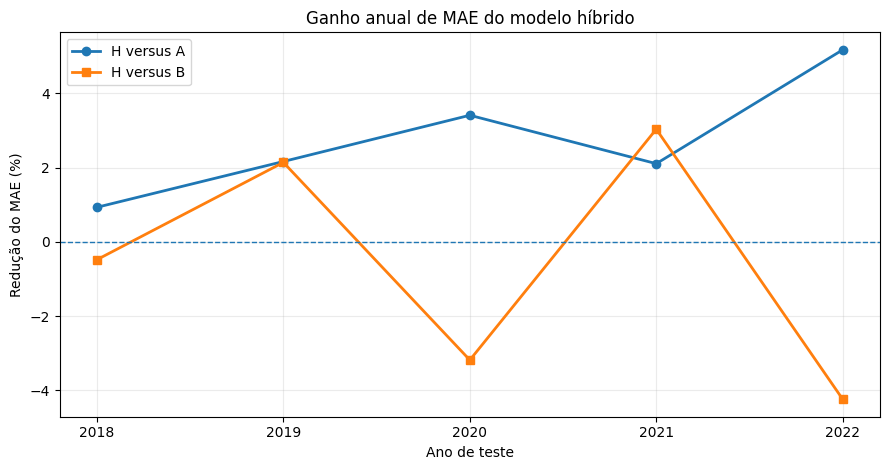

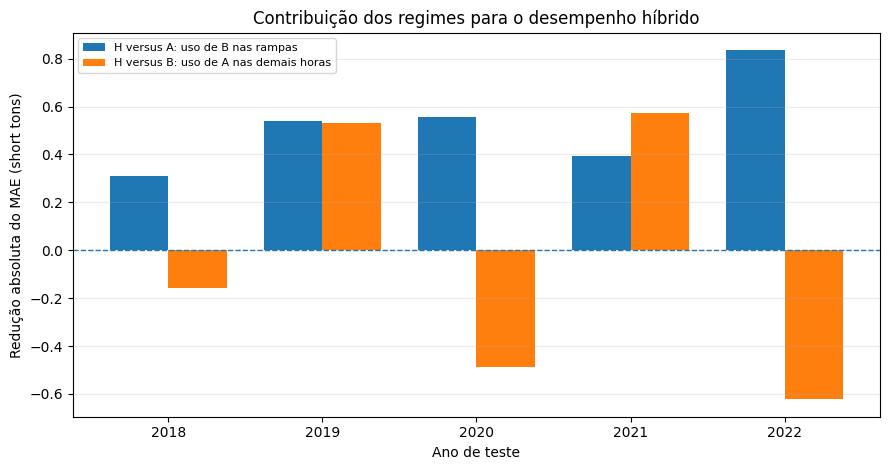


CÉLULA 6 CONCLUÍDA

Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_decomposicao_ganhos_por_ano.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_estabilidade_mensal_hibrido.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A06_ganho_hibrido_por_ano.png
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A06_decomposicao_ganhos_hibrido.png

Análise descritiva concluída, sem retreinamento ou alteração do gate.


In [10]:

# ============================================================
# CÉLULA 6
# DIAGNÓSTICO DA ESTABILIDADE TEMPORAL DO MODELO HÍBRIDO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Investigar por que o modelo híbrido H melhorou o Modelo A
# nos cinco anos avaliados, mas superou o Modelo B somente
# em dois deles.
#
# A análise utiliza exclusivamente as previsões fora da
# amostra produzidas nas Células 4 e 5.
#
# TÉCNICAS UTILIZADAS
# ------------------------------------------------------------
#
# 1. PAIRED ERROR ANALYSIS
#    (Análise pareada de erros)
#
#    Comparação dos erros dos modelos A, B e H sobre as
#    mesmas observações horárias. Esse procedimento permite
#    avaliar as diferenças de desempenho sem introduzir
#    variações decorrentes de conjuntos de teste distintos.
#
# 2. REGIME-CONDITIONAL ERROR DECOMPOSITION
#    (Decomposição dos erros por regime operacional)
#
#    Separação das contribuições das rampas intensas e das
#    demais horas para o desempenho global do modelo híbrido.
#
#    Como H utiliza B nas rampas e A nas demais horas,
#    podemos determinar exatamente quanto cada decisão
#    contribuiu para a redução ou aumento do MAE.
#
# 3. TEMPORAL STABILITY ANALYSIS
#    (Análise da estabilidade temporal)
#
#    Comparação dos ganhos em diferentes anos e meses.
#
#    A análise mensal é descritiva. Meses consecutivos não
#    representam necessariamente observações estatisticamente
#    independentes.
#
# IMPORTANTE
# ------------------------------------------------------------
# Nenhum modelo será retreinado.
# O gate e os limiares P90 permanecerão inalterados.
# Não haverá seleção de parâmetros utilizando os testes.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ============================================================
# 1. VERIFICAÇÃO DOS PRÉ-REQUISITOS
# ============================================================

required_variables = [
    "hybrid_predictions",
    "hybrid_summary",
    "TARGET",
    "TABLES",
    "FIGURES",
    "regression_metrics",
    "error_gain_pct"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Execute as Células 1 a 5 antes desta célula. "
        f"Variáveis ausentes: {missing_variables}"
    )

diagnostic = hybrid_predictions.copy()

required_columns = [
    "target_year",
    "timestamp",
    "intense_ramp",
    TARGET,
    "pred_A",
    "pred_B",
    "pred_H"
]

missing_columns = [
    col for col in required_columns
    if col not in diagnostic.columns
]

if missing_columns:
    raise RuntimeError(
        f"Colunas necessárias ausentes: {missing_columns}"
    )

if diagnostic[required_columns].isna().any().any():
    raise RuntimeError(
        "Existem valores ausentes nas previsões."
    )

if diagnostic.duplicated(
    ["target_year", "timestamp"]
).any():
    raise RuntimeError(
        "Existem timestamps duplicados no mesmo backtest."
    )

diagnostic["timestamp"] = pd.to_datetime(
    diagnostic["timestamp"]
)

if (
    diagnostic["timestamp"].dt.year
    != diagnostic["target_year"]
).any():
    raise RuntimeError(
        "Ano do timestamp incompatível com o ano-alvo."
    )


# ============================================================
# 2. CÁLCULO DOS ERROS ABSOLUTOS PAREADOS
# ============================================================
#
# Absolute Error (AE):
#
#     AE(t) = |y(t) - y_pred(t)|
#
# Diferença pareada de erros:
#
#     d(H,A) = AE_A - AE_H
#     d(H,B) = AE_B - AE_H
#
# Valores positivos indicam redução do erro pelo híbrido.
# Valores negativos indicam deterioração do desempenho.
# ============================================================

for model in ["A", "B", "H"]:

    diagnostic[f"ae_{model}"] = (
        diagnostic[TARGET]
        - diagnostic[f"pred_{model}"]
    ).abs()

diagnostic["d_H_vs_A"] = (
    diagnostic["ae_A"]
    - diagnostic["ae_H"]
)

diagnostic["d_H_vs_B"] = (
    diagnostic["ae_B"]
    - diagnostic["ae_H"]
)


# ============================================================
# 3. DECOMPOSIÇÃO DO MAE POR ANO
# ============================================================
#
# Nas rampas:
#
#     H = B
#
# Fora das rampas:
#
#     H = A
#
# A redução absoluta do MAE de H em relação a A decorre
# exclusivamente das horas classificadas como rampas.
#
# A redução absoluta do MAE de H em relação a B decorre
# exclusivamente das horas classificadas como demais horas.
#
# As contribuições são ponderadas pelo número total de
# observações do respectivo ano.
# ============================================================

decomposition_rows = []

for year, year_df in diagnostic.groupby(
    "target_year",
    sort=True
):

    ramp = year_df["intense_ramp"].astype(bool)

    n = len(year_df)

    if ramp.sum() == 0 or (~ramp).sum() == 0:
        raise RuntimeError(
            f"O ano {year} não contém ambos os regimes."
        )

    mae_a = year_df["ae_A"].mean()
    mae_b = year_df["ae_B"].mean()
    mae_h = year_df["ae_H"].mean()

    # Benefício de utilizar B nas rampas, em relação a A.

    gain_from_ramps = (
        year_df.loc[ramp, "ae_A"].sum()
        - year_df.loc[ramp, "ae_B"].sum()
    ) / n

    # Benefício de utilizar A nas demais horas, em relação a B.

    gain_from_non_ramps = (
        year_df.loc[~ramp, "ae_B"].sum()
        - year_df.loc[~ramp, "ae_A"].sum()
    ) / n

    # Verificação das identidades matemáticas do gate.

    if not np.isclose(
        mae_a - mae_h,
        gain_from_ramps,
        atol=1e-8
    ):
        raise RuntimeError(
            f"Decomposição H versus A inconsistente em {year}."
        )

    if not np.isclose(
        mae_b - mae_h,
        gain_from_non_ramps,
        atol=1e-8
    ):
        raise RuntimeError(
            f"Decomposição H versus B inconsistente em {year}."
        )

    decomposition_rows.append({

        "target_year": int(year),

        "n_test": n,

        "n_ramps": int(ramp.sum()),

        "ramps_pct": 100 * ramp.mean(),

        "MAE_A": mae_a,

        "MAE_B": mae_b,

        "MAE_H": mae_h,

        "MAE_A_ramps": (
            year_df.loc[ramp, "ae_A"].mean()
        ),

        "MAE_B_ramps": (
            year_df.loc[ramp, "ae_B"].mean()
        ),

        "MAE_A_non_ramps": (
            year_df.loc[~ramp, "ae_A"].mean()
        ),

        "MAE_B_non_ramps": (
            year_df.loc[~ramp, "ae_B"].mean()
        ),

        "MAE_reduction_H_vs_A": gain_from_ramps,

        "MAE_reduction_H_vs_B": gain_from_non_ramps,

        "gain_H_vs_A_pct": error_gain_pct(
            mae_a,
            mae_h
        ),

        "gain_H_vs_B_pct": error_gain_pct(
            mae_b,
            mae_h
        )

    })

gain_decomposition = pd.DataFrame(
    decomposition_rows
)


# ============================================================
# 4. ANÁLISE DA ESTABILIDADE MENSAL
# ============================================================
#
# Temporal stratification (estratificação temporal):
#
# Os resultados são separados por mês-calendário para
# verificar se o ganho anual está distribuído ao longo
# do período ou concentrado em determinados meses.
#
# As métricas são calculadas sobre as mesmas observações
# para os três modelos.
#
# Esta análise não constitui um teste formal de
# significância estatística.
# ============================================================

diagnostic["year_month"] = (
    diagnostic["timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_rows = []

for (year, month), month_df in diagnostic.groupby(
    ["target_year", "year_month"],
    sort=True
):

    mae_a = month_df["ae_A"].mean()
    mae_b = month_df["ae_B"].mean()
    mae_h = month_df["ae_H"].mean()

    monthly_rows.append({

        "target_year": int(year),

        "month": month,

        "n_test": len(month_df),

        "n_ramps": int(
            month_df["intense_ramp"].sum()
        ),

        "MAE_A": mae_a,

        "MAE_B": mae_b,

        "MAE_H": mae_h,

        "gain_H_vs_A_pct": error_gain_pct(
            mae_a,
            mae_h
        ),

        "gain_H_vs_B_pct": error_gain_pct(
            mae_b,
            mae_h
        ),

        "H_better_A": bool(
            mae_h < mae_a
        ),

        "H_better_B": bool(
            mae_h < mae_b
        ),

        "H_better_both": bool(
            mae_h < min(mae_a, mae_b)
        )

    })

monthly_stability = pd.DataFrame(
    monthly_rows
)


# ============================================================
# 5. SÍNTESE DA ESTABILIDADE TEMPORAL
# ============================================================
#
# A frequência de vitórias não é suficiente, isoladamente,
# para demonstrar superioridade de um modelo.
#
# Por isso, apresentamos simultaneamente:
#
# - frequência de vitórias;
# - magnitude das reduções de erro;
# - resultados anuais;
# - resultados mensais.
# ============================================================

print("\n" + "=" * 76)

print(
    "CÉLULA 6: DIAGNÓSTICO DA ESTABILIDADE TEMPORAL"
)

print("=" * 76)

print("\nDecomposição dos ganhos por ano:")

display(
    gain_decomposition.round(4)
)

print("\nEstabilidade mensal:")

display(
    monthly_stability.round(4)
)

n_years = len(gain_decomposition)

n_months = len(monthly_stability)

years_h_better_a = int(
    (
        gain_decomposition["MAE_H"]
        < gain_decomposition["MAE_A"]
    ).sum()
)

years_h_better_b = int(
    (
        gain_decomposition["MAE_H"]
        < gain_decomposition["MAE_B"]
    ).sum()
)

years_h_better_both = int(
    (
        gain_decomposition["MAE_H"]
        < gain_decomposition[
            ["MAE_A", "MAE_B"]
        ].min(axis=1)
    ).sum()
)

print("\nSíntese descritiva:")

print(
    f"Anos com H melhor que A: "
    f"{years_h_better_a}/{n_years}"
)

print(
    f"Anos com H melhor que B: "
    f"{years_h_better_b}/{n_years}"
)

print(
    f"Anos com H melhor que ambos: "
    f"{years_h_better_both}/{n_years}"
)

print(
    f"Meses com H melhor que A: "
    f"{int(monthly_stability['H_better_A'].sum())}/{n_months}"
)

print(
    f"Meses com H melhor que B: "
    f"{int(monthly_stability['H_better_B'].sum())}/{n_months}"
)

print(
    f"Meses com H melhor que ambos: "
    f"{int(monthly_stability['H_better_both'].sum())}/{n_months}"
)


# ============================================================
# 6. GRÁFICO: GANHO ANUAL DO MODELO HÍBRIDO
# ============================================================

FIGURES.mkdir(
    parents=True,
    exist_ok=True
)

fig, ax = plt.subplots(
    figsize=(9, 4.8)
)

ax.plot(
    gain_decomposition["target_year"],
    gain_decomposition["gain_H_vs_A_pct"],
    marker="o",
    linewidth=2,
    label="H versus A"
)

ax.plot(
    gain_decomposition["target_year"],
    gain_decomposition["gain_H_vs_B_pct"],
    marker="s",
    linewidth=2,
    label="H versus B"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Ganho anual de MAE do modelo híbrido"
)

ax.set_xlabel(
    "Ano de teste"
)

ax.set_ylabel(
    "Redução do MAE (%)"
)

ax.set_xticks(
    gain_decomposition["target_year"]
)

ax.legend()

ax.grid(
    alpha=0.25
)

fig.tight_layout()

plot_annual = (
    FIGURES
    / "03A06_ganho_hibrido_por_ano.png"
)

fig.savefig(
    plot_annual,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 7. GRÁFICO: CONTRIBUIÇÃO DOS REGIMES OPERACIONAIS
# ============================================================
#
# Este gráfico representa a redução absoluta do MAE
# em relação a cada modelo-base.
#
# Barras positivas indicam benefício da decisão do gate.
# Barras negativas indicam deterioração do desempenho.
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 4.8)
)

x = np.arange(
    len(gain_decomposition)
)

width = 0.38

ax.bar(
    x - width / 2,
    gain_decomposition["MAE_reduction_H_vs_A"],
    width,
    label="H versus A: uso de B nas rampas"
)

ax.bar(
    x + width / 2,
    gain_decomposition["MAE_reduction_H_vs_B"],
    width,
    label="H versus B: uso de A nas demais horas"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(
    x,
    gain_decomposition[
        "target_year"
    ].astype(str)
)

ax.set_xlabel(
    "Ano de teste"
)

ax.set_ylabel(
    "Redução absoluta do MAE (short tons)"
)

ax.set_title(
    "Contribuição dos regimes para o desempenho híbrido"
)

ax.legend(
    fontsize=8
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

plot_components = (
    FIGURES
    / "03A06_decomposicao_ganhos_hibrido.png"
)

fig.savefig(
    plot_components,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 8. EXPORTAÇÃO DOS RESULTADOS
# ============================================================

TABLES.mkdir(
    parents=True,
    exist_ok=True
)

decomposition_path = (
    TABLES
    / "03A06_decomposicao_ganhos_por_ano.csv"
)

monthly_path = (
    TABLES
    / "03A06_estabilidade_mensal_hibrido.csv"
)

gain_decomposition.to_csv(
    decomposition_path,
    index=False
)

monthly_stability.to_csv(
    monthly_path,
    index=False
)


# ============================================================
# 9. ENCERRAMENTO
# ============================================================

print("\n" + "=" * 76)

print("CÉLULA 6 CONCLUÍDA")

print("=" * 76)

print("\nArquivos gerados:")

for path in [
    decomposition_path,
    monthly_path,
    plot_annual,
    plot_components
]:
    print(path)

print(
    "\nAnálise descritiva concluída, "
    "sem retreinamento ou alteração do gate."
)



CÉLULA 7: INCERTEZA DOS GANHOS PAREADOS

Reamostragens por ano: 2,000
Unidade de reamostragem: semana-calendário
Diferença positiva de MAE: menor erro do modelo H

Intervalos bootstrap das diferenças pareadas:


,period,comparison,n_observations,n_week_blocks,mean_paired_MAE_reduction,ci_2_5,ci_97_5,fraction_replicates_positive,interval_category
0,2018,H_vs_A,5287,39,0.3106,0.2067,0.4324,1.0000,positivo em todo o intervalo
1,2018,H_vs_B,5287,39,-0.1574,-0.7123,0.4539,0.2945,inclui zero
2,2019,H_vs_A,7700,52,0.5390,0.3996,0.6954,1.0000,positivo em todo o intervalo
3,2019,H_vs_B,7700,52,0.5328,-0.8680,2.0212,0.7550,inclui zero
4,2020,H_vs_A,6566,48,0.5581,0.3669,0.7625,1.0000,positivo em todo o intervalo
5,2020,H_vs_B,6566,48,-0.4874,-0.8098,-0.2001,0.0000,negativo em todo o intervalo
6,2021,H_vs_A,6703,50,0.3935,0.0506,0.7160,0.9885,positivo em todo o intervalo
7,2021,H_vs_B,6703,50,0.5723,0.0020,1.1349,0.9750,positivo em todo o intervalo
8,2022,H_vs_A,6277,49,0.8351,0.6232,1.0683,1.0000,positivo em todo o intervalo
9,2022,H_vs_B,6277,49,-0.6224,-1.0096,-0.2804,0.0000,negativo em todo o intervalo


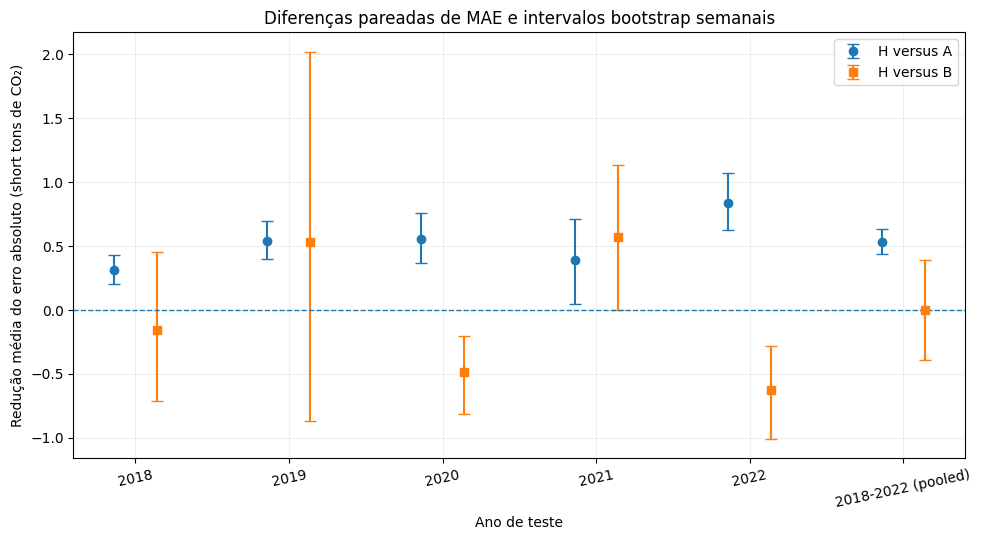


CÉLULA 7 CONCLUÍDA

Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A06_incerteza_ganhos_pareados_bootstrap.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A06_incerteza_ganhos_pareados_bootstrap.png

Interpretação: intervalos exploratórios, sem recalibração dos modelos ou do gate.


In [11]:

# ============================================================
# CÉLULA 7
# INCERTEZA DOS GANHOS PAREADOS DO MODELO HÍBRIDO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar a estabilidade da redução média do erro absoluto do
# híbrido H em relação aos modelos A e B.
#
# TÉCNICAS UTILIZADAS
# ------------------------------------------------------------
#
# 1. PAIRED LOSS DIFFERENTIAL
#    (Diferença pareada de perdas)
#
#    Compara os erros dos modelos sobre as mesmas observações.
#
#    d_HA(t) = |y(t) - A(t)| - |y(t) - H(t)|
#    d_HB(t) = |y(t) - B(t)| - |y(t) - H(t)|
#
#    Diferença positiva significa menor erro do híbrido.
#
# 2. WEEKLY BLOCK BOOTSTRAP
#    (Reamostragem em blocos semanais)
#
#    Reamostra semanas completas, com reposição, dentro de
#    cada ano de teste. Preserva a estrutura de dependência
#    dentro de cada semana, diferentemente do bootstrap
#    independente aplicado diretamente a cada observação.
#
# 3. PERCENTILE BOOTSTRAP INTERVAL
#    (Intervalo percentílico)
#
#    Calcula os percentis 2,5% e 97,5% das reduções médias
#    de erro obtidas nas reamostragens.
#
# 4. STRATIFIED POOLED AGGREGATION
#    (Agregação estratificada)
#
#    Combina as réplicas anuais mantendo o peso original
#    de cada ano no conjunto completo de previsões.
#
# LIMITAÇÕES
# ------------------------------------------------------------
# A dependência entre semanas não é integralmente preservada.
# Os intervalos são exploratórios e condicionados aos anos
# avaliados, não demonstrando generalização para anos futuros.
#
# Nenhum modelo será retreinado.
# Nenhum limiar do gate será modificado.
# Não haverá seleção de regras usando os anos de teste.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 1. VERIFICAÇÃO DOS PRÉ-REQUISITOS
# ============================================================

necessary = [
    "hybrid_predictions",
    "TARGET",
    "TABLES",
    "FIGURES"
]

missing = [
    v for v in necessary
    if v not in globals()
]

if missing:
    raise RuntimeError(
        "Execute as Células 1 a 6 antes desta célula. "
        f"Variáveis ausentes: {missing}"
    )

observations = hybrid_predictions.copy()

fields = [
    "target_year",
    "timestamp",
    TARGET,
    "pred_A",
    "pred_B",
    "pred_H"
]

missing_fields = [
    c for c in fields
    if c not in observations.columns
]

if missing_fields:
    raise RuntimeError(
        f"Colunas ausentes: {missing_fields}"
    )

if observations[fields].isna().any().any():
    raise RuntimeError(
        "Há valores ausentes nas colunas necessárias."
    )

if observations.duplicated(
    ["target_year", "timestamp"]
).any():
    raise RuntimeError(
        "Há timestamps duplicados nos testes."
    )

observations["timestamp"] = pd.to_datetime(
    observations["timestamp"]
)

observations = (
    observations
    .sort_values(["target_year", "timestamp"])
    .reset_index(drop=True)
)

if not observations["timestamp"].dt.year.eq(
    observations["target_year"]
).all():
    raise RuntimeError(
        "O ano-alvo difere do ano dos timestamps."
    )


# ============================================================
# 2. DIFERENÇAS PAREADAS DOS ERROS ABSOLUTOS
# ============================================================
#
# Absolute Error (AE):
#
#     AE(t) = |y(t) - y_pred(t)|
#
# Diferença pareada:
#
#     d_HA(t) = AE_A(t) - AE_H(t)
#     d_HB(t) = AE_B(t) - AE_H(t)
#
# Valores positivos favorecem H.
# Valores negativos favorecem o modelo de referência.
#
# A média dessas diferenças representa a redução absoluta
# do MAE na amostra comum.
# ============================================================

for name in ["A", "B", "H"]:

    observations[f"AE_{name}"] = (
        observations[TARGET]
        - observations[f"pred_{name}"]
    ).abs()

observations["d_HA"] = (
    observations["AE_A"]
    - observations["AE_H"]
)

observations["d_HB"] = (
    observations["AE_B"]
    - observations["AE_H"]
)


# ============================================================
# 3. DEFINIÇÃO DOS BLOCOS TEMPORAIS
# ============================================================
#
# Cada bloco contém todas as observações elegíveis
# pertencentes à mesma semana-calendário.
#
# W-SUN:
# Semana de segunda-feira a domingo.
#
# A reamostragem utiliza blocos inteiros, mantendo o
# pareamento entre os erros dos três modelos.
# ============================================================

observations["week_block"] = (
    observations["timestamp"]
    .dt.to_period("W-SUN")
    .astype(str)
)


# ============================================================
# 4. BOOTSTRAP ESTRATIFICADO POR ANO
# ============================================================
#
# Para cada ano:
#
# 1. Agregar as diferenças dos erros por semana.
# 2. Sortear semanas com reposição.
# 3. Calcular a redução média ponderada pelo número
#    de observações das semanas sorteadas.
# 4. Repetir o procedimento 2.000 vezes.
#
# A mesma seleção de blocos é aplicada às comparações
# H versus A e H versus B.
#
# Isso preserva o desenho pareado do experimento.
# ============================================================

N_REPLICATES = 2000
SEED = 42

rng = np.random.default_rng(SEED)

bootstrap_by_year = {}
reference_year_sizes = {}
rows = []

for year, group in observations.groupby(
    "target_year",
    sort=True
):

    year = int(year)
    year_n = len(group)

    reference_year_sizes[year] = year_n

    weekly = (
        group
        .groupby("week_block", sort=True)
        .agg(
            n=("d_HA", "size"),
            sum_HA=("d_HA", "sum"),
            sum_HB=("d_HB", "sum")
        )
    )

    n_blocks = len(weekly)

    if n_blocks < 8:
        raise RuntimeError(
            f"O ano {year} contém apenas "
            f"{n_blocks} semanas. "
            "A reamostragem seria pouco informativa."
        )

    selection = rng.integers(
        0,
        n_blocks,
        size=(N_REPLICATES, n_blocks)
    )

    weights = weekly["n"].to_numpy(
        dtype=float
    )

    sampled_size = (
        weights[selection]
        .sum(axis=1)
    )

    if (sampled_size <= 0).any():
        raise RuntimeError(
            f"Reamostragem inválida no ano {year}."
        )

    bootstrap_by_year[year] = {}

    comparisons = [
        ("H_vs_A", "d_HA", "sum_HA"),
        ("H_vs_B", "d_HB", "sum_HB")
    ]

    for label, column, sum_column in comparisons:

        weekly_sums = (
            weekly[sum_column]
            .to_numpy(dtype=float)
        )

        simulated = (
            weekly_sums[selection].sum(axis=1)
            / sampled_size
        )

        bootstrap_by_year[year][label] = simulated

        estimate = float(
            group[column].mean()
        )

        low, high = np.quantile(
            simulated,
            [0.025, 0.975]
        )

        rows.append({

            "period": str(year),

            "comparison": label,

            "n_observations": year_n,

            "n_week_blocks": n_blocks,

            "mean_paired_MAE_reduction": estimate,

            "ci_2_5": float(low),

            "ci_97_5": float(high),

            "fraction_replicates_positive": float(
                np.mean(simulated > 0)
            )

        })


# ============================================================
# 5. AGREGAÇÃO GLOBAL ESTRATIFICADA
# ============================================================
#
# Pooled evaluation:
#
# A média global considera todas as observações dos
# cinco anos, mantendo seus pesos originais.
#
# Em cada réplica, os blocos são reamostrados
# independentemente dentro de cada ano.
#
# Isso impede que um ano desapareça completamente
# de uma réplica global.
#
# IMPORTANTE
# ------------------------------------------------------------
# O resultado pooled representa o desempenho conjunto
# das observações estudadas.
#
# Não equivale à validação em um novo ano independente.
# ============================================================

n_all = sum(
    reference_year_sizes.values()
)

comparisons = [
    ("H_vs_A", "d_HA"),
    ("H_vs_B", "d_HB")
]

for label, column in comparisons:

    combined = sum(

        bootstrap_by_year[year][label]
        * reference_year_sizes[year]

        for year in sorted(reference_year_sizes)

    ) / n_all

    low, high = np.quantile(
        combined,
        [0.025, 0.975]
    )

    rows.append({

        "period": "2018-2022 (pooled)",

        "comparison": label,

        "n_observations": n_all,

        "n_week_blocks": int(
            observations.groupby(
                ["target_year", "week_block"]
            ).ngroups
        ),

        "mean_paired_MAE_reduction": float(
            observations[column].mean()
        ),

        "ci_2_5": float(low),

        "ci_97_5": float(high),

        "fraction_replicates_positive": float(
            np.mean(combined > 0)
        )

    })


# ============================================================
# 6. CLASSIFICAÇÃO DESCRITIVA DOS INTERVALOS
# ============================================================
#
# Um intervalo totalmente positivo indica que todas
# as posições compreendidas entre seus limites favorecem H.
#
# Um intervalo totalmente negativo favorece a referência.
#
# Quando o intervalo inclui zero, os resultados bootstrap
# são compatíveis com a ausência de diferença média.
#
# Essas categorias são descritivas e não devem ser
# interpretadas como comprovação definitiva.
# ============================================================

bootstrap_summary = pd.DataFrame(rows)

bootstrap_summary["interval_category"] = np.select(

    [
        bootstrap_summary["ci_2_5"] > 0,
        bootstrap_summary["ci_97_5"] < 0
    ],

    [
        "positivo em todo o intervalo",
        "negativo em todo o intervalo"
    ],

    default="inclui zero"

)


# ============================================================
# 7. APRESENTAÇÃO DOS RESULTADOS
# ============================================================

print("\n" + "=" * 76)

print(
    "CÉLULA 7: INCERTEZA DOS GANHOS PAREADOS"
)

print("=" * 76)

print(
    f"\nReamostragens por ano: "
    f"{N_REPLICATES:,}"
)

print(
    "Unidade de reamostragem: semana-calendário"
)

print(
    "Diferença positiva de MAE: menor erro do modelo H"
)

print(
    "\nIntervalos bootstrap das diferenças pareadas:"
)

display(
    bootstrap_summary.round(4)
)


# ============================================================
# 8. GRÁFICO DOS INTERVALOS DE INCERTEZA
# ============================================================
#
# Interval plot:
#
# Cada ponto representa a diferença média observada
# de erro absoluto.
#
# As barras representam os percentis 2,5% e 97,5%
# das reamostragens.
#
# A linha horizontal em zero representa ausência de
# diferença média entre o híbrido e a referência.
# ============================================================

periods = [
    str(y)
    for y in sorted(reference_year_sizes)
] + [
    "2018-2022 (pooled)"
]

selected = bootstrap_summary.set_index(
    ["period", "comparison"]
)

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

plot_comparisons = [
    ("H_vs_A", -0.14, "o", "H versus A"),
    ("H_vs_B", 0.14, "s", "H versus B")
]

for label, offset, marker, description in plot_comparisons:

    point = np.array([
        selected.loc[
            (p, label),
            "mean_paired_MAE_reduction"
        ]
        for p in periods
    ])

    lo = np.array([
        selected.loc[(p, label), "ci_2_5"]
        for p in periods
    ])

    hi = np.array([
        selected.loc[(p, label), "ci_97_5"]
        for p in periods
    ])

    ax.errorbar(

        np.arange(len(periods)) + offset,

        point,

        yerr=np.vstack([
            point - lo,
            hi - point
        ]),

        fmt=marker,

        capsize=4,

        label=description

    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(
    np.arange(len(periods))
)

ax.set_xticklabels(
    periods,
    rotation=12
)

ax.set_xlabel(
    "Ano de teste"
)

ax.set_ylabel(
    "Redução média do erro absoluto (short tons de CO₂)"
)

ax.set_title(
    "Diferenças pareadas de MAE e intervalos bootstrap semanais"
)

ax.grid(
    alpha=0.2
)

ax.legend()

fig.tight_layout()


# ============================================================
# 9. EXPORTAÇÃO DOS RESULTADOS
# ============================================================

TABLES.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES.mkdir(
    parents=True,
    exist_ok=True
)

output_table = (
    TABLES
    / "03A06_incerteza_ganhos_pareados_bootstrap.csv"
)

output_figure = (
    FIGURES
    / "03A06_incerteza_ganhos_pareados_bootstrap.png"
)

bootstrap_summary.to_csv(
    output_table,
    index=False
)

fig.savefig(
    output_figure,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 10. ENCERRAMENTO
# ============================================================

print("\n" + "=" * 76)

print("CÉLULA 7 CONCLUÍDA")

print("=" * 76)

print("\nArquivos gerados:")

print(output_table)
print(output_figure)

print(
    "\nInterpretação: intervalos exploratórios, "
    "sem recalibração dos modelos ou do gate."
)


In [12]:

# ============================================================
# CÉLULA 8: RELATÓRIO FINAL DO NOTEBOOK 03A.06
# MODELO HÍBRIDO SENSÍVEL AO REGIME OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Consolidar, em um relatório Markdown reproduzível, os
# procedimentos efetivamente executados nas Células 1 a 7
# e seus resultados empíricos.
#
# Esta célula não treina novos modelos, não modifica o gate
# e não introduz novas hipóteses experimentais.
#
# FUNDAMENTAÇÃO METODOLÓGICA
# ------------------------------------------------------------
#
# 1. GRADIENT-BOOSTED REGRESSION TREES (GBRT / XGBOOST)
#
#    Conjunto de árvores de regressão ajustadas
#    sequencialmente para estimar a emissão horária de CO2.
#
# 2. ROLLING-ORIGIN EVALUATION
#    (BACKTESTING TEMPORAL)
#
#    A cada ano-alvo, os modelos são treinados com períodos
#    anteriores e avaliados cronologicamente no ano-alvo.
#
# 3. EARLY STOPPING + FINAL REFIT
#
#    Seleção do número de árvores com validação cronológica,
#    seguida de treinamento final com todo o passado elegível.
#
# 4. DETERMINISTIC HARD GATING
#    (SELEÇÃO CONDICIONAL DE ESPECIALISTAS)
#
#    O modelo H utiliza B nas rampas intensas, identificadas
#    pelo P90 de |delta P| calculado no treinamento, e A nas
#    demais horas.
#
#    Não é uma rede de gating aprendida nem uma combinação
#    ponderada das previsões.
#
# 5. PAIRED LOSS DIFFERENTIAL
#    (DIFERENÇA PAREADA DE PERDAS)
#
#    Comparação dos erros de A, B e H nas mesmas observações.
#
# 6. WEEKLY BLOCK BOOTSTRAP
#
#    Intervalos exploratórios de incerteza obtidos por
#    reamostragem de semanas completas dentro de cada ano.
#
#    A dependência entre semanas não é integralmente
#    preservada.
#
# LIMITES DA INTERPRETAÇÃO
# ------------------------------------------------------------
# A hipótese do híbrido foi motivada por resultados anteriores
# de 2025. Os anos 2018-2022 são backtests retrospectivos,
# não uma validação prospectiva inteiramente cega do projeto.
#
# O modelo usa a carga P(t) da própria hora para estimar CO2(t).
# Isso não equivale automaticamente a prever emissões futuras
# quando a carga ainda é desconhecida.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from IPython.display import Markdown, display


# ============================================================
# 1. VERIFICAÇÃO DAS ESTRUTURAS DAS CÉLULAS ANTERIORES
# ============================================================

required_variables = [
    "hybrid_predictions",
    "hybrid_summary",
    "hybrid_context_summary",
    "hybrid_overall_summary",
    "gain_decomposition",
    "monthly_stability",
    "bootstrap_summary",
    "selection_results_backtests",
    "REPORTS",
    "TABLES",
    "FIGURES",
    "TARGET",
    "FEATURES_A",
    "FEATURES_B",
    "RAMP_QUANTILE",
    "VALIDATION_FRACTION",
    "N_REPLICATES"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Execute as Células 1 a 7 na mesma sessão. "
        f"Variáveis ausentes: {missing_variables}"
    )

n_total = len(hybrid_predictions)

years = sorted(
    int(y)
    for y in hybrid_summary["target_year"].unique()
)

n_years = len(years)

n_ramps = int(
    hybrid_predictions["intense_ramp"].sum()
)

n_months = len(monthly_stability)

if n_total != int(hybrid_summary["n_test"].sum()):
    raise RuntimeError(
        "As contagens de previsões anuais não conferem."
    )

if n_total != int(
    hybrid_overall_summary.iloc[0]["n_predictions"]
):
    raise RuntimeError(
        "A síntese global não confere com a base horária."
    )

bootstrap_total = bootstrap_summary.loc[
    bootstrap_summary["period"].eq("2018-2022 (pooled)")
    & bootstrap_summary["comparison"].eq("H_vs_A"),
    "n_observations"
]

if len(bootstrap_total) != 1:
    raise RuntimeError(
        "Síntese agregada do bootstrap não encontrada."
    )

if n_total != int(bootstrap_total.iloc[0]):
    raise RuntimeError(
        "A amostra do bootstrap não confere."
    )

if set(years) != set(range(2018, 2023)):
    raise RuntimeError(
        f"Anos de backtest inesperados: {years}"
    )


# ============================================================
# 2. FORMATAÇÃO DAS TABELAS EM MARKDOWN
# ============================================================
#
# Markdown table generation:
#
# A função transforma DataFrames em tabelas Markdown.
#
# Os resultados são arredondados somente na apresentação.
# Os valores originais permanecem nos arquivos CSV.
#
# A implementação não depende de pacotes adicionais,
# como tabulate.
# ============================================================

def fmt_md(value, digits=4):

    if isinstance(value, (bool, np.bool_)):
        return "Sim" if value else "Não"

    if pd.isna(value):
        return "NA"

    if isinstance(value, (int, np.integer)):
        return str(int(value))

    if isinstance(value, (float, np.floating)):
        return f"{float(value):.{digits}f}"

    return (
        str(value)
        .replace("|", "\\|")
        .replace("\n", " ")
    )


def md_table(frame, digits=4):

    columns = [
        str(col)
        for col in frame.columns
    ]

    lines = [
        "| " + " | ".join(columns) + " |",
        "| " + " | ".join(
            ["---"] * len(columns)
        ) + " |"
    ]

    for record in frame.itertuples(
        index=False,
        name=None
    ):

        lines.append(
            "| "
            + " | ".join(
                fmt_md(x, digits)
                for x in record
            )
            + " |"
        )

    return "\n".join(lines)


# ============================================================
# 3. RECUPERAÇÃO DAS MÉTRICAS AGREGADAS
# ============================================================
#
# POOLED EVALUATION
# ------------------------------------------------------------
# Considera todas as observações dos cinco anos.
#
# Cada ano contribui proporcionalmente à quantidade
# de observações elegíveis.
#
# YEAR-MEAN EVALUATION
# ------------------------------------------------------------
# Calcula a média dos MAEs anuais.
#
# Cada ano possui o mesmo peso, independentemente
# da quantidade de observações.
#
# As duas avaliações são complementares, mas não
# matematicamente equivalentes.
# ============================================================

all_metrics = hybrid_overall_summary.iloc[0]

mae_a = float(all_metrics["MAE_pooled_A"])
mae_b = float(all_metrics["MAE_pooled_B"])
mae_h = float(all_metrics["MAE_pooled_H"])

rmse_a = float(all_metrics["RMSE_pooled_A"])
rmse_b = float(all_metrics["RMSE_pooled_B"])
rmse_h = float(all_metrics["RMSE_pooled_H"])

gain_ha = float(
    all_metrics["gain_pooled_H_vs_A_pct"]
)

gain_hb = float(
    all_metrics["gain_pooled_H_vs_B_pct"]
)


# ============================================================
# 4. ORGANIZAÇÃO DAS TABELAS EXPERIMENTAIS
# ============================================================

annual_cols = [
    "target_year",
    "n_test",
    "threshold_mw_h",
    "ramps_pct",
    "MAE_A",
    "MAE_B",
    "MAE_H",
    "gain_H_vs_A_MAE_pct",
    "gain_H_vs_B_MAE_pct",
    "RMSE_A",
    "RMSE_B",
    "RMSE_H",
    "R2_A",
    "R2_B",
    "R2_H",
    "Bias_A",
    "Bias_B",
    "Bias_H"
]

annual = hybrid_summary[
    annual_cols
].copy()

annual.columns = [
    "Ano",
    "n",
    "P90 (MW/h)",
    "Rampas (%)",
    "MAE A",
    "MAE B",
    "MAE H",
    "Ganho H/A (%)",
    "Ganho H/B (%)",
    "RMSE A",
    "RMSE B",
    "RMSE H",
    "R² A",
    "R² B",
    "R² H",
    "Bias A",
    "Bias B",
    "Bias H"
]


# ============================================================
# 5. TABELA DE DESEMPENHO POR REGIME OPERACIONAL
# ============================================================

context = hybrid_context_summary[
    [
        "target_year",
        "regime",
        "n",
        "MAE_A",
        "MAE_B",
        "MAE_H",
        "gain_B_vs_A_pct"
    ]
].copy()

context.columns = [
    "Ano",
    "Regime",
    "n",
    "MAE A",
    "MAE B",
    "MAE H",
    "Ganho B/A (%)"
]


# ============================================================
# 6. SELEÇÃO DA COMPLEXIDADE DOS MODELOS
# ============================================================

complexity = selection_results_backtests[
    [
        "target_year",
        "scenario",
        "n_train_selection",
        "n_validation",
        "selected_trees",
        "validation_RMSE"
    ]
].copy()

complexity.columns = [
    "Ano-alvo",
    "Modelo",
    "Treino seleção (n)",
    "Validação (n)",
    "Árvores selecionadas",
    "RMSE validação"
]


# ============================================================
# 7. DECOMPOSIÇÃO DOS GANHOS
# ============================================================
#
# REGIME-CONDITIONAL ERROR DECOMPOSITION
#
# Como H = B nas rampas e H = A nas demais horas:
#
# A vantagem de H sobre A depende exclusivamente
# da contribuição das rampas.
#
# A vantagem de H sobre B depende exclusivamente
# da contribuição das demais horas.
#
# Valores negativos indicam deterioração do MAE.
# ============================================================

components = gain_decomposition[
    [
        "target_year",
        "MAE_reduction_H_vs_A",
        "MAE_reduction_H_vs_B"
    ]
].copy()

components.columns = [
    "Ano",
    "Redução H/A por rampas",
    "Redução H/B por demais horas"
]


# ============================================================
# 8. INTERVALOS BOOTSTRAP
# ============================================================

bootstrap = bootstrap_summary[
    [
        "period",
        "comparison",
        "mean_paired_MAE_reduction",
        "ci_2_5",
        "ci_97_5",
        "interval_category"
    ]
].copy()

bootstrap.columns = [
    "Período",
    "Comparação",
    "Redução média MAE",
    "IC 2,5%",
    "IC 97,5%",
    "Leitura do intervalo"
]


# ============================================================
# 9. SÍNTESE DAS COMPARAÇÕES TEMPORAIS
# ============================================================

monthly_a = int(
    monthly_stability["H_better_A"].sum()
)

monthly_b = int(
    monthly_stability["H_better_B"].sum()
)

monthly_both = int(
    monthly_stability["H_better_both"].sum()
)

yearly_a = int(
    (
        hybrid_summary["MAE_H"]
        < hybrid_summary["MAE_A"]
    ).sum()
)

yearly_b = int(
    (
        hybrid_summary["MAE_H"]
        < hybrid_summary["MAE_B"]
    ).sum()
)

yearly_both = int(
    hybrid_summary["H_best_MAE"].sum()
)


# ============================================================
# 10. COMPORTAMENTO DE B DURANTE RAMPAS INTENSAS
# ============================================================

ramp_context = hybrid_context_summary.loc[
    hybrid_context_summary["regime"].eq(
        "Rampa intensa"
    )
]

all_ramps_favor_b = bool(
    (
        ramp_context["MAE_B"]
        < ramp_context["MAE_A"]
    ).all()
)


# ============================================================
# 11. INTERPRETAÇÃO DOS INTERVALOS AGREGADOS
# ============================================================
#
# PERCENTILE BOOTSTRAP INTERVAL
# ------------------------------------------------------------
# O intervalo [P2.5, P97.5] é construído a partir da
# distribuição empírica das estimativas reamostradas.
#
# Não representa uma garantia sobre períodos futuros.
#
# A presença de zero indica que as reamostragens são
# compatíveis com diferenças médias próximas de zero.
# ============================================================

pooled_ci = bootstrap_summary.loc[
    bootstrap_summary["period"].eq(
        "2018-2022 (pooled)"
    )
].set_index("comparison")

ci_ha = pooled_ci.loc["H_vs_A"]
ci_hb = pooled_ci.loc["H_vs_B"]

if ci_ha["ci_2_5"] > 0:

    interp_a = (
        "O intervalo exploratório agregado de H versus A "
        "permanece inteiramente positivo, compatível com "
        "menor MAE de H nos períodos analisados."
    )

else:

    interp_a = (
        "O intervalo exploratório agregado de H versus A "
        "não permanece inteiramente positivo. O ganho "
        "não se mostrou robusto a esse procedimento "
        "de reamostragem."
    )


if (
    ci_hb["ci_2_5"] <= 0
    <= ci_hb["ci_97_5"]
):

    interp_b = (
        "O intervalo exploratório agregado de H versus B "
        "inclui zero. Os dados não sustentam superioridade "
        "global consistente do híbrido em relação a B."
    )

elif ci_hb["ci_2_5"] > 0:

    interp_b = (
        "O intervalo exploratório agregado de H versus B "
        "permanece positivo nos backtests realizados."
    )

else:

    interp_b = (
        "O intervalo exploratório agregado de H versus B "
        "permanece negativo nos backtests realizados."
    )


if abs(gain_hb) < 0.05:

    comparative_b = (
        "praticamente idêntico ao B no MAE agregado"
    )

elif gain_hb > 0:

    comparative_b = (
        "inferior ao MAE de B no agregado"
    )

else:

    comparative_b = (
        "superior ao MAE de B no agregado"
    )


# ============================================================
# 12. REFERÊNCIAS ÀS FIGURAS EXISTENTES
# ============================================================
#
# As figuras já foram produzidas nas Células 6 e 7.
#
# O relatório utiliza caminhos relativos para manter
# a organização do repositório:
#
# outputs/reports/
# outputs/figures/
#
# Nenhum gráfico novo é produzido nesta célula.
# ============================================================

figure_specs = [
    (
        "Ganho anual do híbrido",
        "03A06_ganho_hibrido_por_ano.png"
    ),
    (
        "Decomposição das contribuições",
        "03A06_decomposicao_ganhos_hibrido.png"
    ),
    (
        "Intervalos bootstrap",
        "03A06_incerteza_ganhos_pareados_bootstrap.png"
    )
]

figure_md = []

for title, filename in figure_specs:

    if (FIGURES / filename).exists():

        figure_md.append(
            f"![{title}](../figures/{filename})"
        )

    else:

        figure_md.append(
            f"*Figura não localizada: `{filename}`.*"
        )


# ============================================================
# 13. CONSTRUÇÃO DO RELATÓRIO MARKDOWN
# ============================================================
#
# SCIENTIFIC REPORTING
# ------------------------------------------------------------
# A estrutura distingue:
#
# - problema investigado;
# - protocolo efetivamente executado;
# - resultados quantitativos;
# - interpretação;
# - limitações;
# - conclusão.
#
# Não são estabelecidos compromissos de novos experimentos.
# ============================================================

report_md = f"""
# Notebook 03A.06: Modelo híbrido sensível ao regime operacional

## 1. Objetivo e delimitação

Avaliar se a seleção condicional entre dois modelos XGBoost melhora a estimativa horária de emissões de CO₂ da **Iatan Unit 2**, em relação ao uso isolado de cada modelo.

O experimento se limita à unidade, aos atributos operacionais e aos anos efetivamente analisados.

A hipótese foi motivada pelos resultados do Notebook 03A.05: a trajetória operacional mostrou benefício localizado em rampas intensas, sem benefício global consistente na avaliação de 2025.

O presente notebook testa uma regra específica, sem pressupor que a hipótese já tenha sido confirmada.

## 2. Base de dados e cenários

- Variável-alvo: `{TARGET}`, massa de CO₂ por registro horário.
- **Cenário A:** XGBoost com {len(FEATURES_A)} variável explicativa, correspondente à carga elétrica da própria hora.
- **Cenário B:** XGBoost com {len(FEATURES_B)} variáveis explicativas, incluindo carga atual, informações defasadas e trajetória operacional.
- **Cenário H:** seleção determinística entre as previsões dos modelos A e B.
- Período de avaliação retrospectiva: **{years[0]} a {years[-1]}**.
- Backtests executados: **{n_years}**.
- Total de observações horárias comuns: **{n_total:,}**.
- Horas classificadas como rampas intensas: **{n_ramps:,}**, correspondentes a **{100*n_ramps/n_total:.2f}%** do conjunto agregado.

A comparação utiliza as mesmas observações elegíveis para os três cenários, evitando diferenças de desempenho decorrentes da utilização de conjuntos de teste incompatíveis.

## 3. Fundamentação metodológica

### 3.1. Gradient-Boosted Regression Trees (XGBoost)

Foi utilizada regressão supervisionada baseada em *gradient boosting*, técnica que combina árvores de decisão ajustadas sequencialmente para melhorar a função preditiva.

Os modelos A e B pertencem à mesma família algorítmica e diferem no conjunto de variáveis explicativas.

O Cenário A representa a hipótese de que a carga elétrica instantânea contém informação suficiente para produzir estimativas competitivas das emissões.

O Cenário B incorpora informações da trajetória operacional para avaliar se a representação temporal acrescenta valor preditivo.

### 3.2. Rolling-origin evaluation (backtesting temporal)

Foram avaliados separadamente os anos-alvo **{', '.join(map(str, years))}**.

Em cada backtest, somente períodos anteriores ao ano-alvo participaram do treinamento e da seleção da complexidade.

Esse procedimento corresponde a uma avaliação retrospectiva com origem temporal progressiva, distinguindo-se de uma divisão aleatória dos registros.

### 3.3. Early stopping e final refit

A seleção do número de árvores empregou os últimos **{100*VALIDATION_FRACTION:.0f}% das observações elegíveis do ano anterior** ao teste como conjunto de validação cronológica.

O mecanismo de *early stopping* permitiu identificar a complexidade de cada modelo a partir da evolução do erro de validação.

Após a seleção, os modelos foram ajustados novamente com todo o passado elegível, procedimento denominado *final refit*.

O número de árvores foi selecionado separadamente para os modelos A e B.

{md_table(complexity, 4)}

### 3.4. Deterministic hard gating

A arquitetura híbrida utiliza uma regra determinística de seleção de especialistas:

```text
Se |ΔP(t)| >= P90 de |ΔP| no treinamento:

    Previsão H(t) = Previsão B(t)

Caso contrário:

    Previsão H(t) = Previsão A(t)
```

O limiar correspondente ao percentil **{RAMP_QUANTILE:.0%}** foi estimado exclusivamente a partir dos dados de treinamento de cada backtest.

A arquitetura é inspirada no conceito de *Mixture of Experts*, mas não utiliza uma rede de gating aprendida nem combina as previsões por médias ponderadas.

Nenhum limiar foi calibrado utilizando as emissões observadas nos anos de teste.

### 3.5. Paired loss differential

A comparação pareada utiliza os erros dos três modelos nas mesmas observações.

Definindo o erro absoluto como:

`AE(t) = |y(t) - y_pred(t)|`

As diferenças de perdas são:

`d_HA(t) = AE_A(t) - AE_H(t)`

`d_HB(t) = AE_B(t) - AE_H(t)`

Valores positivos representam redução do erro absoluto pelo modelo híbrido.

Essa formulação permite determinar a contribuição efetiva das decisões tomadas pelo gate.

### 3.6. Regime-conditional error decomposition

Os resultados foram separados em:

- rampas intensas;
- demais horas de operação.

Como H utiliza B nas rampas e A nas demais horas, é possível decompor exatamente as diferenças de MAE em função de cada regime operacional.

### 3.7. Temporal stability analysis

Foi realizada uma análise descritiva dos ganhos por ano e mês.

Essa estratificação permite observar se os benefícios estão distribuídos temporalmente ou concentrados em determinados períodos.

Os meses não representam necessariamente observações estatisticamente independentes.

### 3.8. Weekly block bootstrap

Foram realizadas **{N_REPLICATES:,} reamostragens** de blocos semanais completos, com reposição dentro de cada ano.

Foram calculados intervalos percentílicos exploratórios de 95% para as reduções médias dos erros absolutos.

A agregação global manteve os pesos originais dos anos.

O procedimento preserva a dependência das observações dentro de cada semana, mas não elimina toda a dependência temporal.

## 4. Resultados anuais

Os valores de MAE e RMSE são apresentados em short tons de CO₂ por observação horária.

Ganhos positivos representam redução do erro pelo modelo híbrido.

{md_table(annual, 4)}

O modelo H apresentou menor MAE que A em **{yearly_a}/{n_years} anos**.

O modelo H apresentou menor MAE que B em **{yearly_b}/{n_years} anos**.

O modelo H superou simultaneamente A e B em **{yearly_both}/{n_years} anos**.

O *bias* corresponde à média de `observado - previsto`. Valores negativos indicam superestimação média, enquanto valores positivos indicam subestimação média.

## 5. Síntese global

| Indicador | A | B | H |
| --- | ---: | ---: | ---: |
| MAE agregado (pooled) | {mae_a:.4f} | {mae_b:.4f} | {mae_h:.4f} |
| RMSE agregado (pooled) | {rmse_a:.4f} | {rmse_b:.4f} | {rmse_h:.4f} |
| Média dos MAEs anuais | {all_metrics['MAE_year_mean_A']:.4f} | {all_metrics['MAE_year_mean_B']:.4f} | {all_metrics['MAE_year_mean_H']:.4f} |

O modelo H apresentou ganho agregado de MAE de **{gain_ha:+.4f}%** em relação ao modelo A.

Em relação ao modelo B, o ganho agregado foi de **{gain_hb:+.4f}%**.

O desempenho agregado do modelo H foi **{comparative_b}**.

A avaliação *pooled* pondera cada ano pela quantidade de observações elegíveis.

A média dos MAEs anuais atribui o mesmo peso a todos os anos.

Essas duas medidas oferecem leituras complementares da estabilidade do desempenho.

## 6. Diagnóstico por regime operacional

{md_table(context, 4)}

A vantagem do Cenário B sobre A durante rampas intensas foi **{'observada nos cinco anos' if all_ramps_favor_b else 'não uniforme entre os anos'}**.

Entretanto, esse resultado não significa que o Cenário B seja necessariamente inferior nas demais condições operacionais.

A decomposição das diferenças de MAE apresenta as contribuições das decisões do gate:

{md_table(components, 4)}

A redução do MAE de H em relação a A decorre exclusivamente da utilização de B durante as rampas intensas.

A diferença de H em relação a B decorre exclusivamente da utilização de A nas demais horas.

Contribuições negativas indicam que a decisão do gate deteriorou o desempenho em relação ao modelo de referência correspondente.

## 7. Estabilidade temporal

Foram analisados **{n_months} meses elegíveis**.

- Meses com H melhor que A: **{monthly_a}/{n_months}**.
- Meses com H melhor que B: **{monthly_b}/{n_months}**.
- Meses com H melhor que ambos: **{monthly_both}/{n_months}**.

Esses resultados são descritivos.

Os meses apresentam quantidades diferentes de observações e não constituem necessariamente réplicas estatisticamente independentes.

A frequência de vitórias não substitui a análise da magnitude das diferenças de erro.

## 8. Incerteza das diferenças pareadas

Os intervalos foram calculados com *weekly block bootstrap*.

Valores positivos representam redução do erro absoluto pelo modelo híbrido.

{md_table(bootstrap, 4)}

### 8.1. Híbrido versus Cenário A

A redução média agregada do MAE foi:

**{ci_ha['mean_paired_MAE_reduction']:+.4f} short tons de CO₂**

Intervalo bootstrap de 95%:

**[{ci_ha['ci_2_5']:.4f}; {ci_ha['ci_97_5']:.4f}]**

{interp_a}

### 8.2. Híbrido versus Cenário B

A redução média agregada do MAE foi:

**{ci_hb['mean_paired_MAE_reduction']:+.4f} short tons de CO₂**

Intervalo bootstrap de 95%:

**[{ci_hb['ci_2_5']:.4f}; {ci_hb['ci_97_5']:.4f}]**

{interp_b}

Os intervalos são exploratórios e não representam garantias de desempenho em períodos futuros.

A fração de reamostragens positivas também não deve ser interpretada como a probabilidade de o modelo ser superior em qualquer ano futuro.

## 9. Limitações

### 9.1. Unidade de estudo

A avaliação foi realizada exclusivamente com dados da Iatan Unit 2.

Os resultados não demonstram generalização para outras unidades termelétricas.

### 9.2. Avaliação retrospectiva

A hipótese do modelo híbrido foi motivada por resultados obtidos anteriormente em 2025.

Os backtests de 2018 a 2022 oferecem evidência retrospectiva sobre o comportamento da estratégia, mas não constituem confirmação prospectiva integralmente cega da pesquisa.

### 9.3. Delimitação histórica

Os anos de 2023 e 2024 não participaram dos backtests, conforme a delimitação metodológica estabelecida nos experimentos anteriores.

A estabilidade do modelo nesses regimes operacionais não foi demonstrada neste notebook.

### 9.4. Regra de seleção

Foi avaliada uma única regra de seleção condicional, baseada no percentil 90 da magnitude da variação horária da carga.

O experimento não demonstra que esse limiar seja ótimo ou que essa seja a única forma adequada de combinar os modelos.

### 9.5. Dependência temporal

A reamostragem em blocos semanais preserva a estrutura interna das semanas, mas não captura integralmente as relações entre semanas consecutivas.

Os intervalos bootstrap devem ser interpretados dentro dessa limitação.

### 9.6. Estimativa contemporânea

Os modelos utilizam a carga elétrica da própria hora prevista.

Consequentemente, as métricas demonstram a capacidade de estimar emissões em períodos temporalmente separados do treinamento, conhecendo as condições operacionais da hora.

Não demonstram automaticamente capacidade de prever emissões com antecedência quando a carga futura ainda é desconhecida.

### 9.7. Observações elegíveis

As métricas foram calculadas sobre a amostra horária comum dos três modelos.

Elas não representam necessariamente todas as horas-calendário da unidade, inclusive períodos sem observações elegíveis.

## 10. Conclusão do Notebook 03A.06

A estratégia híbrida apresentou melhoria do MAE em relação ao Cenário A nos cinco anos avaliados.

Entretanto, não demonstrou superioridade global consistente em relação ao Cenário B.

Os resultados indicam que as informações de trajetória operacional possuem valor preditivo durante rampas intensas.

Contudo, a seleção do modelo A nas demais horas pode descartar previsões vantajosas do modelo B em determinados períodos.

Portanto, os resultados **não sustentam a adoção do modelo híbrido H como solução definitiva**, nem demonstram que o limiar P90 represente a melhor estratégia de seleção entre os especialistas.

A conclusão está limitada aos dados, aos regimes operacionais e ao protocolo experimental efetivamente avaliados.

Não são assumidos compromissos metodológicos de realização de novos experimentos.

## 11. Arquivos gerados

Os resultados utilizados neste relatório foram produzidos nas Células 4 a 7.

### Tabelas

- `outputs/tables/03A06_resultados_modelos_base_backtests.csv`
- `outputs/tables/03A06_resultados_hibrido_backtests.csv`
- `outputs/tables/03A06_resultados_hibrido_por_regime.csv`
- `outputs/tables/03A06_sintese_global_hibrido.csv`
- `outputs/tables/03A06_decomposicao_ganhos_por_ano.csv`
- `outputs/tables/03A06_estabilidade_mensal_hibrido.csv`
- `outputs/tables/03A06_incerteza_ganhos_pareados_bootstrap.csv`

### Previsões horárias

- `data/interim/03A06_regime_hybrid/03A06_previsoes_hibrido_backtests.parquet`

### Figuras

{chr(10).join(figure_md)}
"""


# ============================================================
# 14. SALVAR O RELATÓRIO NO GOOGLE DRIVE
# ============================================================

REPORTS.mkdir(
    parents=True,
    exist_ok=True
)

report_path = (
    REPORTS
    / "03A06_relatorio_modelo_hibrido_regime_operacional.md"
)

report_path.write_text(
    report_md,
    encoding="utf-8"
)


# ============================================================
# 15. VERIFICAÇÃO DO ARQUIVO GERADO
# ============================================================

if not report_path.exists():
    raise RuntimeError(
        "O relatório Markdown não foi criado."
    )

saved_report = report_path.read_text(
    encoding="utf-8"
)

if saved_report != report_md:
    raise RuntimeError(
        "O conteúdo salvo diverge do relatório gerado."
    )


# ============================================================
# 16. SÍNTESE FINAL DA EXECUÇÃO
# ============================================================

print("\n" + "=" * 76)

print(
    "CÉLULA 8: RELATÓRIO FINAL DO NOTEBOOK 03A.06"
)

print("=" * 76)

print(
    f"\nAnos avaliados: {years}"
)

print(
    f"Previsões fora da amostra: {n_total:,}"
)

print(
    f"Vitórias H versus A: {yearly_a}/{n_years} anos"
)

print(
    f"Vitórias H versus B: {yearly_b}/{n_years} anos"
)

print(
    "\nMAE agregado:"
)

print(f"  Modelo A: {mae_a:.4f}")
print(f"  Modelo B: {mae_b:.4f}")
print(f"  Modelo H: {mae_h:.4f}")

print(
    f"\nGanho H versus A: {gain_ha:+.4f}%"
)

print(
    f"Ganho H versus B: {gain_hb:+.4f}%"
)

print(
    "\nRelatório salvo em:"
)

print(report_path)

print(
    "\nNenhum modelo foi retreinado e nenhuma regra "
    "foi modificada."
)


# ============================================================
# 17. EXIBIÇÃO DO RELATÓRIO NO NOTEBOOK
# ============================================================

display(
    Markdown(report_md)
)



CÉLULA 8: RELATÓRIO FINAL DO NOTEBOOK 03A.06

Anos avaliados: [2018, 2019, 2020, 2021, 2022]
Previsões fora da amostra: 32,533
Vitórias H versus A: 5/5 anos
Vitórias H versus B: 2/5 anos

MAE agregado:
  Modelo A: 21.5819
  Modelo B: 21.0489
  Modelo H: 21.0490

Ganho H versus A: +2.4692%
Ganho H versus B: -0.0001%

Relatório salvo em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/reports/03A06_relatorio_modelo_hibrido_regime_operacional.md

Nenhum modelo foi retreinado e nenhuma regra foi modificada.



# Notebook 03A.06: Modelo híbrido sensível ao regime operacional

## 1. Objetivo e delimitação

Avaliar se a seleção condicional entre dois modelos XGBoost melhora a estimativa horária de emissões de CO₂ da **Iatan Unit 2**, em relação ao uso isolado de cada modelo.

O experimento se limita à unidade, aos atributos operacionais e aos anos efetivamente analisados.

A hipótese foi motivada pelos resultados do Notebook 03A.05: a trajetória operacional mostrou benefício localizado em rampas intensas, sem benefício global consistente na avaliação de 2025.

O presente notebook testa uma regra específica, sem pressupor que a hipótese já tenha sido confirmada.

## 2. Base de dados e cenários

- Variável-alvo: `CO2 Mass (short tons)`, massa de CO₂ por registro horário.
- **Cenário A:** XGBoost com 1 variável explicativa, correspondente à carga elétrica da própria hora.
- **Cenário B:** XGBoost com 7 variáveis explicativas, incluindo carga atual, informações defasadas e trajetória operacional.
- **Cenário H:** seleção determinística entre as previsões dos modelos A e B.
- Período de avaliação retrospectiva: **2018 a 2022**.
- Backtests executados: **5**.
- Total de observações horárias comuns: **32,533**.
- Horas classificadas como rampas intensas: **6,473**, correspondentes a **19.90%** do conjunto agregado.

A comparação utiliza as mesmas observações elegíveis para os três cenários, evitando diferenças de desempenho decorrentes da utilização de conjuntos de teste incompatíveis.

## 3. Fundamentação metodológica

### 3.1. Gradient-Boosted Regression Trees (XGBoost)

Foi utilizada regressão supervisionada baseada em *gradient boosting*, técnica que combina árvores de decisão ajustadas sequencialmente para melhorar a função preditiva.

Os modelos A e B pertencem à mesma família algorítmica e diferem no conjunto de variáveis explicativas.

O Cenário A representa a hipótese de que a carga elétrica instantânea contém informação suficiente para produzir estimativas competitivas das emissões.

O Cenário B incorpora informações da trajetória operacional para avaliar se a representação temporal acrescenta valor preditivo.

### 3.2. Rolling-origin evaluation (backtesting temporal)

Foram avaliados separadamente os anos-alvo **2018, 2019, 2020, 2021, 2022**.

Em cada backtest, somente períodos anteriores ao ano-alvo participaram do treinamento e da seleção da complexidade.

Esse procedimento corresponde a uma avaliação retrospectiva com origem temporal progressiva, distinguindo-se de uma divisão aleatória dos registros.

### 3.3. Early stopping e final refit

A seleção do número de árvores empregou os últimos **20% das observações elegíveis do ano anterior** ao teste como conjunto de validação cronológica.

O mecanismo de *early stopping* permitiu identificar a complexidade de cada modelo a partir da evolução do erro de validação.

Após a seleção, os modelos foram ajustados novamente com todo o passado elegível, procedimento denominado *final refit*.

O número de árvores foi selecionado separadamente para os modelos A e B.

| Ano-alvo | Modelo | Treino seleção (n) | Validação (n) | Árvores selecionadas | RMSE validação |
| --- | --- | --- | --- | --- | --- |
| 2018 | A | 49347 | 1701 | 302 | 33.3128 |
| 2018 | B | 49347 | 1701 | 203 | 32.8208 |
| 2019 | A | 55277 | 1058 | 106 | 54.7474 |
| 2019 | B | 55277 | 1058 | 670 | 52.7329 |
| 2020 | A | 62495 | 1540 | 94 | 26.6134 |
| 2020 | B | 62495 | 1540 | 115 | 26.1595 |
| 2021 | A | 69287 | 1314 | 174 | 17.4922 |
| 2021 | B | 69287 | 1314 | 437 | 15.5242 |
| 2022 | A | 75963 | 1341 | 438 | 22.2842 |
| 2022 | B | 75963 | 1341 | 225 | 18.0930 |

### 3.4. Deterministic hard gating

A arquitetura híbrida utiliza uma regra determinística de seleção de especialistas:

```text
Se |ΔP(t)| >= P90 de |ΔP| no treinamento:

    Previsão H(t) = Previsão B(t)

Caso contrário:

    Previsão H(t) = Previsão A(t)
```

O limiar correspondente ao percentil **90%** foi estimado exclusivamente a partir dos dados de treinamento de cada backtest.

A arquitetura é inspirada no conceito de *Mixture of Experts*, mas não utiliza uma rede de gating aprendida nem combina as previsões por médias ponderadas.

Nenhum limiar foi calibrado utilizando as emissões observadas nos anos de teste.

### 3.5. Paired loss differential

A comparação pareada utiliza os erros dos três modelos nas mesmas observações.

Definindo o erro absoluto como:

`AE(t) = |y(t) - y_pred(t)|`

As diferenças de perdas são:

`d_HA(t) = AE_A(t) - AE_H(t)`

`d_HB(t) = AE_B(t) - AE_H(t)`

Valores positivos representam redução do erro absoluto pelo modelo híbrido.

Essa formulação permite determinar a contribuição efetiva das decisões tomadas pelo gate.

### 3.6. Regime-conditional error decomposition

Os resultados foram separados em:

- rampas intensas;
- demais horas de operação.

Como H utiliza B nas rampas e A nas demais horas, é possível decompor exatamente as diferenças de MAE em função de cada regime operacional.

### 3.7. Temporal stability analysis

Foi realizada uma análise descritiva dos ganhos por ano e mês.

Essa estratificação permite observar se os benefícios estão distribuídos temporalmente ou concentrados em determinados períodos.

Os meses não representam necessariamente observações estatisticamente independentes.

### 3.8. Weekly block bootstrap

Foram realizadas **2,000 reamostragens** de blocos semanais completos, com reposição dentro de cada ano.

Foram calculados intervalos percentílicos exploratórios de 95% para as reduções médias dos erros absolutos.

A agregação global manteve os pesos originais dos anos.

O procedimento preserva a dependência das observações dentro de cada semana, mas não elimina toda a dependência temporal.

## 4. Resultados anuais

Os valores de MAE e RMSE são apresentados em short tons de CO₂ por observação horária.

Ganhos positivos representam redução do erro pelo modelo híbrido.

| Ano | n | P90 (MW/h) | Rampas (%) | MAE A | MAE B | MAE H | Ganho H/A (%) | Ganho H/B (%) | RMSE A | RMSE B | RMSE H | R² A | R² B | R² H | Bias A | Bias B | Bias H |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2018 | 5287 | 37.0000 | 9.4950 | 33.3465 | 32.8785 | 33.0359 | 0.9315 | -0.4786 | 38.7665 | 38.2643 | 38.4448 | 0.9219 | 0.9239 | 0.9232 | -32.5746 | -32.3273 | -32.3605 |
| 2019 | 7700 | 37.0000 | 13.7403 | 24.9037 | 24.8975 | 24.3647 | 2.1643 | 2.1399 | 28.9482 | 29.8397 | 28.5003 | 0.9241 | 0.9193 | 0.9264 | -23.9456 | -23.2848 | -23.2530 |
| 2020 | 6566 | 39.0000 | 24.5659 | 16.3688 | 15.3233 | 15.8108 | 3.4093 | -3.1809 | 21.2132 | 19.2979 | 20.1698 | 0.9783 | 0.9820 | 0.9803 | -12.9377 | -10.8607 | -11.5579 |
| 2021 | 6703 | 43.0000 | 25.3319 | 18.6811 | 18.8600 | 18.2876 | 2.1064 | 3.0347 | 24.6190 | 24.0776 | 23.4251 | 0.9831 | 0.9838 | 0.9847 | -0.3191 | -0.4936 | 0.3833 |
| 2022 | 6277 | 49.0000 | 25.5217 | 16.1484 | 14.6909 | 15.3133 | 5.1717 | -4.2368 | 29.1023 | 27.2351 | 27.8268 | 0.9762 | 0.9791 | 0.9782 | -3.1262 | -2.0121 | -2.6863 |

O modelo H apresentou menor MAE que A em **5/5 anos**.

O modelo H apresentou menor MAE que B em **2/5 anos**.

O modelo H superou simultaneamente A e B em **2/5 anos**.

O *bias* corresponde à média de `observado - previsto`. Valores negativos indicam superestimação média, enquanto valores positivos indicam subestimação média.

## 5. Síntese global

| Indicador | A | B | H |
| --- | ---: | ---: | ---: |
| MAE agregado (pooled) | 21.5819 | 21.0489 | 21.0490 |
| RMSE agregado (pooled) | 28.6650 | 28.0430 | 27.8749 |
| Média dos MAEs anuais | 21.8897 | 21.3300 | 21.3625 |

O modelo H apresentou ganho agregado de MAE de **+2.4692%** em relação ao modelo A.

Em relação ao modelo B, o ganho agregado foi de **-0.0001%**.

O desempenho agregado do modelo H foi **praticamente idêntico ao B no MAE agregado**.

A avaliação *pooled* pondera cada ano pela quantidade de observações elegíveis.

A média dos MAEs anuais atribui o mesmo peso a todos os anos.

Essas duas medidas oferecem leituras complementares da estabilidade do desempenho.

## 6. Diagnóstico por regime operacional

| Ano | Regime | n | MAE A | MAE B | MAE H | Ganho B/A (%) |
| --- | --- | --- | --- | --- | --- | --- |
| 2018 | Rampa intensa | 502 | 31.1285 | 27.8571 | 27.8571 | 10.5096 |
| 2018 | Demais horas | 4785 | 33.5792 | 33.4053 | 33.5792 | 0.5178 |
| 2019 | Rampa intensa | 1058 | 21.9748 | 18.0521 | 18.0521 | 17.8509 |
| 2019 | Demais horas | 6642 | 25.3702 | 25.9879 | 25.3702 | -2.4345 |
| 2020 | Rampa intensa | 1613 | 19.2559 | 16.9842 | 16.9842 | 11.7974 |
| 2020 | Demais horas | 4953 | 15.4286 | 14.7825 | 15.4286 | 4.1881 |
| 2021 | Rampa intensa | 1698 | 21.6649 | 20.1116 | 20.1116 | 7.1699 |
| 2021 | Demais horas | 5005 | 17.6688 | 18.4353 | 17.6688 | -4.3382 |
| 2022 | Rampa intensa | 1602 | 18.4745 | 15.2022 | 15.2022 | 17.7126 |
| 2022 | Demais horas | 4675 | 15.3513 | 14.5156 | 15.3513 | 5.4438 |

A vantagem do Cenário B sobre A durante rampas intensas foi **observada nos cinco anos**.

Entretanto, esse resultado não significa que o Cenário B seja necessariamente inferior nas demais condições operacionais.

A decomposição das diferenças de MAE apresenta as contribuições das decisões do gate:

| Ano | Redução H/A por rampas | Redução H/B por demais horas |
| --- | --- | --- |
| 2018 | 0.3106 | -0.1574 |
| 2019 | 0.5390 | 0.5328 |
| 2020 | 0.5581 | -0.4874 |
| 2021 | 0.3935 | 0.5723 |
| 2022 | 0.8351 | -0.6224 |

A redução do MAE de H em relação a A decorre exclusivamente da utilização de B durante as rampas intensas.

A diferença de H em relação a B decorre exclusivamente da utilização de A nas demais horas.

Contribuições negativas indicam que a decisão do gate deteriorou o desempenho em relação ao modelo de referência correspondente.

## 7. Estabilidade temporal

Foram analisados **57 meses elegíveis**.

- Meses com H melhor que A: **50/57**.
- Meses com H melhor que B: **22/57**.
- Meses com H melhor que ambos: **17/57**.

Esses resultados são descritivos.

Os meses apresentam quantidades diferentes de observações e não constituem necessariamente réplicas estatisticamente independentes.

A frequência de vitórias não substitui a análise da magnitude das diferenças de erro.

## 8. Incerteza das diferenças pareadas

Os intervalos foram calculados com *weekly block bootstrap*.

Valores positivos representam redução do erro absoluto pelo modelo híbrido.

| Período | Comparação | Redução média MAE | IC 2,5% | IC 97,5% | Leitura do intervalo |
| --- | --- | --- | --- | --- | --- |
| 2018 | H_vs_A | 0.3106 | 0.2067 | 0.4324 | positivo em todo o intervalo |
| 2018 | H_vs_B | -0.1574 | -0.7123 | 0.4539 | inclui zero |
| 2019 | H_vs_A | 0.5390 | 0.3996 | 0.6954 | positivo em todo o intervalo |
| 2019 | H_vs_B | 0.5328 | -0.8680 | 2.0212 | inclui zero |
| 2020 | H_vs_A | 0.5581 | 0.3669 | 0.7625 | positivo em todo o intervalo |
| 2020 | H_vs_B | -0.4874 | -0.8098 | -0.2001 | negativo em todo o intervalo |
| 2021 | H_vs_A | 0.3935 | 0.0506 | 0.7160 | positivo em todo o intervalo |
| 2021 | H_vs_B | 0.5723 | 0.0020 | 1.1349 | positivo em todo o intervalo |
| 2022 | H_vs_A | 0.8351 | 0.6232 | 1.0683 | positivo em todo o intervalo |
| 2022 | H_vs_B | -0.6224 | -1.0096 | -0.2804 | negativo em todo o intervalo |
| 2018-2022 (pooled) | H_vs_A | 0.5329 | 0.4359 | 0.6351 | positivo em todo o intervalo |
| 2018-2022 (pooled) | H_vs_B | -0.0000 | -0.3870 | 0.3924 | inclui zero |

### 8.1. Híbrido versus Cenário A

A redução média agregada do MAE foi:

**+0.5329 short tons de CO₂**

Intervalo bootstrap de 95%:

**[0.4359; 0.6351]**

O intervalo exploratório agregado de H versus A permanece inteiramente positivo, compatível com menor MAE de H nos períodos analisados.

### 8.2. Híbrido versus Cenário B

A redução média agregada do MAE foi:

**-0.0000 short tons de CO₂**

Intervalo bootstrap de 95%:

**[-0.3870; 0.3924]**

O intervalo exploratório agregado de H versus B inclui zero. Os dados não sustentam superioridade global consistente do híbrido em relação a B.

Os intervalos são exploratórios e não representam garantias de desempenho em períodos futuros.

A fração de reamostragens positivas também não deve ser interpretada como a probabilidade de o modelo ser superior em qualquer ano futuro.

## 9. Limitações

### 9.1. Unidade de estudo

A avaliação foi realizada exclusivamente com dados da Iatan Unit 2.

Os resultados não demonstram generalização para outras unidades termelétricas.

### 9.2. Avaliação retrospectiva

A hipótese do modelo híbrido foi motivada por resultados obtidos anteriormente em 2025.

Os backtests de 2018 a 2022 oferecem evidência retrospectiva sobre o comportamento da estratégia, mas não constituem confirmação prospectiva integralmente cega da pesquisa.

### 9.3. Delimitação histórica

Os anos de 2023 e 2024 não participaram dos backtests, conforme a delimitação metodológica estabelecida nos experimentos anteriores.

A estabilidade do modelo nesses regimes operacionais não foi demonstrada neste notebook.

### 9.4. Regra de seleção

Foi avaliada uma única regra de seleção condicional, baseada no percentil 90 da magnitude da variação horária da carga.

O experimento não demonstra que esse limiar seja ótimo ou que essa seja a única forma adequada de combinar os modelos.

### 9.5. Dependência temporal

A reamostragem em blocos semanais preserva a estrutura interna das semanas, mas não captura integralmente as relações entre semanas consecutivas.

Os intervalos bootstrap devem ser interpretados dentro dessa limitação.

### 9.6. Estimativa contemporânea

Os modelos utilizam a carga elétrica da própria hora prevista.

Consequentemente, as métricas demonstram a capacidade de estimar emissões em períodos temporalmente separados do treinamento, conhecendo as condições operacionais da hora.

Não demonstram automaticamente capacidade de prever emissões com antecedência quando a carga futura ainda é desconhecida.

### 9.7. Observações elegíveis

As métricas foram calculadas sobre a amostra horária comum dos três modelos.

Elas não representam necessariamente todas as horas-calendário da unidade, inclusive períodos sem observações elegíveis.

## 10. Conclusão do Notebook 03A.06

A estratégia híbrida apresentou melhoria do MAE em relação ao Cenário A nos cinco anos avaliados.

Entretanto, não demonstrou superioridade global consistente em relação ao Cenário B.

Os resultados indicam que as informações de trajetória operacional possuem valor preditivo durante rampas intensas.

Contudo, a seleção do modelo A nas demais horas pode descartar previsões vantajosas do modelo B em determinados períodos.

Portanto, os resultados **não sustentam a adoção do modelo híbrido H como solução definitiva**, nem demonstram que o limiar P90 represente a melhor estratégia de seleção entre os especialistas.

A conclusão está limitada aos dados, aos regimes operacionais e ao protocolo experimental efetivamente avaliados.

Não são assumidos compromissos metodológicos de realização de novos experimentos.

## 11. Arquivos gerados

Os resultados utilizados neste relatório foram produzidos nas Células 4 a 7.

### Tabelas

- `outputs/tables/03A06_resultados_modelos_base_backtests.csv`
- `outputs/tables/03A06_resultados_hibrido_backtests.csv`
- `outputs/tables/03A06_resultados_hibrido_por_regime.csv`
- `outputs/tables/03A06_sintese_global_hibrido.csv`
- `outputs/tables/03A06_decomposicao_ganhos_por_ano.csv`
- `outputs/tables/03A06_estabilidade_mensal_hibrido.csv`
- `outputs/tables/03A06_incerteza_ganhos_pareados_bootstrap.csv`

### Previsões horárias

- `data/interim/03A06_regime_hybrid/03A06_previsoes_hibrido_backtests.parquet`

### Figuras

![Ganho anual do híbrido](../figures/03A06_ganho_hibrido_por_ano.png)
![Decomposição das contribuições](../figures/03A06_decomposicao_ganhos_hibrido.png)
![Intervalos bootstrap](../figures/03A06_incerteza_ganhos_pareados_bootstrap.png)


## Referências

CAWLEY, G. C.; TALBOT, N. L. C. On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation. Journal of Machine Learning Research, [s. l.], v. 11, n. 70, p. 2079-2107, 2010. Disponível em: https://jmlr.org/papers/v11/cawley10a.html. Acesso em: 29 out. 2026.

CERQUEIRA, V.; TORGO, L.; MOZETIČ, I. Evaluating time series forecasting models: an empirical study on performance estimation methods. Machine Learning, [s. l.], v. 109, n. 11, p. 1997-2028, 2020. DOI: https://doi.org/10.1007/s10994-020-05910-7. Disponível em: https://link.springer.com/article/10.1007/s10994-020-05910-7. Acesso em: 29 out. 2026.

CHEN, T.; GUESTRIN, C. XGBoost: A Scalable Tree Boosting System. In: ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY AND DATA MINING, 22., 2016, San Francisco. Proceedings [...]. New York: ACM, 2016. p. 785-794. DOI: https://doi.org/10.1145/2939672.2939785. Disponível em: https://www.kdd.org/kdd2016/papers/files/rfp0697-chenAemb.pdf. Versão dos autores consultada: arXiv:1603.02754, https://arxiv.org/abs/1603.02754. Acesso em: 29 out. 2026.

FRIEDMAN, J. H. Greedy function approximation: A gradient boosting machine. The Annals of Statistics, [s. l.], v. 29, n. 5, p. 1189-1232, 2001. DOI: https://doi.org/10.1214/aos/1013203451. Disponível em: https://projecteuclid.org/journals/annals-of-statistics/volume-29/issue-5/Greedy-function-approximation-A-gradient-boosting-machine/10.1214/aos/1013203451.full. Acesso em: 29 out. 2026.

HYNDMAN, R. J.; KOEHLER, A. B. Another look at measures of forecast accuracy. International Journal of Forecasting, [s. l.], v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001. Disponível em: https://robjhyndman.com/publications/another-look-at-measures-of-forecast-accuracy/. Manuscrito dos autores consultado, de 2 nov. 2005: https://robjhyndman.com/papers/mase.pdf, correspondente à publicação de 2006. Acesso em: 29 out. 2026.

JACOBS, R. A.; JORDAN, M. I.; NOWLAN, S. J.; HINTON, G. E. Adaptive Mixtures of Local Experts. Neural Computation, v. 3, n. 1, p. 79-87, 1991. DOI: https://doi.org/10.1162/neco.1991.3.1.79. Disponível em: https://www.cs.toronto.edu/~hinton/absps/jjnh91.pdf. Acesso em: 29 out. 2026.

KÜNSCH, H. R. The Jackknife and the Bootstrap for General Stationary Observations. The Annals of Statistics, v. 17, n. 3, p. 1217-1241, 1989. DOI: https://doi.org/10.1214/aos/1176347265. Acesso em: 29 out. 2026.

SCIKIT-LEARN. User Guide. Version 1.8.0. [S. l.]: The scikit-learn developers, [2025]. Seções MinMaxScaler e Regression metrics. Disponível em: https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.MinMaxScaler.html e https://scikit-learn.org/1.8/modules/model_evaluation.html#regression-metrics. Acesso em: 29 out. 2026.
